# SVR Phase 2 | MARBERTv2 single-task training

I fine-tune one classifier for one voicemail field and seed at a time. I use the frozen train and validation tables and save checkpoints and results to Google Drive.

1. Mount Drive and set paths.
2. Install the team dependencies in an isolated Python 3.11 environment.
3. Validate the snapshot and run a GPU smoke test.
4. Opt in to one training invocation.
5. Assemble finished seeds and compare with TF-IDF.

I upload the reviewed code and frozen inputs to private Drive folders before running setup. See `reports/marbertv2_phase2_report.md` for the exact folder layout, resume procedure, and optional learning-rate sweep.

In [4]:

from pathlib import Path
import shutil

# Source: shared folder from the old account
source = Path("/content/drive/MyDrive/SVR")

# Destination: new account's own My Drive
destination = Path("/content/drive/MyDrive/SVR_NEW")

# Safety checks
assert ".shortcut-targets-by-id" in str(source.resolve()), \
    "Source is not the expected shared shortcut"

assert not destination.exists(), \
    "SVR_NEW already exists. Stop to avoid mixing files."

destination.mkdir(parents=True)

for folder_name in ["phase2-code", "training_data"]:
    src = source / folder_name
    dst = destination / folder_name

    print(f"Copying {folder_name}...")
    shutil.copytree(src, dst)
    print(f"Completed: {folder_name}")

print("\nCOPY COMPLETE")
print("New project:", destination.resolve())


Copying phase2-code...
Completed: phase2-code
Copying training_data...
Completed: training_data

COPY COMPLETE
New project: /content/drive/MyDrive/SVR_NEW


In [5]:

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive")
PROJECT_ROOT = DRIVE / "SVR_NEW"

CODE_ROOT = PROJECT_ROOT / "phase2-code"
TRAIN_CSV = PROJECT_ROOT / "training_data/clean_training_train.csv"
VALIDATION_CSV = PROJECT_ROOT / "training_data/clean_training_val.csv"
CLASS_WEIGHTS = PROJECT_ROOT / "training_data/class_weights.json"

OUTPUT_ROOT = PROJECT_ROOT / "marbertv2-outputs"

SHARED_CONFIG = CODE_ROOT / "notebooks/training/shared_config.json"
ENTRY_POINT = CODE_ROOT / "notebooks/training/marbertv2_phase2.py"

required_files = [
    TRAIN_CSV, VALIDATION_CSV, CLASS_WEIGHTS,
    SHARED_CONFIG, ENTRY_POINT,
    CODE_ROOT / "infra/harness.py",
    CODE_ROOT / "requirements/base.txt",
    CODE_ROOT / "requirements/lama.txt",
]

for path in required_files:
    assert path.is_file(), f"Missing file: {path}"

assert ".shortcut-targets-by-id" not in str(PROJECT_ROOT.resolve()), \
    "STOP: Project still points to a shared shortcut!"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("All required files verified.")
print("PROJECT:", PROJECT_ROOT.resolve())
print("OUTPUT:", OUTPUT_ROOT.resolve())
print("EXISTING RUNS:", list(OUTPUT_ROOT.glob("runs/exp_*")))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All required files verified.
PROJECT: /content/drive/MyDrive/SVR_NEW
OUTPUT: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs
EXISTING RUNS: []


In [6]:
# Isolate the pinned team stack from the Colab kernel packages.
gpu_smoke_ok = False
work = Path("/content/svr-marbertv2")

In [7]:
# Isolate the pinned team stack from the Colab kernel packages.
gpu_smoke_ok = False
work = Path("/content/svr-marbertv2")
work.mkdir(exist_ok=True)
env = dict(os.environ, UV_CACHE_DIR=str(work / "uv-cache"),
           UV_PYTHON_INSTALL_DIR=str(work / "python"), HF_HOME=str(work / "hf-cache"),
           HF_HUB_DISABLE_TELEMETRY="1", TOKENIZERS_PARALLELISM="false")
bootstrap = work / "bootstrap"
subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
                "--target", str(bootstrap), "uv"], env=env, check=True)
uv = bootstrap / "bin/uv"
venv = work / "venv"
subprocess.run([str(uv), "venv", "--allow-existing", "--managed-python", "--python", "3.11", str(venv)],
               env=env, check=True)
python = venv / "bin/python"
subprocess.run([str(uv), "pip", "install", "--python", str(python),
                "-r", str(CODE_ROOT / "requirements/base.txt"),
                "-r", str(CODE_ROOT / "requirements/lama.txt")], env=env, check=True)
env["PYTHONPATH"] = str(CODE_ROOT)

def phase2(action, **options):
    args = [str(python), "-u", str(ENTRY_POINT), action,
            "--shared", str(SHARED_CONFIG), "--train", str(TRAIN_CSV),
            "--validation", str(VALIDATION_CSV), "--weights", str(CLASS_WEIGHTS),
            "--output", str(OUTPUT_ROOT)]
    for name, value in options.items():
        flag = "--" + name.replace("_", "-")
        if value is True:
            args.append(flag)
        elif value is not None and value is not False:
            args.extend([flag, str(value)])
    subprocess.run(args, cwd=work, env=env, check=True)

In [8]:
# If either command fails, I stop and read the original traceback above the subprocess error.
gpu_smoke_ok = False
phase2("check")
phase2("smoke", field="complaint_category", seed=42)
gpu_smoke_ok = True

In [9]:
print("GPU SMOKE TEST:", gpu_smoke_ok)

GPU SMOKE TEST: True


## Train one field and seed

I keep `RUN_ID` fixed across the 20 task/seed pairs for one configuration. I iterate through seeds in order **42, 1337, 2023, 7, 99**, with one invocation per field per seed. Supported fields are `complaint_category`, `complaint_urgency`, `customer_state`, and `churn_risk`. I set `RESUME = True` to continue an interrupted pair from its last completed epoch on the same GPU type and package versions.

In [10]:

artifacts_file = CODE_ROOT / "notebooks/training/marbertv2_artifacts.py"

source = artifacts_file.read_text(encoding="utf-8")

for line in source.splitlines():
    if line.strip().startswith(("MODEL =", "REVISION =")):
        print(line)


MODEL = "UBC-NLP/MARBERTv2"
REVISION = "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8"


In [11]:
import inspect

print(inspect.getsource(phase2))

def phase2(action, **options):
    args = [str(python), "-u", str(ENTRY_POINT), action,
            "--shared", str(SHARED_CONFIG), "--train", str(TRAIN_CSV),
            "--validation", str(VALIDATION_CSV), "--weights", str(CLASS_WEIGHTS),
            "--output", str(OUTPUT_ROOT)]
    for name, value in options.items():
        flag = "--" + name.replace("_", "-")
        if value is True:
            args.append(flag)
        elif value is not None and value is not False:
            args.extend([flag, str(value)])
    subprocess.run(args, cwd=work, env=env, check=True)



In [12]:
from pathlib import Path
import ast

source = Path(ENTRY_POINT).read_text(encoding="utf-8-sig")
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        print(f"{node.name} — line {node.lineno}")

main — line 8


In [13]:
import ast
from pathlib import Path

source = Path(ENTRY_POINT).read_text(encoding="utf-8-sig")
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.FunctionDef) and node.name == "main":
        print(ast.get_source_segment(source, node))

def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("action", choices=["check", "smoke", "train", "finalize"])
    for name in ("shared", "train", "validation", "weights", "output"):
        parser.add_argument(f"--{name}", type=Path, required=True)
    parser.add_argument("--run-id", default="marbertv2-lr2e5")
    parser.add_argument("--field", choices=FIELDS, default=FIELDS[0])
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--learning-rate", type=float, default=2e-5)
    parser.add_argument("--epochs", type=int, default=3)
    parser.add_argument("--reference-run-id")
    parser.add_argument("--resume", action="store_true")
    args = parser.parse_args()

    data = read_inputs(args.shared, args.train, args.validation, args.weights)
    config = configure(data, args.learning_rate, args.epochs)
    if args.seed not in data.shared["experiment_seeds"]:
        parser.error("Select one of the five seeds from shar

In [14]:
from pathlib import Path

checkpoint_dir = (
    Path("/content/drive/MyDrive/SVR/marbertv2-outputs")
    / "runs/exp_marbertv2-lr2e5/checkpoints"
    / "seed_42/complaint_category"
)

print("Checkpoint directory exists:", checkpoint_dir.is_dir())
print("Contents:")
if checkpoint_dir.is_dir():
    for item in sorted(checkpoint_dir.iterdir()):
        print(item.name)

Checkpoint directory exists: True
Contents:
epoch_02
epoch_03
result.json


In [15]:
from pathlib import Path

source = Path(
    "/content/drive/MyDrive/SVR/phase2-code/notebooks/training/marbertv2_train.py"
).read_text(encoding="utf-8-sig")

for i, line in enumerate(source.splitlines(), 1):
    if any(word in line.lower() for word in [
        "already", "exists", "overwrite", "resume", "result.json"
    ]):
        print(f"{i}: {line[:250]}")

1: """Train or resume one MARBERTv2 classification head on a Colab GPU."""
149:     if destination.exists():
150:         raise FileExistsError(destination)
181: def train(data, config, folder, field, seed, resume):
183:     result_path = destination / "result.json"
184:     if result_path.exists():
185:         if resume:
186:             print(f"Already completed {field}/{seed}.")
188:         raise FileExistsError(f"{result_path} already exists. Use a new run ID to rerun.")
191:     if latest and not resume:
192:         raise FileExistsError("Checkpoint exists. Set RESUME=True to continue the same task and seed.")


In [16]:
from pathlib import Path

new_run = (
    Path("/content/drive/MyDrive/SVR/marbertv2-outputs")
    / "runs"
    / "exp_marbertv2-lr2e5-clean-20261118"
)

print("New run exists:", new_run.exists())
print("New run path:", new_run)
print("GPU smoke check passed:", gpu_smoke_ok)

New run exists: True
New run path: /content/drive/MyDrive/SVR/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261118
GPU smoke check passed: True


In [18]:
RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_category"
SEED = 42
LEARNING_RATE = 2e-5
EPOCHS = 3
REFERENCE_RUN_ID = None
RESUME = False
RUN_TRAINING = True

if RUN_TRAINING:
    if not gpu_smoke_ok:
        raise RuntimeError("Complete the frozen-input and GPU smoke checks in this runtime first.")
    phase2("train", run_id=RUN_ID, field=FIELD, seed=SEED,
           learning_rate=LEARNING_RATE, epochs=EPOCHS, resume=RESUME)
else:
    print("Training is off. Set RUN_TRAINING = True for this field and seed.")

In [20]:
from pathlib import Path

run_folder = OUTPUT_ROOT / f"runs/exp_{RUN_ID}"

print("RUN_ID:", RUN_ID)
print("RUN FOLDER:", run_folder)
print("EXISTS:", run_folder.exists())

if run_folder.exists():
    for p in sorted(run_folder.rglob("*")):
        if p.is_file():
            print(
                p.relative_to(run_folder),
                "|",
                round(p.stat().st_size / (1024**2), 2),
                "MB"
            )

RUN_ID: marbertv2-lr2e5-clean-20261119
RUN FOLDER: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119
EXISTS: True
checkpoints/seed_42/complaint_category/epoch_02/config.json | 0.0 MB
checkpoints/seed_42/complaint_category/epoch_02/model.safetensors | 621.25 MB
checkpoints/seed_42/complaint_category/epoch_02/special_tokens_map.json | 0.0 MB
checkpoints/seed_42/complaint_category/epoch_02/state.json | 0.54 MB
checkpoints/seed_42/complaint_category/epoch_02/tokenizer.json | 2.57 MB
checkpoints/seed_42/complaint_category/epoch_02/tokenizer_config.json | 0.0 MB
checkpoints/seed_42/complaint_category/epoch_02/training.pt | 1242.62 MB
checkpoints/seed_42/complaint_category/epoch_02/vocab.txt | 1.05 MB
checkpoints/seed_42/complaint_category/epoch_03/config.json | 0.0 MB
checkpoints/seed_42/complaint_category/epoch_03/model.safetensors | 621.25 MB
checkpoints/seed_42/complaint_category/epoch_03/special_tokens_map.json | 0.0 MB
checkpoints/seed_42/complaint

In [21]:
from pathlib import Path
import shutil
import hashlib
import json

run_folder = OUTPUT_ROOT / f"runs/exp_{RUN_ID}"

source = (
    run_folder / "checkpoints/seed_42/"
    "complaint_category/result.json"
)

backup = (
    Path("/content/drive/MyDrive/SVR_NEW")
    / "artifact-backups"
    / RUN_ID
    / "seed_42"
    / "complaint_category"
    / "result.json"
)

assert source.is_file(), "Training result is missing"

# Validate JSON before copying
with source.open(encoding="utf-8") as f:
    result = json.load(f)

backup.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, backup)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

assert sha256(source) == sha256(backup)

print("RESULT BACKED UP AND VERIFIED")
print("Seed:", 42)
print("Field:", "complaint_category")
print("Backup:", backup)

RESULT BACKED UP AND VERIFIED
Seed: 42
Field: complaint_category
Backup: /content/drive/MyDrive/SVR_NEW/artifact-backups/marbertv2-lr2e5-clean-20261119/seed_42/complaint_category/result.json


In [22]:
from pathlib import Path
import json

output_dir = OUTPUT_ROOT / f"runs/exp_{RUN_ID}"

seed_dir = output_dir / "checkpoints" / "seed_42" / "complaint_category"

print("Experiment directory exists:", output_dir.exists())
print("Seed directory exists:", seed_dir.exists())

if seed_dir.exists():
    print("\nSaved files:")

    for path in sorted(seed_dir.rglob("*")):
        if path.is_file():
            size_mb = path.stat().st_size / (1024 ** 2)
            print(
                path.relative_to(seed_dir),
                "|",
                round(size_mb, 2),
                "MB"
            )

    result_path = seed_dir / "result.json"

    if result_path.exists():
        print("\nTraining results:")
        with result_path.open(encoding="utf-8") as f:
            print(json.dumps(json.load(f), indent=2, ensure_ascii=False))
    else:
        print("\nResult.json not found.")
else:
    print("\nNo saved checkpoint found for this seed.")

Experiment directory exists: True
Seed directory exists: True

Saved files:
epoch_02/config.json | 0.0 MB
epoch_02/model.safetensors | 621.25 MB
epoch_02/special_tokens_map.json | 0.0 MB
epoch_02/state.json | 0.54 MB
epoch_02/tokenizer.json | 2.57 MB
epoch_02/tokenizer_config.json | 0.0 MB
epoch_02/training.pt | 1242.62 MB
epoch_02/vocab.txt | 1.05 MB
epoch_03/config.json | 0.0 MB
epoch_03/model.safetensors | 621.25 MB
epoch_03/special_tokens_map.json | 0.0 MB
epoch_03/state.json | 0.54 MB
epoch_03/tokenizer.json | 2.57 MB
epoch_03/tokenizer_config.json | 0.0 MB
epoch_03/training.pt | 1242.62 MB
epoch_03/vocab.txt | 1.05 MB
result.json | 0.54 MB

Training results:
{
  "field": "complaint_category",
  "config": {
    "model": "UBC-NLP/MARBERTv2",
    "dataset_version": "v2",
    "split": "train",
    "learning_rate": 2e-05,
    "batch_size": 16,
    "epochs": 3,
    "other_hyperparameters": {
      "model_revision": "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8",
      "max_seq_len": 128,
 

In [23]:
import json
from pathlib import Path

result_path = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / "seed_42/complaint_category/result.json"
)

result = json.loads(result_path.read_text(encoding="utf-8"))

print("Seed:", result["config"]["seed"])
print("Best Epoch:", result["best_epoch"])
print("Best Macro F1:", max(
    epoch["macro_f1"] for epoch in result["history"]
))
print("Checkpoint:", result["checkpoint"])

Seed: 42
Best Epoch: 2
Best Macro F1: 0.7921568190023112
Checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/complaint_category/epoch_02


In [24]:

import json

with open(SHARED_CONFIG, encoding="utf-8") as f:
    config = json.load(f)

print("Experiment seeds:", config.get("experiment_seeds"))


Experiment seeds: [42, 1337, 2023, 7, 99]


In [25]:
import subprocess

assert gpu_smoke_ok, "GPU smoke test must pass first"
assert ".shortcut-targets-by-id" not in str(OUTPUT_ROOT.resolve())

FIELD = "complaint_category"
SEED = 1337

result_path = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}/{FIELD}/result.json"
)

assert not result_path.exists(), (
    f"Training already completed for {FIELD}, seed {SEED}. "
    "Do not overwrite it."
)

print("RUN ID:", RUN_ID)
print("FIELD:", FIELD)
print("SEED:", SEED)
print("OUTPUT:", OUTPUT_ROOT)

args = [
    str(python), "-u", str(ENTRY_POINT), "train",
    "--shared", str(SHARED_CONFIG),
    "--train", str(TRAIN_CSV),
    "--validation", str(VALIDATION_CSV),
    "--weights", str(CLASS_WEIGHTS),
    "--output", str(OUTPUT_ROOT),
    "--run-id", RUN_ID,
    "--field", FIELD,
    "--seed", str(SEED),
    "--learning-rate", "2e-5",
    "--epochs", "3",
]

result = subprocess.run(
    args,
    cwd=work,
    env=env,
    capture_output=True,
    text=True,
    check=False
)

print("EXIT CODE:", result.returncode)

if result.returncode == 0:
    print("Training completed successfully.")
    print(result.stdout[-3000:])
else:
    print("TRAINING FAILED:")
    print(result.stdout[-3000:])
    print(result.stderr[-6000:])

RUN ID: marbertv2-lr2e5-clean-20261119
FIELD: complaint_category
SEED: 1337
OUTPUT: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs
EXIT CODE: 0
Training completed successfully.
complaint_category/1337 epoch 1: validation Macro-F1 0.7329; best epoch 1
complaint_category/1337 epoch 2: validation Macro-F1 0.7675; best epoch 2
complaint_category/1337 epoch 3: validation Macro-F1 0.7842; best epoch 3
Saved /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/complaint_category/result.json



In [26]:
from pathlib import Path
import json

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}"
    / "checkpoints/seed_1337/complaint_category"
)

result_path = folder / "result.json"

assert result_path.is_file(), "result.json is missing!"

result = json.loads(result_path.read_text(encoding="utf-8"))

best_epoch = result["best_epoch"]
checkpoint = folder / f"epoch_{best_epoch:02d}"

print("Seed:", result["config"]["seed"])
print("Best Epoch:", best_epoch)
print("Best Macro F1:", max(x["macro_f1"] for x in result["history"]))
print("Model saved:", (checkpoint / "model.safetensors").is_file())
print("Training state saved:", (checkpoint / "training.pt").is_file())
print("Checkpoint:", checkpoint)

Seed: 1337
Best Epoch: 3
Best Macro F1: 0.7841806338280201
Model saved: True
Training state saved: True
Checkpoint: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/complaint_category/epoch_03


In [27]:
assert OUTPUT_ROOT.resolve() == (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
).resolve()

assert not (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints/seed_2023/complaint_category/result.json"
).exists(), "Seed 2023 already completed!"

print("READY: complaint_category / Seed 2023")

READY: complaint_category / Seed 2023


In [28]:
RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_category"
SEED = 2023

print("Seed about to run:", SEED)

LEARNING_RATE = 2e-5
EPOCHS = 3
REFERENCE_RUN_ID = None
RESUME = False
RUN_TRAINING = True

if RUN_TRAINING:
    if not gpu_smoke_ok:
        raise RuntimeError(
            "Complete the frozen-input and GPU smoke checks first."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )
else:
    print("Training is off.")

Seed about to run: 2023


In [29]:
import json
from pathlib import Path

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / "seed_2023/complaint_category"
)

print("Checking:", folder)

if folder.exists():
    print("Saved files:", sorted(p.name for p in folder.iterdir()))

    result_file = folder / "result.json"

    if result_file.exists():
        result = json.loads(result_file.read_text(encoding="utf-8"))

        print("\nTRAINING COMPLETED")
        print("Seed:", result["config"]["seed"])
        print("Best epoch:", result["best_epoch"])

        for epoch in result["history"]:
            print(
                f"Epoch {epoch['epoch']}: "
                f"Macro-F1 = {epoch['macro_f1']:.4f}"
            )

        checkpoint = folder / f"epoch_{result['best_epoch']:02d}"
        print("Model saved:", (checkpoint / "model.safetensors").is_file())
        print("Training state saved:", (checkpoint / "training.pt").is_file())
    else:
        print("\nNo final result.json yet.")
else:
    print("Seed 2023 folder not found.")

Checking: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/complaint_category
Saved files: ['epoch_03', 'result.json']

TRAINING COMPLETED
Seed: 2023
Best epoch: 3
Epoch 1: Macro-F1 = 0.7228
Epoch 2: Macro-F1 = 0.7634
Epoch 3: Macro-F1 = 0.7786
Model saved: True
Training state saved: True


In [30]:
RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_category"
SEED = 7

LEARNING_RATE = 2e-5
EPOCHS = 3
REFERENCE_RUN_ID = None
RESUME = False
RUN_TRAINING = True

assert gpu_smoke_ok, "GPU smoke test did not pass"
assert OUTPUT_ROOT.resolve() == (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
).resolve(), "Wrong output directory!"

result_path = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}/{FIELD}/result.json"
)

assert not result_path.exists(), "Seed 7 already completed!"

print("RUN ID:", RUN_ID)
print("Seed about to run:", SEED)
print("Output:", OUTPUT_ROOT)

if RUN_TRAINING:
    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )
else:
    print("Training is off.")

RUN ID: marbertv2-lr2e5-clean-20261119
Seed about to run: 7
Output: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs


In [31]:
import json
from pathlib import Path

seed = 7

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{seed}/complaint_category"
)

result_file = folder / "result.json"

print("Checking:", folder)

if result_file.exists():
    result = json.loads(result_file.read_text(encoding="utf-8"))

    print(f"\nMARBERTv2 — Seed {seed}")
    print("Best epoch:", result["best_epoch"])

    for epoch in result["history"]:
        print(
            f"Epoch {epoch['epoch']}: "
            f"Macro-F1 = {epoch['macro_f1']:.4f}"
        )

    best_f1 = max(e["macro_f1"] for e in result["history"])
    print(f"\nBEST VALIDATION MACRO-F1: {best_f1:.2%}")

    checkpoint = folder / f"epoch_{result['best_epoch']:02d}"

    print("Model saved:", (checkpoint / "model.safetensors").is_file())
    print("Training state saved:", (checkpoint / "training.pt").is_file())

else:
    print(f"Seed {seed}: result.json not found.")
    print(
        "Saved files:",
        sorted(p.name for p in folder.iterdir())
        if folder.exists() else "No checkpoint folder"
    )

Checking: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_7/complaint_category

MARBERTv2 — Seed 7
Best epoch: 3
Epoch 1: Macro-F1 = 0.7382
Epoch 2: Macro-F1 = 0.7837
Epoch 3: Macro-F1 = 0.7903

BEST VALIDATION MACRO-F1: 79.03%
Model saved: True
Training state saved: True


In [33]:
# ============================================================
# MARBERTv2 — Complaint Category | Seed 99
# SVR Phase 2 | One-Factor-at-a-Time Protocol
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"
RUN_TRAINING = True
FIELD = "complaint_category"
SEED = 99

LEARNING_RATE = 2e-5
EPOCHS = 3

REFERENCE_RUN_ID = None
RESUME = False
RUN_TRAINING = True

print("=" * 55)
print("MARBERTv2 — TRAINING")
print("=" * 55)
print(f"Task:          {FIELD}")
print(f"Seed:          {SEED}")
print(f"Learning Rate: {LEARNING_RATE}")
print(f"Epochs:        {EPOCHS}")
print(f"Run ID:        {RUN_ID}")
print(f"Resume:        {RESUME}")
print("=" * 55)

if RUN_TRAINING:
    if not gpu_smoke_ok:
        raise RuntimeError(
            "Complete the frozen-input and GPU smoke checks "
            "in this runtime first."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    print("\nTraining command finished successfully.")

else:
    print(
        "Training is off. Set RUN_TRAINING = True "
        "to start this field and seed."
    )

MARBERTv2 — TRAINING
Task:          complaint_category
Seed:          99
Learning Rate: 2e-05
Epochs:        3
Run ID:        marbertv2-lr2e5-clean-20261119
Resume:        False

Training command finished successfully.


In [35]:
import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
SEED_TO_CHECK = 99

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED_TO_CHECK}/complaint_category"
)

result_file = folder / "result.json"

print("Checking:", folder)

if result_file.is_file():
    result = json.loads(result_file.read_text(encoding="utf-8"))

    print(f"\nMARBERTv2 — Seed {SEED_TO_CHECK}")
    print("Best epoch:", result["best_epoch"])

    for epoch in result["history"]:
        print(
            f"Epoch {epoch['epoch']}: "
            f"Validation Macro-F1 = {epoch['macro_f1']:.4f}"
        )

    best_f1 = next(
        epoch["macro_f1"]
        for epoch in result["history"]
        if epoch["epoch"] == result["best_epoch"]
    )

    print(f"\nBEST VALIDATION MACRO-F1: {best_f1:.2%}")

    checkpoint = folder / f"epoch_{result['best_epoch']:02d}"

    print("\nCHECKPOINT VERIFICATION")
    print("Model saved:", (checkpoint / "model.safetensors").is_file())
    print("Training state saved:", (checkpoint / "training.pt").is_file())
    print("Validation predictions:", len(result.get("probabilities", {})))

else:
    print("No final result.json found.")
    print(
        "Saved files:",
        sorted(p.name for p in folder.iterdir())
        if folder.exists() else "No checkpoint folder"
    )

Checking: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_99/complaint_category

MARBERTv2 — Seed 99
Best epoch: 3
Epoch 1: Validation Macro-F1 = 0.7460
Epoch 2: Validation Macro-F1 = 0.7908
Epoch 3: Validation Macro-F1 = 0.7909

BEST VALIDATION MACRO-F1: 79.09%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True
Validation predictions: 1003


In [37]:
import json
import hashlib
import shutil
import numpy as np
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_category"
SEEDS = [42, 1337, 2023, 7, 99]

PROJECT = Path("/content/drive/MyDrive/SVR_NEW")

root = (
    PROJECT
    / "marbertv2-outputs"
    / f"runs/exp_{RUN_ID}/checkpoints"
)

backup_root = (
    PROJECT
    / "artifact-backups"
    / RUN_ID
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

scores = []

print("=" * 65)
print("MARBERTv2 — FIVE-SEED VERIFICATION & BACKUP")
print("=" * 65)

# STEP 1 — Verify all results before copying
for seed in SEEDS:
    folder = root / f"seed_{seed}" / FIELD
    result_file = folder / "result.json"

    if not result_file.is_file():
        raise FileNotFoundError(f"Missing result: Seed {seed}")

    result = json.loads(result_file.read_text(encoding="utf-8"))

    if result["config"]["seed"] != seed:
        raise ValueError(f"Seed mismatch: {seed}")

    best_epoch = result["best_epoch"]

    best_f1 = next(
        e["macro_f1"]
        for e in result["history"]
        if e["epoch"] == best_epoch
    )

    checkpoint = folder / f"epoch_{best_epoch:02d}"

    model_ok = (checkpoint / "model.safetensors").is_file()
    training_ok = (checkpoint / "training.pt").is_file()
    prediction_count = len(result.get("probabilities", {}))

    print(
        f"Seed {seed:4d} | "
        f"F1: {best_f1:.4f} | "
        f"Predictions: {prediction_count} | "
        f"Model: {model_ok} | "
        f"Training: {training_ok}"
    )

    if not (model_ok and training_ok):
        raise RuntimeError(f"Incomplete checkpoint: Seed {seed}")

    if prediction_count != 1003:
        raise RuntimeError(
            f"Unexpected prediction count for Seed {seed}: "
            f"{prediction_count}"
        )

    scores.append(best_f1)

# STEP 2 — Back up results and verify SHA-256
print("\nBACKING UP RESULTS")

for seed in SEEDS:
    source = root / f"seed_{seed}" / FIELD / "result.json"

    destination = (
        backup_root
        / f"seed_{seed}"
        / FIELD
        / "result.json"
    )

    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists():
        if sha256(source) != sha256(destination):
            raise RuntimeError(
                f"Existing backup differs for Seed {seed}. "
                "No file was overwritten."
            )
        print(f"Seed {seed}: Existing backup verified")
    else:
        shutil.copy2(source, destination)

        if sha256(source) != sha256(destination):
            raise RuntimeError(f"Backup verification failed: Seed {seed}")

        print(f"Seed {seed}: BACKED UP AND VERIFIED")

# STEP 3 — Summary
print("\n" + "=" * 65)
print("FINAL VALIDATION RESULTS")
print("=" * 65)

print(f"Mean Macro-F1: {np.mean(scores):.4f}")
print(f"Std Macro-F1:  {np.std(scores, ddof=1):.4f}")
print(f"Mean ± Std:    {np.mean(scores):.2%} ± {np.std(scores, ddof=1):.2%}")
print(f"Min Macro-F1:  {np.min(scores):.4f}")
print(f"Max Macro-F1:  {np.max(scores):.4f}")

print("\nALL FIVE SEEDS VERIFIED AND BACKED UP")
print("Backup location:", backup_root)
print("No training executed.")
print("No checkpoints deleted.")

MARBERTv2 — FIVE-SEED VERIFICATION & BACKUP
Seed   42 | F1: 0.7922 | Predictions: 1003 | Model: True | Training: True
Seed 1337 | F1: 0.7842 | Predictions: 1003 | Model: True | Training: True
Seed 2023 | F1: 0.7786 | Predictions: 1003 | Model: True | Training: True
Seed    7 | F1: 0.7903 | Predictions: 1003 | Model: True | Training: True
Seed   99 | F1: 0.7909 | Predictions: 1003 | Model: True | Training: True

BACKING UP RESULTS
Seed 42: Existing backup verified
Seed 1337: Existing backup verified
Seed 2023: Existing backup verified
Seed 7: Existing backup verified
Seed 99: Existing backup verified

FINAL VALIDATION RESULTS
Mean Macro-F1: 0.7872
Std Macro-F1:  0.0057
Mean ± Std:    78.72% ± 0.57%
Min Macro-F1:  0.7786
Max Macro-F1:  0.7922

ALL FIVE SEEDS VERIFIED AND BACKED UP
Backup location: /content/drive/MyDrive/SVR_NEW/artifact-backups/marbertv2-lr2e5-clean-20261119
No training executed.
No checkpoints deleted.


In [38]:
import json
from pathlib import Path

SEED = 99
RUN_ID = "marbertv2-lr2e5-clean-20261119"

result_file = (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}/complaint_category/result.json"
)

if result_file.is_file():
    result = json.loads(result_file.read_text(encoding="utf-8"))

    print(f"MARBERTv2 — Seed {SEED}")
    print("Best epoch:", result["best_epoch"])

    for epoch in result["history"]:
        print(
            f"Epoch {epoch['epoch']}: "
            f"Validation Macro-F1 = {epoch['macro_f1']:.4f}"
        )

    best_f1 = next(
        epoch["macro_f1"]
        for epoch in result["history"]
        if epoch["epoch"] == result["best_epoch"]
    )

    print(f"\nBEST VALIDATION MACRO-F1: {best_f1:.2%}")

else:
    print("Result file not found — check training artifacts.")

MARBERTv2 — Seed 99
Best epoch: 3
Epoch 1: Validation Macro-F1 = 0.7460
Epoch 2: Validation Macro-F1 = 0.7908
Epoch 3: Validation Macro-F1 = 0.7909

BEST VALIDATION MACRO-F1: 79.09%


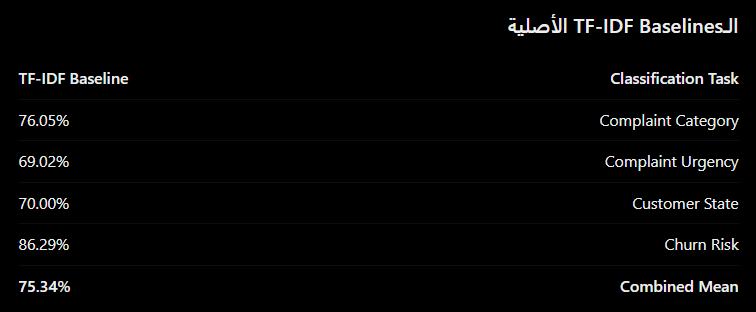

In [39]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ============================================================
# MARBERTv2 — Complaint Category | Multi-Seed Analysis
# READ ONLY — NO TRAINING
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOT = (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
    / f"runs/exp_{RUN_ID}/checkpoints"
)

assert ROOT.is_dir(), f"Results directory not found: {ROOT}"

SEEDS = [42, 1337, 2023, 7, 99]
FIELD = "complaint_category"

# Reference value from the original notebook.
# Verify its source and evaluation protocol before reporting.
BASELINE = 0.7605
BASELINE_VERIFIED = True

records = []
histories = {}

for seed in SEEDS:
    file = ROOT / f"seed_{seed}" / FIELD / "result.json"

    if not file.is_file():
        raise FileNotFoundError(
            f"Missing result.json for Seed {seed}: {file}"
        )

    result = json.loads(file.read_text(encoding="utf-8"))

    history = result["history"]
    best_epoch = result["best_epoch"]

    best_f1 = next(
        h["macro_f1"]
        for h in history
        if h["epoch"] == best_epoch
    )

    records.append({
        "Seed": str(seed),
        "Best Epoch": best_epoch,
        "Macro-F1": best_f1
    })

    histories[str(seed)] = history

df = pd.DataFrame(records)

scores = df["Macro-F1"].to_numpy()

mean = scores.mean()
std = scores.std(ddof=1)

print("=" * 60)
print("MARBERTv2 | COMPLAINT CATEGORY")
print("=" * 60)

print(f"Completed: {len(df)}/{len(SEEDS)} seeds")
print(f"Mean Validation Macro-F1: {mean:.2%}")
print(f"Sample Std: {std:.2%}")
print(f"Mean ± Std: {mean:.2%} ± {std:.2%}")

if BASELINE_VERIFIED:
    print(f"Verified TF-IDF baseline: {BASELINE:.2%}")
else:
    print(f"TF-IDF reference (unverified): {BASELINE:.2%}")

display(
    df.assign(
        **{"Macro-F1 (%)": (df["Macro-F1"] * 100).round(2)}
    )[["Seed", "Best Epoch", "Macro-F1 (%)"]]
)

# ============================================================
# Interactive Visualization
# ============================================================

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Best Validation Macro-F1 by Seed",
        "Validation Macro-F1 Across Epochs"
    ),
    horizontal_spacing=0.13
)

colors = [
    "#9B5DE5",
    "#F15BB5",
    "#00BBF9",
    "#00F5D4",
    "#FEE440"
]

for i, row in df.iterrows():
    seed = row["Seed"]
    color = colors[i % len(colors)]

    fig.add_trace(
        go.Bar(
            x=[seed],
            y=[row["Macro-F1"] * 100],
            name=f"Seed {seed}",
            marker_color=color,
            text=[f'{row["Macro-F1"]:.2%}'],
            textposition="outside",
            showlegend=False,
            hovertemplate=(
                f"Seed {seed}<br>"
                "Macro-F1: %{y:.2f}%<extra></extra>"
            )
        ),
        row=1,
        col=1
    )

    history = histories[seed]

    fig.add_trace(
        go.Scatter(
            x=[h["epoch"] for h in history],
            y=[h["macro_f1"] * 100 for h in history],
            mode="lines+markers",
            name=f"Seed {seed}",
            line=dict(color=color, width=3),
            marker=dict(size=9),
            hovertemplate=(
                "Epoch %{x}<br>"
                "Macro-F1: %{y:.2f}%<extra></extra>"
            )
        ),
        row=1,
        col=2
    )

# Reference lines
if BASELINE_VERIFIED:
    fig.add_hline(
        y=BASELINE * 100,
        line_dash="dash",
        line_color="#FF6B6B",
        line_width=2,
        row=1,
        col=1
    )

fig.add_hline(
    y=mean * 100,
    line_dash="dot",
    line_color="#00D4AA",
    line_width=2,
    row=1,
    col=1
)

fig.update_traces(
    textposition="outside",
    textfont=dict(size=14, color="white"),
    selector=dict(type="bar")
)

fig.update_yaxes(
    title_text="Validation Macro-F1 (%)",
    range=[0, 100],
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Validation Macro-F1 (%)",
    range=[65, 90],
    row=1,
    col=2
)

fig.update_xaxes(
    title_text="Epoch",
    dtick=1,
    row=1,
    col=2
)

fig.update_layout(
    title=dict(
        text=(
            "MARBERTv2 — Multi-Seed Performance Analysis"
            "<br><sup>SVR | Complaint Category | Validation Set</sup>"
        ),
        x=0.5
    ),
    template="plotly_dark",
    height=550,
    width=1250,
    barmode="group",
    font=dict(family="Arial", size=13),
    legend=dict(
        orientation="h",
        y=-0.18,
        x=0.5,
        xanchor="center"
    ),
    margin=dict(t=110, b=100)
)

fig.show()

MARBERTv2 | COMPLAINT CATEGORY
Completed: 5/5 seeds
Mean Validation Macro-F1: 78.72%
Sample Std: 0.57%
Mean ± Std: 78.72% ± 0.57%
Verified TF-IDF baseline: 76.05%


,Seed,Best Epoch,Macro-F1 (%)
0,42,2,79.22
1,1337,3,78.42
2,2023,3,77.86
3,7,3,79.03
4,99,3,79.09


In [40]:
from pathlib import Path
import shutil

PROJECT = Path("/content/drive/MyDrive/SVR_NEW")
OUTPUT_ROOT = PROJECT / "marbertv2-outputs"

total, used, free = shutil.disk_usage("/content/drive")

print(f"Mounted filesystem free space: {free / 1024**3:.2f} GB")
print("Output:", OUTPUT_ROOT.resolve())
print("Output exists:", OUTPUT_ROOT.is_dir())

Mounted filesystem free space: 0.39 GB
Output: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs
Output exists: True


**
Complaint Urgency**

In [41]:
# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# Seed 42 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 42

LEARNING_RATE = 2e-5
EPOCHS = 3

RESUME = False
RUN_TRAINING = True

EXPECTED_OUTPUT = Path(
    "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
)

assert OUTPUT_ROOT.resolve() == EXPECTED_OUTPUT.resolve(), (
    "Wrong Google Drive output directory!"
)

ROOT = OUTPUT_ROOT / f"runs/exp_{RUN_ID}/checkpoints"
folder = ROOT / f"seed_{SEED}" / FIELD

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", folder)
print("=" * 60)

if RUN_TRAINING:

    if not gpu_smoke_ok:
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    # Protect completed and partial checkpoints
    if folder.exists() and any(folder.iterdir()):
        raise FileExistsError(
            f"Existing training artifacts found: {folder}\n"
            "Inspect them before restarting or resuming."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    print("\nTraining command finished successfully.")

else:
    print("Training is disabled.")

MARBERTv2 — COMPLAINT URGENCY TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: complaint_urgency
Seed: 42
Learning Rate: 2e-05
Epochs: 3
Resume: False
Output: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/complaint_urgency

Training command finished successfully.


In [42]:
import json
import hashlib
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 42

PROJECT = Path("/content/drive/MyDrive/SVR_NEW")

folder = (
    PROJECT
    / "marbertv2-outputs"
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY")
print("Seed:", SEED)
print("=" * 60)

if not result_file.is_file():
    print("RESULT NOT FOUND")
    print("Saved files:", sorted(p.name for p in folder.iterdir()) if folder.exists() else [])
else:
    result = json.loads(result_file.read_text(encoding="utf-8"))

    assert result["config"]["seed"] == SEED, "Seed mismatch"
    assert result["field"] == FIELD, "Field mismatch"

    best_epoch = int(result["best_epoch"])

    print("\nTRAINING RESULT FOUND")
    print("Best epoch:", best_epoch)

    print("\nVALIDATION HISTORY")

    for epoch in result["history"]:
        print(
            f"Epoch {epoch['epoch']}: "
            f"Macro-F1 = {epoch['macro_f1']:.4f}"
        )

    best_f1 = next(
        e["macro_f1"]
        for e in result["history"]
        if int(e["epoch"]) == best_epoch
    )

    print(f"\nBEST VALIDATION MACRO-F1: {best_f1:.2%}")

    checkpoint = folder / f"epoch_{best_epoch:02d}"

    model_ok = (checkpoint / "model.safetensors").is_file()
    training_ok = (checkpoint / "training.pt").is_file()
    predictions = len(result.get("probabilities", {}))

    print("\nCHECKPOINT VERIFICATION")
    print("Model saved:", model_ok)
    print("Training state saved:", training_ok)
    print("Validation predictions:", predictions)

    assert model_ok, "Model checkpoint missing"
    assert training_ok, "Training state missing"
    assert predictions == 1003, "Unexpected validation prediction count"

    # Backup result.json only — no checkpoints are moved or deleted
    backup = (
        PROJECT
        / "artifact-backups"
        / RUN_ID
        / f"seed_{SEED}"
        / FIELD
        / "result.json"
    )

    def sha256(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)
        return h.hexdigest()

    backup.parent.mkdir(parents=True, exist_ok=True)

    if not backup.exists():
        shutil.copy2(result_file, backup)

    assert sha256(result_file) == sha256(backup), (
        "Backup mismatch — existing backup was not overwritten"
    )

    print("\nRESULT BACKED UP AND VERIFIED")
    print("Backup:", backup)
    print("No checkpoints deleted.")

MARBERTv2 — COMPLAINT URGENCY
Seed: 42

TRAINING RESULT FOUND
Best epoch: 2

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7004
Epoch 2: Macro-F1 = 0.7168
Epoch 3: Macro-F1 = 0.7149

BEST VALIDATION MACRO-F1: 71.68%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True
Validation predictions: 1003

RESULT BACKED UP AND VERIFIED
Backup: /content/drive/MyDrive/SVR_NEW/artifact-backups/marbertv2-lr2e5-clean-20261119/seed_42/complaint_urgency/result.json
No checkpoints deleted.


In [43]:
import shutil
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SVR_NEW")
OUTPUT_ROOT = PROJECT / "marbertv2-outputs"

total, used, free = shutil.disk_usage("/content/drive")

print(f"Mounted free space: {free / 1024**3:.2f} GB")

for seed in [42, 1337, 2023, 7, 99]:
    folder = (
        OUTPUT_ROOT
        / "runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints"
        / f"seed_{seed}"
    )

    if folder.exists():
        size = sum(
            p.stat().st_size
            for p in folder.rglob("*")
            if p.is_file()
        )
        print(f"Seed {seed}: {size / 1024**3:.2f} GB")

Mounted free space: 0.39 GB
Seed 42: 7.30 GB
Seed 1337: 1.82 GB
Seed 2023: 1.82 GB
Seed 7: 1.82 GB
Seed 99: 1.82 GB


In [46]:
from pathlib import Path
from google.colab import files

source = Path(
    "/content/drive/MyDrive/SVR_NEW/"
    "artifact-backups/"
    "marbertv2-lr2e5-clean-20261119/"
    "seed_42/complaint_urgency/result.json"
)

assert source.is_file(), "Backup file missing!"

print("Downloading:", source)
print("Size:", source.stat().st_size, "bytes")

files.download(str(source))

Downloading: /content/drive/MyDrive/SVR_NEW/artifact-backups/marbertv2-lr2e5-clean-20261119/seed_42/complaint_urgency/result.json
Size: 139736 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
import hashlib
from pathlib import Path

source = Path(
    "/content/drive/MyDrive/SVR_NEW/artifact-backups/"
    "marbertv2-lr2e5-clean-20261119/"
    "seed_42/complaint_urgency/result.json"
)

h = hashlib.sha256(source.read_bytes()).hexdigest()

print("SHA256:", h)

SHA256: 07ebce0bfc08b6e35c211782221ecc0ff8eb53cc66e6ab515ba52c90dbebcd79


In [49]:
from pathlib import Path
import hashlib

root = Path(
    "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/"
    "runs/exp_marbertv2-lr2e5-clean-20261119/"
    "checkpoints/seed_42/complaint_category/epoch_03"
)

for name in ["model.safetensors", "training.pt"]:
    path = root / name

    if not path.is_file():
        print("MISSING:", path)
        continue

    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)

    print(f"{name}: {h.hexdigest()}")

model.safetensors: ea03983c736d329bb801c070165c9c7cffb76cf7056ea2877106b7c16b83efba
training.pt: 9f9cbeb89d54b981c506dca43729ebb4c2992f3aec1b99302727a9925c7abcb2


In [50]:
from pathlib import Path
import hashlib

root = Path(
    "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/"
    "runs/exp_marbertv2-lr2e5-clean-20261119/"
    "checkpoints/seed_42/complaint_category/epoch_03"
)

for path in sorted(root.iterdir()):
    if path.is_file() and path.name not in [
        "model.safetensors", "training.pt"
    ]:
        print(
            path.name,
            hashlib.sha256(path.read_bytes()).hexdigest()
        )

config.json e4c12f72865ec66d6425e87ba59423f95f558cbf230f7304c3bc4f688a82a211
special_tokens_map.json b6d346be366a7d1d48332dbc9fdf3bf8960b5d879522b7799ddba59e76237ee3
state.json 764c7d20c95512ea046f8ec0f5ca48f07653754e4495e995d1d6e755073295b8
tokenizer.json f13ff54560936bb480cce6ce2af0fb87b4d67a6083a94cf91e53001998d1131d
tokenizer_config.json 0088a6f8bcdd4014184fb068b83ebb12896a9db2bb269a71f73de83fef24bceb
vocab.txt 4cbe17fdb035ba4afb5eb9889657b0f9895e2c6bd26574409cf9f8bdf75e2542


In [55]:
from pathlib import Path
import shutil

# Keep the original Drive output path unchanged
ORIGINAL_OUTPUT_ROOT = OUTPUT_ROOT

# Use Colab's temporary disk for new training outputs
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Original output:", ORIGINAL_OUTPUT_ROOT)
print("New output:", OUTPUT_ROOT)
print(
    "Available space:",
    round(shutil.disk_usage(OUTPUT_ROOT).free / 1024**3, 2),
    "GB"
)

Original output: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs
New output: /content/SVR_MARBERTv2_WORK
Available space: 80.42 GB


In [56]:
# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# Seed 1337 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 1337

LEARNING_RATE = 2e-5
EPOCHS = 3

RESUME = False
RUN_TRAINING = True

# Training output: Colab temporary storage
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

if RUN_TRAINING:

    if not gpu_smoke_ok:
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    if result_file.is_file():
        print(
            "Seed already completed. "
            "Training skipped to protect saved results."
        )

    elif folder.exists() and any(folder.iterdir()):
        raise FileExistsError(
            f"Partial or existing artifacts found: {folder}\n"
            "Inspect them before deciding whether to resume."
        )

    else:
        phase2(
            "train",
            run_id=RUN_ID,
            field=FIELD,
            seed=SEED,
            learning_rate=LEARNING_RATE,
            epochs=EPOCHS,
            resume=RESUME
        )

        if not result_file.is_file():
            raise RuntimeError(
                "Training ended without a saved result.json."
            )

        print("\nTraining completed and result.json saved.")

else:
    print("Training is disabled.")

MARBERTv2 — COMPLAINT URGENCY TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: complaint_urgency
Seed: 1337
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Training completed and result.json saved.


In [57]:
# ============================================================
# MARBERTv2 — COMPLAINT URGENCY | SEED 1337
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 1337

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda x: int(x["epoch"])
)

print("\nVALIDATION HISTORY")

for item in history:
    print(
        f"Epoch {int(item['epoch'])}: "
        f"Macro-F1 = {float(item['macro_f1']):.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError("Invalid best_epoch in result.json")

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_saved = (
    checkpoint / "model.safetensors"
).is_file()

training_saved = (
    checkpoint / "training.pt"
).is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")

MARBERTv2 — COMPLAINT URGENCY
SEED 1337 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7072
Epoch 2: Macro-F1 = 0.7256
Epoch 3: Macro-F1 = 0.7289

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 72.89%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [58]:
# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# Seed 2023 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 2023

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

# Colab temporary output — NOT Google Drive
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

if result_file.is_file():
    print("Seed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):
    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect checkpoints before restarting or resuming."
    )

else:
    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")

MARBERTv2 — COMPLAINT URGENCY TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: complaint_urgency
Seed: 2023
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Training completed and result.json saved.


In [59]:
# ============================================================
# MARBERTv2 — COMPLAINT URGENCY | SEED 2023
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 2023

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda x: int(x["epoch"])
)

print("\nVALIDATION HISTORY")

for item in history:
    print(
        f"Epoch {int(item['epoch'])}: "
        f"Macro-F1 = {float(item['macro_f1']):.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_saved = (
    checkpoint / "model.safetensors"
).is_file()

training_saved = (
    checkpoint / "training.pt"
).is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")

MARBERTv2 — COMPLAINT URGENCY
SEED 2023 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.6863
Epoch 2: Macro-F1 = 0.6972
Epoch 3: Macro-F1 = 0.7115

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 71.15%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [60]:
# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# Seed 7 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 7

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

# Temporary Colab storage
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

if result_file.is_file():
    print("Seed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):
    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect checkpoints before restarting or resuming."
    )

else:
    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")

MARBERTv2 — COMPLAINT URGENCY TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: complaint_urgency
Seed: 7
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Training completed and result.json saved.


In [61]:
# ============================================================
# MARBERTv2 — COMPLAINT URGENCY | SEED 7
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 7

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda x: int(x["epoch"])
)

print("\nVALIDATION HISTORY")

for item in history:
    print(
        f"Epoch {int(item['epoch'])}: "
        f"Macro-F1 = {float(item['macro_f1']):.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_saved = (
    checkpoint / "model.safetensors"
).is_file()

training_saved = (
    checkpoint / "training.pt"
).is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")

MARBERTv2 — COMPLAINT URGENCY
SEED 7 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.6850
Epoch 2: Macro-F1 = 0.7140
Epoch 3: Macro-F1 = 0.7286

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 72.86%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [62]:
# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# Seed 99 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 99

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

# Temporary Colab storage
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

if result_file.is_file():
    print("Seed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):
    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect checkpoints before restarting or resuming."
    )

else:
    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")

MARBERTv2 — COMPLAINT URGENCY TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: complaint_urgency
Seed: 99
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Training completed and result.json saved.


In [63]:
# ============================================================
# MARBERTv2 — COMPLAINT URGENCY | SEED 99
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"
SEED = 99

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — COMPLAINT URGENCY")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda x: int(x["epoch"])
)

print("\nVALIDATION HISTORY")

for item in history:
    print(
        f"Epoch {int(item['epoch'])}: "
        f"Macro-F1 = {float(item['macro_f1']):.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_saved = (
    checkpoint / "model.safetensors"
).is_file()

training_saved = (
    checkpoint / "training.pt"
).is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")

MARBERTv2 — COMPLAINT URGENCY
SEED 99 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.6712
Epoch 2: Macro-F1 = 0.7145
Epoch 3: Macro-F1 = 0.7196

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 71.96%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [67]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | COMPLAINT URGENCY
# FINAL FIVE-SEED PERFORMANCE INTELLIGENCE
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ============================================================
# 1. FROZEN EXPERIMENT CONFIGURATION
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "complaint_urgency"

SEEDS = [42, 1337, 2023, 7, 99]
EPOCHS = 3

# Original TF-IDF baseline from the notebook.
# Set to True only after confirming the baseline source,
# dataset split, task and evaluation metric.
BASELINE = 0.6902
BASELINE_VERIFIED = True
DRIVE_ROOT = (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
    / f"runs/exp_{RUN_ID}/checkpoints"
)

COLAB_ROOT = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
)

# ============================================================
# 2. LOAD AND VALIDATE ALL FIVE SEEDS
# ============================================================

records = []
histories = {}

print("=" * 65)
print("MARBERTv2 — COMPLAINT URGENCY")
print("FINAL FIVE-SEED VALIDATION ANALYSIS")
print("=" * 65)

for seed in SEEDS:

    # Seed 42 is on the new Google Drive.
    # The other four seeds are in temporary Colab storage.
    if seed == 42:
        folder = DRIVE_ROOT / f"seed_{seed}" / FIELD
    else:
        folder = COLAB_ROOT / f"seed_{seed}" / FIELD

    result_file = folder / "result.json"

    print(f"\nChecking Seed {seed}")
    print(f"Source: {folder}")

    if not result_file.is_file():
        raise FileNotFoundError(
            f"Missing result for Seed {seed}: {result_file}"
        )

    result = json.loads(
        result_file.read_text(encoding="utf-8")
    )

    history = sorted(
        result["history"],
        key=lambda item: int(item["epoch"])
    )

    best_epoch = int(result["best_epoch"])

    epoch_numbers = [
        int(item["epoch"])
        for item in history
    ]

    if epoch_numbers != list(range(1, EPOCHS + 1)):
        raise ValueError(
            f"Seed {seed}: Unexpected epoch history: "
            f"{epoch_numbers}"
        )

    matches = [
        item for item in history
        if int(item["epoch"]) == best_epoch
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Seed {seed}: Invalid best_epoch"
        )

    best_f1 = float(matches[0]["macro_f1"])

    if not np.isfinite(best_f1) or not 0 <= best_f1 <= 1:
        raise ValueError(
            f"Seed {seed}: Invalid Macro-F1"
        )

    checkpoint = folder / f"epoch_{best_epoch:02d}"

    model_file = checkpoint / "model.safetensors"
    state_file = checkpoint / "training.pt"

    if not model_file.is_file() or not state_file.is_file():
        raise FileNotFoundError(
            f"Seed {seed}: Best checkpoint incomplete"
        )

    records.append({
        "Seed": str(seed),
        "Best Epoch": best_epoch,
        "Best Macro-F1": best_f1,
        "Best Macro-F1 (%)": best_f1 * 100
    })

    histories[str(seed)] = history

    print(
        f"Seed {seed}: "
        f"Epoch {best_epoch} | "
        f"Macro-F1 {best_f1:.2%} | "
        "Checkpoint found"
    )

# ============================================================
# 3. RESEARCH STATISTICS
# ============================================================

df = pd.DataFrame(records)

scores = df["Best Macro-F1"].to_numpy(
    dtype=float
)

mean = float(np.mean(scores))
std = float(np.std(scores, ddof=1))

mean_pct = mean * 100
std_pp = std * 100

completed = len(df)

baseline_pct = BASELINE * 100

gain_pp = (
    mean_pct - baseline_pct
    if BASELINE_VERIFIED
    else None
)

print("\n" + "=" * 65)
print("FINAL VALIDATION RESULTS")
print("=" * 65)

print(f"Completed Seeds: {completed}/{len(SEEDS)}")
print(f"Mean Macro-F1: {mean_pct:.4f}%")
print(f"Sample Std: {std_pp:.4f} percentage points")
print(f"Minimum: {scores.min() * 100:.4f}%")
print(f"Maximum: {scores.max() * 100:.4f}%")

if BASELINE_VERIFIED:
    print(f"TF-IDF Baseline: {baseline_pct:.2f}%")
    print(f"Gain vs Baseline: {gain_pp:+.4f} pp")
else:
    print("TF-IDF Baseline: Not independently verified")
    print("Gain vs Baseline: N/A")

display(
    df[
        [
            "Seed",
            "Best Epoch",
            "Best Macro-F1 (%)"
        ]
    ].style
    .background_gradient(
        subset=["Best Macro-F1 (%)"],
        cmap="PuRd"
    )
    .format({
        "Best Macro-F1 (%)": "{:.2f}%"
    })
)

# ============================================================
# 4. PERFORMANCE HEATMAP DATA
# ============================================================

epoch_labels = list(range(1, EPOCHS + 1))

seed_labels = [
    str(seed) for seed in SEEDS
]

heatmap_data = []

for seed in seed_labels:

    epoch_map = {
        int(item["epoch"]):
            float(item["macro_f1"]) * 100
        for item in histories[seed]
    }

    heatmap_data.append([
        epoch_map[epoch]
        for epoch in epoch_labels
    ])

heatmap_array = np.array(
    heatmap_data,
    dtype=float
)

heatmap_text = [
    [f"{value:.2f}%" for value in row]
    for row in heatmap_array
]

# ============================================================
# 5. SEED RANKING
# ============================================================

ranking = df.sort_values(
    "Best Macro-F1 (%)",
    ascending=False
).reset_index(drop=True)

ranking["Rank"] = np.arange(
    1,
    len(ranking) + 1
)

ranking_colors = [
    "#F472B6",
    "#A78BFA",
    "#22D3EE",
    "#34D399",
    "#FBBF24"
]

# ============================================================
# 6. BUILD PERFORMANCE DASHBOARD
# ============================================================

fig = make_subplots(
    rows=3,
    cols=4,

    specs=[
        [
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "xy"},
            {"type": "indicator"}
        ],
        [
            {"type": "heatmap", "colspan": 4},
            None,
            None,
            None
        ],
        [
            {"type": "xy", "colspan": 4},
            None,
            None,
            None
        ]
    ],

    subplot_titles=(
        "MEAN MACRO-F1",
        "SAMPLE STD",
        (
            "GAIN VS TF-IDF"
            if BASELINE_VERIFIED
            else "BASELINE UNVERIFIED"
        ),
        "COMPLETED SEEDS",
        "PERFORMANCE HEATMAP | VALIDATION",
        "SEED RANKING | BEST VALIDATION MACRO-F1"
    ),

    row_heights=[0.20, 0.39, 0.41],
    vertical_spacing=0.12
)

# ============================================================
# 7. KPI CARDS
# ============================================================

fig.add_trace(
    go.Indicator(
        mode="number",
        value=mean_pct,
        number=dict(
            suffix="%",
            valueformat=".2f",
            font=dict(
                size=34,
                color="#F9A8D4"
            )
        )
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=std_pp,
        number=dict(
            suffix=" pp",
            valueformat=".2f",
            font=dict(
                size=34,
                color="#C4B5FD"
            )
        )
    ),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(
        x=[0.5],
        y=[0.5],
        mode="text",
        text=[
            f"{gain_pp:+.2f} pp"
            if BASELINE_VERIFIED
            else "N/A"
        ],
        textfont=dict(
            size=34,
            color=(
                "#34D399"
                if BASELINE_VERIFIED
                else "#9CA3AF"
            )
        ),
        showlegend=False,
        hoverinfo="skip"
    ),
    row=1, col=3
)

fig.update_xaxes(
    visible=False,
    range=[0, 1],
    row=1, col=3
)

fig.update_yaxes(
    visible=False,
    range=[0, 1],
    row=1, col=3
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=completed,
        number=dict(
            suffix=f"/{len(SEEDS)}",
            valueformat="d",
            font=dict(
                size=34,
                color="#67E8F9"
            )
        )
    ),
    row=1, col=4
)

# ============================================================
# 8. PERFORMANCE HEATMAP
# ============================================================

fig.add_trace(
    go.Heatmap(
        z=heatmap_array,

        x=[
            f"Epoch {epoch}"
            for epoch in epoch_labels
        ],

        y=[
            f"Seed {seed}"
            for seed in seed_labels
        ],

        text=heatmap_text,
        texttemplate="%{text}",

        textfont=dict(
            size=15,
            color="#FFFFFF"
        ),

        colorscale=[
            [0.00, "#312E81"],
            [0.35, "#7C3AED"],
            [0.70, "#DB2777"],
            [1.00, "#F9A8D4"]
        ],

        zmin=0,
        zmax=100,

        colorbar=dict(
            title="F1 (%)",
            len=0.35,
            y=0.50,
            thickness=12
        ),

        hovertemplate=(
            "%{y}<br>"
            "%{x}<br>"
            "Macro-F1: %{z:.2f}%"
            "<extra></extra>"
        )
    ),
    row=2, col=1
)

# ============================================================
# 9. SEED RANKING
# ============================================================

fig.add_trace(
    go.Bar(
        x=ranking["Best Macro-F1 (%)"],

        y=[
            f"#{int(rank)} · Seed {seed}"
            for rank, seed in zip(
                ranking["Rank"],
                ranking["Seed"]
            )
        ],

        orientation="h",

        marker=dict(
            color=ranking_colors[:len(ranking)],
            line=dict(
                color="#FFFFFF",
                width=0.5
            )
        ),

        text=[
            f"{value:.2f}%"
            for value in ranking["Best Macro-F1 (%)"]
        ],

        textposition="outside",

        textfont=dict(
            size=14,
            color="#FFFFFF"
        ),

        showlegend=False,

        hovertemplate=(
            "%{y}<br>"
            "Best Macro-F1: %{x:.2f}%"
            "<extra></extra>"
        )
    ),
    row=3, col=1
)

# ============================================================
# 10. REFERENCE LINES
# ============================================================

reference_lines = [
    (
        mean_pct,
        "MARBERTv2 Mean",
        "#34D399",
        "dot"
    )
]

if BASELINE_VERIFIED:
    reference_lines.insert(
        0,
        (
            baseline_pct,
            "TF-IDF Baseline",
            "#FB7185",
            "dash"
        )
    )

for value, name, color, dash in reference_lines:

    fig.add_trace(
        go.Scatter(
            x=[value, value],
            y=[-0.5, len(ranking) - 0.5],
            mode="lines",
            line=dict(
                color=color,
                width=2,
                dash=dash
            ),
            name=name,
            showlegend=False,
            hoverinfo="skip"
        ),
        row=3, col=1
    )

# ============================================================
# 11. AXES
# ============================================================

fig.update_xaxes(
    title_text="Training Epoch",
    row=2, col=1
)

fig.update_yaxes(
    title_text="Random Seed",
    autorange="reversed",
    row=2, col=1
)

fig.update_xaxes(
    title_text="Validation Macro-F1 (%)",
    range=[0, 100],
    row=3, col=1
)

fig.update_yaxes(
    autorange="reversed",
    row=3, col=1
)

# ============================================================
# 12. ORIGINAL DARK DESIGN
# ============================================================

fig.update_layout(
    title=dict(
        text=(
            "MARBERTv2 | PERFORMANCE INTELLIGENCE"
            "<br><sup>"
            "SVR Research · Complaint Urgency · "
            "Five-Seed Validation Analysis"
            "</sup>"
        ),
        x=0.5,
        xanchor="center",

        font=dict(
            size=24,
            color="#F9A8D4"
        )
    ),

    template="plotly_dark",

    paper_bgcolor="#080D1C",
    plot_bgcolor="#111827",

    font=dict(
        family="Arial",
        size=13,
        color="#E5E7EB"
    ),

    height=1050,
    width=1250,

    margin=dict(
        t=145,
        b=85,
        l=110,
        r=100
    ),

    showlegend=False
)

fig.show()

print("\nFINAL DASHBOARD GENERATED SUCCESSFULLY")
print("Five saved seeds analyzed.")
print("No model was retrained.")


MARBERTv2 — COMPLAINT URGENCY
FINAL FIVE-SEED VALIDATION ANALYSIS

Checking Seed 42
Source: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/complaint_urgency
Seed 42: Epoch 2 | Macro-F1 71.68% | Checkpoint found

Checking Seed 1337
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/complaint_urgency
Seed 1337: Epoch 3 | Macro-F1 72.89% | Checkpoint found

Checking Seed 2023
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/complaint_urgency
Seed 2023: Epoch 3 | Macro-F1 71.15% | Checkpoint found

Checking Seed 7
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_7/complaint_urgency
Seed 7: Epoch 3 | Macro-F1 72.86% | Checkpoint found

Checking Seed 99
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_99/complaint_urgency
Seed 99: Epoch 3 | Macro-F1 

,Seed,Best Epoch,Best Macro-F1 (%)
0,42,2,71.68%
1,1337,3,72.89%
2,2023,3,71.15%
3,7,3,72.86%
4,99,3,71.96%



FINAL DASHBOARD GENERATED SUCCESSFULLY
Five saved seeds analyzed.
No model was retrained.


In [68]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CUSTOMER STATE
# Seed 42 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path
import shutil

# 1. FROZEN CONFIGURATION

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 42

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

# Colab temporary storage
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

# 2. EXPERIMENT INFORMATION

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

# 3. PRE-FLIGHT CHECKS

if not callable(globals().get("phase2")):
    raise RuntimeError(
        "phase2 training function is not available. "
        "Run the setup cells first."
    )

if not globals().get("gpu_smoke_ok", False):
    raise RuntimeError(
        "GPU smoke test must pass before training."
    )

free_gb = shutil.disk_usage("/content").free / (1024 ** 3)

print(f"Available Colab storage: {free_gb:.2f} GB")

if free_gb < 5:
    raise RuntimeError(
        "Less than 5 GB available in temporary storage. "
        "Secure existing checkpoints before training."
    )

# 4. SAFE TRAINING

if result_file.is_file():

    print(
        "\nSeed already completed — "
        "skipping training to protect saved results."
    )

elif folder.exists() and any(folder.iterdir()):

    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect checkpoints before restarting or resuming."
    )

else:

    print("\nStarting Customer State training...\n")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")


MARBERTv2 — CUSTOMER STATE TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: customer_state
Seed: 42
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False
Available Colab storage: 73.12 GB

Starting Customer State training...


Training completed and result.json saved.


In [69]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE | SEED 42
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
import math
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 42

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

folder = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

if not history:
    raise ValueError("Training history is empty.")

print("\nVALIDATION HISTORY")

for item in history:
    epoch = int(item["epoch"])
    macro_f1 = float(item["macro_f1"])

    if not math.isfinite(macro_f1) or not 0 <= macro_f1 <= 1:
        raise ValueError(
            f"Invalid Macro-F1 at epoch {epoch}"
        )

    print(
        f"Epoch {epoch}: Macro-F1 = {macro_f1:.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_file = checkpoint / "model.safetensors"
state_file = checkpoint / "training.pt"

model_saved = model_file.is_file()
training_saved = state_file.is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")


MARBERTv2 — CUSTOMER STATE
SEED 42 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7258
Epoch 2: Macro-F1 = 0.7531
Epoch 3: Macro-F1 = 0.7550

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 75.50%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [70]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CUSTOMER STATE
# Seed 1337 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path
import shutil

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 1337

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

# Temporary Colab storage
OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

# Check whether training already completed
if result_file.is_file():
    print(
        "\nSeed already completed — skipping training."
    )

elif folder.exists() and any(folder.iterdir()):
    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect checkpoints before restarting or resuming."
    )

else:
    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2 is unavailable. Run the setup cells first."
        )

    # Ensure phase2 writes to the intended output directory
    if Path(OUTPUT_ROOT).resolve() != Path(
        "/content/SVR_MARBERTv2_WORK"
    ).resolve():
        raise RuntimeError("Unexpected output directory.")

    free_gb = shutil.disk_usage("/content").free / (1024 ** 3)
    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Insufficient temporary storage for training."
        )

    print("\nStarting Customer State — Seed 1337...\n")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")


MARBERTv2 — CUSTOMER STATE TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: customer_state
Seed: 1337
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Available Colab storage: 70.69 GB

Starting Customer State — Seed 1337...


Training completed and result.json saved.


In [71]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE | SEED 1337
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
import math
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 1337

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

if not history:
    raise ValueError("Training history is empty.")

epoch_numbers = [
    int(item["epoch"])
    for item in history
]

if len(epoch_numbers) != len(set(epoch_numbers)):
    raise ValueError(
        "Duplicate epochs in training history."
    )

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

print("\nVALIDATION HISTORY")

for item in history:
    epoch = int(item["epoch"])
    macro_f1 = float(item["macro_f1"])

    if not math.isfinite(macro_f1) or not 0 <= macro_f1 <= 1:
        raise ValueError(
            f"Invalid Macro-F1 at epoch {epoch}"
        )

    print(
        f"Epoch {epoch}: Macro-F1 = {macro_f1:.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_file = checkpoint / "model.safetensors"
state_file = checkpoint / "training.pt"

model_saved = model_file.is_file()
training_saved = state_file.is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")


MARBERTv2 — CUSTOMER STATE
SEED 1337 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.6609
Epoch 2: Macro-F1 = 0.7212
Epoch 3: Macro-F1 = 0.7432

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 74.32%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [72]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CUSTOMER STATE
# Seed 2023 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path
import shutil

# 1. FROZEN CONFIGURATION

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 2023

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

# 2. EXPERIMENT INFORMATION

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

# 3. SAFE TRAINING

if result_file.is_file():

    print("\nSeed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):

    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect them before restarting or resuming."
    )

else:

    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2 is unavailable. Run the setup cells first."
        )

    if Path(globals().get("OUTPUT_ROOT", "")).resolve() != OUTPUT_ROOT.resolve():
        raise RuntimeError(
            "phase2 output directory does not match "
            "the expected Colab workspace."
        )

    free_gb = shutil.disk_usage("/content").free / (1024 ** 3)
    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Insufficient temporary storage for training."
        )

    print("\nStarting Customer State — Seed 2023...\n")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")


MARBERTv2 — CUSTOMER STATE TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: customer_state
Seed: 2023
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Available Colab storage: 68.87 GB

Starting Customer State — Seed 2023...


Training completed and result.json saved.


In [73]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE | SEED 2023
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
import math
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 2023

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

if not history:
    raise ValueError("Training history is empty.")

epoch_numbers = [
    int(item["epoch"])
    for item in history
]

if len(epoch_numbers) != len(set(epoch_numbers)):
    raise ValueError(
        "Duplicate epochs in training history."
    )

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

print("\nVALIDATION HISTORY")

for item in history:
    epoch = int(item["epoch"])
    macro_f1 = float(item["macro_f1"])

    if not math.isfinite(macro_f1) or not 0 <= macro_f1 <= 1:
        raise ValueError(
            f"Invalid Macro-F1 at epoch {epoch}"
        )

    print(
        f"Epoch {epoch}: Macro-F1 = {macro_f1:.4f}"
    )

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_file = checkpoint / "model.safetensors"
state_file = checkpoint / "training.pt"

model_saved = model_file.is_file()
training_saved = state_file.is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")


MARBERTv2 — CUSTOMER STATE
SEED 2023 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7263
Epoch 2: Macro-F1 = 0.7338
Epoch 3: Macro-F1 = 0.7438

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 74.38%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [74]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CUSTOMER STATE
# Seed 7 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path
import shutil

# 1. FROZEN CONFIGURATION

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 7

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

# 2. EXPERIMENT INFORMATION

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

# 3. SAFE TRAINING

if result_file.is_file():

    print("\nSeed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):

    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect them before restarting or resuming."
    )

else:

    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2 is unavailable. Run the setup cells first."
        )

    # Confirm the notebook is configured for local Colab output
    active_output = globals().get("OUTPUT_ROOT")

    if active_output is None or Path(active_output).resolve() != OUTPUT_ROOT.resolve():
        raise RuntimeError(
            "Unexpected OUTPUT_ROOT. Verify the setup cell "
            "before starting training."
        )

    free_gb = shutil.disk_usage("/content").free / (1024 ** 3)

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Insufficient temporary storage for training."
        )

    print("\nStarting Customer State — Seed 7...\n")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")


MARBERTv2 — CUSTOMER STATE TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: customer_state
Seed: 7
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Available Colab storage: 67.04 GB

Starting Customer State — Seed 7...


Training completed and result.json saved.


In [78]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE | SEED 7
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
import math
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 7

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

if not history:
    raise ValueError("Training history is empty.")

epoch_numbers = [
    int(item["epoch"])
    for item in history
]

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

print("\nVALIDATION HISTORY")

for item in history:
    epoch = int(item["epoch"])
    macro_f1 = float(item["macro_f1"])

    if not math.isfinite(macro_f1) or not 0 <= macro_f1 <= 1:
        raise ValueError(
            f"Invalid Macro-F1 at epoch {epoch}"
        )

    print(f"Epoch {epoch}: Macro-F1 = {macro_f1:.4f}")

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_file = checkpoint / "model.safetensors"
state_file = checkpoint / "training.pt"

model_saved = model_file.is_file()
training_saved = state_file.is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")


MARBERTv2 — CUSTOMER STATE
SEED 7 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7319
Epoch 2: Macro-F1 = 0.7427
Epoch 3: Macro-F1 = 0.7426

BEST RESULT
Best Epoch: 2
Best Validation Macro-F1: 74.27%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [79]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CUSTOMER STATE
# Seed 99 | Frozen Experiment Protocol
# ============================================================

from pathlib import Path
import shutil

# 1. FROZEN CONFIGURATION

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 99

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / f"runs/exp_{RUN_ID}/checkpoints"
)

folder = ROOT / f"seed_{SEED}" / FIELD
result_file = folder / "result.json"

# 2. EXPERIMENT INFORMATION

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE TRAINING")
print("=" * 60)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Output:", OUTPUT_ROOT)
print("Resume:", RESUME)
print("=" * 60)

# 3. SAFE TRAINING

if result_file.is_file():

    print("\nSeed already completed — skipping training.")

elif folder.exists() and any(folder.iterdir()):

    raise FileExistsError(
        f"Existing training artifacts found: {folder}\n"
        "Inspect them before restarting or resuming."
    )

else:

    if not globals().get("gpu_smoke_ok", False):
        raise RuntimeError(
            "GPU smoke test must pass before training."
        )

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2 is unavailable. Run the setup cells first."
        )

    # Verify the notebook's configured output directory
    active_output = globals().get("OUTPUT_ROOT")

    if (
        active_output is None
        or Path(active_output).resolve() != OUTPUT_ROOT.resolve()
    ):
        raise RuntimeError(
            "Unexpected OUTPUT_ROOT. Check the setup cell "
            "before starting training."
        )

    free_gb = shutil.disk_usage("/content").free / (1024 ** 3)

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Insufficient temporary storage for training."
        )

    print("\nStarting Customer State — Seed 99...\n")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

    if not result_file.is_file():
        raise RuntimeError(
            "Training finished without result.json."
        )

    print("\nTraining completed and result.json saved.")


MARBERTv2 — CUSTOMER STATE TRAINING
Run ID: marbertv2-lr2e5-clean-20261119
Field: customer_state
Seed: 99
Learning Rate: 2e-05
Epochs: 3
Output: /content/SVR_MARBERTv2_WORK
Resume: False

Available Colab storage: 63.40 GB

Starting Customer State — Seed 99...


Training completed and result.json saved.


In [80]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE | SEED 99
# Validation Results + Checkpoint Verification
# READ ONLY — NO TRAINING
# ============================================================

import json
import math
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEED = 99

folder = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

result_file = folder / "result.json"

print("=" * 60)
print("MARBERTv2 — CUSTOMER STATE")
print(f"SEED {SEED} — RESULT VERIFICATION")
print("=" * 60)

if not result_file.is_file():
    raise FileNotFoundError(
        f"Missing result.json: {result_file}"
    )

result = json.loads(
    result_file.read_text(encoding="utf-8")
)

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

if not history:
    raise ValueError("Training history is empty.")

epoch_numbers = [
    int(item["epoch"])
    for item in history
]

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

print("\nVALIDATION HISTORY")

for item in history:
    epoch = int(item["epoch"])
    macro_f1 = float(item["macro_f1"])

    if not math.isfinite(macro_f1) or not 0 <= macro_f1 <= 1:
        raise ValueError(
            f"Invalid Macro-F1 at epoch {epoch}"
        )

    print(f"Epoch {epoch}: Macro-F1 = {macro_f1:.4f}")

matches = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matches) != 1:
    raise ValueError(
        "Invalid best_epoch in result.json"
    )

best_f1 = float(matches[0]["macro_f1"])

print("\nBEST RESULT")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_f1:.2%}")

checkpoint = folder / f"epoch_{best_epoch:02d}"

model_file = checkpoint / "model.safetensors"
state_file = checkpoint / "training.pt"

model_saved = model_file.is_file()
training_saved = state_file.is_file()

print("\nCHECKPOINT VERIFICATION")
print("Model saved:", model_saved)
print("Training state saved:", training_saved)

if not model_saved or not training_saved:
    raise RuntimeError(
        "Best checkpoint is missing required files."
    )

print("\nSeed verification passed.")
print("No training was executed.")


MARBERTv2 — CUSTOMER STATE
SEED 99 — RESULT VERIFICATION

VALIDATION HISTORY
Epoch 1: Macro-F1 = 0.7209
Epoch 2: Macro-F1 = 0.7399
Epoch 3: Macro-F1 = 0.7505

BEST RESULT
Best Epoch: 3
Best Validation Macro-F1: 75.05%

CHECKPOINT VERIFICATION
Model saved: True
Training state saved: True

Seed verification passed.
No training was executed.


In [81]:

# ============================================================
# CUSTOMER STATE — METRIC CONFIGURATION AUDIT
# READ ONLY — NO TRAINING
# ============================================================

import json
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEEDS = [42, 1337, 2023, 7, 99]

COLAB_ROOT = (
    Path("/content/SVR_MARBERTv2_WORK")
    / f"runs/exp_{RUN_ID}/checkpoints"
)

DRIVE_ROOT = (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
    / f"runs/exp_{RUN_ID}/checkpoints"
)

KEYWORDS = (
    "unclear", "exclud", "filter",
    "label", "class", "metric",
    "validation", "eval"
)

def inspect_metadata(obj, prefix="", depth=0):
    if depth > 5:
        return

    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)

            if any(word in str(key).lower() for word in KEYWORDS):
                if isinstance(value, (dict, list)):
                    print(f"  {path}: {str(value)[:400]}")
                else:
                    print(f"  {path}: {value}")

            if isinstance(value, dict):
                inspect_metadata(value, path, depth + 1)

for seed in SEEDS:

    colab_path = (
        COLAB_ROOT
        / f"seed_{seed}"
        / FIELD
        / "result.json"
    )

    drive_path = (
        DRIVE_ROOT
        / f"seed_{seed}"
        / FIELD
        / "result.json"
    )

    # Prefer the current Colab workspace.
    # Fall back to the new Google Drive if needed.
    if colab_path.is_file():
        path = colab_path
    elif drive_path.is_file():
        path = drive_path
    else:
        path = colab_path

    print("\n" + "=" * 60)
    print(f"SEED {seed}")
    print("=" * 60)
    print("Source:", path)

    if not path.is_file():
        print("MISSING RESULT FILE")
        continue

    result = json.loads(
        path.read_text(encoding="utf-8")
    )

    print("Top-level keys:", list(result.keys()))

    inspect_metadata(result)

print("\nAUDIT COMPLETE — READ ONLY")
print(
    "NOTE: Missing metadata does not prove the exclusion "
    "was or was not applied."
)



SEED 42
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/customer_state/result.json
Top-level keys: ['field', 'config', 'device', 'environment', 'best_epoch', 'history', 'checkpoint', 'probabilities']
  config.other_hyperparameters.validation_blob: b1adfcc118a766a44bdc1fbe60f372829b2dc720
  probabilities.unclear_0001.wav: {'calm': 0.6412809491157532, 'frustrated': 0.3489990532398224, 'mad': 0.005191701464354992, 'satisfied': 0.004528282675892115}

SEED 1337
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/customer_state/result.json
Top-level keys: ['field', 'config', 'device', 'environment', 'best_epoch', 'history', 'checkpoint', 'probabilities']
  config.other_hyperparameters.validation_blob: b1adfcc118a766a44bdc1fbe60f372829b2dc720
  probabilities.unclear_0001.wav: {'calm': 0.5433940887451172, 'frustrated': 0.44524115324020386, 'mad': 0.006681866478174925, 'satisfied': 0.00468295160681009

In [82]:

# ============================================================
# SVR — CUSTOMER STATE EVALUATION SOURCE AUDIT
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

from pathlib import Path

CODE_ROOT = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

source = (
    CODE_ROOT
    / "notebooks/training/marbertv2_phase2.py"
)

if not source.is_file():
    raise FileNotFoundError(
        f"Source file not found: {source}"
    )

lines = source.read_text(
    encoding="utf-8-sig"
).splitlines()

keywords = [
    "unclear",
    "customer_state",
    "f1_score",
    "macro_f1",
    "macro avg",
    "classification_report",
    "eval_mask",
    "valid_mask",
    "exclude",
]

matches = [
    i for i, line in enumerate(lines)
    if any(
        word in line.lower()
        for word in keywords
    )
]

print("=" * 65)
print("CUSTOMER STATE — EVALUATION SOURCE AUDIT")
print("=" * 65)
print("Source:", source)
print("Matching lines:", len(matches))

# Merge nearby matching lines into readable source sections.

intervals = []

for i in matches:
    start = max(0, i - 5)
    end = min(len(lines), i + 9)

    if intervals and start <= intervals[-1][1]:
        intervals[-1] = (
            intervals[-1][0],
            max(intervals[-1][1], end)
        )
    else:
        intervals.append((start, end))

for start, end in intervals:
    print("\n" + "-" * 65)
    print(f"SOURCE LINES {start + 1}–{end}")
    print("-" * 65)

    for i in range(start, end):
        print(f"{i + 1:04d} | {lines[i]}")

print("\nAUDIT COMPLETE — SOURCE READ ONLY")
print("No training, evaluation, or file changes executed.")


CUSTOMER STATE — EVALUATION SOURCE AUDIT
Source: /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/marbertv2_phase2.py
Matching lines: 0

AUDIT COMPLETE — SOURCE READ ONLY
No training, evaluation, or file changes executed.


In [83]:

# ============================================================
# SVR — LOCATE ACTUAL EVALUATION IMPLEMENTATION
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

from pathlib import Path

CODE_ROOT = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

ENTRY = (
    CODE_ROOT
    / "notebooks/training/marbertv2_phase2.py"
)

if not CODE_ROOT.is_dir():
    raise FileNotFoundError(
        f"Code directory not found: {CODE_ROOT}"
    )

if not ENTRY.is_file():
    raise FileNotFoundError(
        f"Entry point not found: {ENTRY}"
    )

print("=" * 70)
print("STEP 1 — TRAINING ENTRY POINT")
print("=" * 70)

entry_lines = ENTRY.read_text(
    encoding="utf-8-sig"
).splitlines()

print("Total lines:", len(entry_lines))

for number, line in enumerate(entry_lines, start=1):
    print(f"{number:04d} | {line}")

print("\n" + "=" * 70)
print("STEP 2 — SEARCH EVALUATION IMPLEMENTATION")
print("=" * 70)

keywords = [
    "unclear",
    "customer_state",
    "macro_f1",
    "f1_score",
    "classification_report",
    "precision_recall_fscore_support",
    "compute_metrics",
    "evaluate",
    "eval_mask",
    "valid_mask",
    "excluded",
]

skip_dirs = {
    ".git",
    "__pycache__",
    ".venv",
    "venv",
    "site-packages",
}

python_files = sorted(
    path
    for path in CODE_ROOT.rglob("*.py")
    if not any(
        part in skip_dirs
        for part in path.relative_to(CODE_ROOT).parts
    )
)

print("Python files found:", len(python_files))

matched_files = 0

for path in python_files:

    lines = path.read_text(
        encoding="utf-8-sig",
        errors="replace"
    ).splitlines()

    matches = [
        (i, line)
        for i, line in enumerate(lines, start=1)
        if any(
            word in line.lower()
            for word in keywords
        )
    ]

    if not matches:
        continue

    matched_files += 1

    print("\n" + "-" * 70)
    print("FILE:", path.relative_to(CODE_ROOT))
    print("Matching lines:", len(matches))
    print("-" * 70)

    for number, line in matches[:35]:
        print(f"{number:04d} | {line[:200]}")

    if len(matches) > 35:
        print(
            f"... {len(matches) - 35} additional matches"
        )

print("\n" + "=" * 70)
print("AUDIT SUMMARY")
print("=" * 70)
print("Files with matching code:", matched_files)
print("No training or evaluation was executed.")
print("No files were modified.")


STEP 1 — TRAINING ENTRY POINT
Total lines: 48
0001 | """Colab entry point. Each training invocation works on one field and seed."""
0002 | import argparse
0003 | from pathlib import Path
0004 | 
0005 | from marbertv2_artifacts import FIELDS, configure, experiment_dir, finalize, read_inputs
0006 | 
0007 | 
0008 | def main():
0009 |     parser = argparse.ArgumentParser(description=__doc__)
0010 |     parser.add_argument("action", choices=["check", "smoke", "train", "finalize"])
0011 |     for name in ("shared", "train", "validation", "weights", "output"):
0012 |         parser.add_argument(f"--{name}", type=Path, required=True)
0013 |     parser.add_argument("--run-id", default="marbertv2-lr2e5")
0014 |     parser.add_argument("--field", choices=FIELDS, default=FIELDS[0])
0015 |     parser.add_argument("--seed", type=int, default=42)
0016 |     parser.add_argument("--learning-rate", type=float, default=2e-5)
0017 |     parser.add_argument("--epochs", type=int, default=3)
0018 |     parse

In [84]:

# ============================================================
# MARBERTv2 — CUSTOMER STATE FINAL EVALUATION TRACE
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

targets = {
    "EXCLUSION CONFIGURATION": (
        "notebooks/training/marbertv2_artifacts.py",
        [(20, 40), (125, 155)]
    ),
    "EVALUATION HARNESS": (
        "infra/harness.py",
        [(80, 150)]
    ),
    "TRAINING METRIC CALCULATION": (
        "notebooks/training/marbertv2_train.py",
        [(185, 260)]
    ),
}

for title, (relative_path, ranges) in targets.items():

    path = ROOT / relative_path

    print("\n" + "=" * 70)
    print(title)
    print("FILE:", relative_path)
    print("=" * 70)

    if not path.is_file():
        raise FileNotFoundError(
            f"Required source file not found: {path}"
        )

    lines = path.read_text(
        encoding="utf-8-sig"
    ).splitlines()

    for first, last in ranges:

        print(f"\n--- Lines {first}–{last} ---")

        for number in range(
            first,
            min(last, len(lines)) + 1
        ):
            print(
                f"{number:04d} | {lines[number - 1]}"
            )

print("\nSOURCE TRACE COMPLETE — READ ONLY")
print("No training, evaluation, or file changes executed.")



EXCLUSION CONFIGURATION
FILE: notebooks/training/marbertv2_artifacts.py

--- Lines 20–40 ---
0020 | REVISION = "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8"
0021 | BASELINE = {
0022 |     "complaint_category": 0.7605,
0023 |     "complaint_urgency": 0.6902,
0024 |     "customer_state": 0.7000,
0025 |     "churn_risk": 0.8629,
0026 |     "combined": 0.7534,
0027 | }
0028 | FIELDS = tuple(BASELINE)[:-1]
0029 | EXCLUSIONS = {"customer_state": {
0030 |     "labels": ["unclear"],
0031 |     "reason": "unclear has 0 train rows and 1 validation row. Excluded from customer_state scoring only by Hazem's decision.",
0032 | }}
0033 | # Git blob IDs from the synchronized ready worktree, insensitive to CRLF checkout conversion.
0034 | BLOBS = {
0035 |     "train": "2e9a58d5c988f2253a12c0d46e3f43a2b55be0c7",
0036 |     "val": "b1adfcc118a766a44bdc1fbe60f372829b2dc720",
0037 |     "weights": "6a1c1e069fdfd7341e699b4658c20220a9576438",
0038 | }
0039 | 
0040 | 

--- Lines 125–155 ---
0125 | 
0126 | def e

In [85]:

# ============================================================
# MARBERTv2 | CUSTOMER STATE — FINAL DASHBOARD
# 5 SEEDS | VALIDATION ONLY | READ ONLY
# ============================================================

import json
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "customer_state"
SEEDS = [42, 1337, 2023, 7, 99]
BASELINE = 0.7000

COLAB_ROOT = (
    Path("/content/SVR_MARBERTv2_WORK")
    / "runs" / f"exp_{RUN_ID}"
)

DRIVE_ROOT = (
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
    / "runs" / f"exp_{RUN_ID}"
)

results = []
sources = []

for seed in SEEDS:

    # Prefer current Colab results; use SVR_NEW Drive as fallback.
    candidates = [
        COLAB_ROOT / "checkpoints" / f"seed_{seed}" / FIELD,
        DRIVE_ROOT / "checkpoints" / f"seed_{seed}" / FIELD
    ]

    folder = next(
        (candidate for candidate in candidates
         if (candidate / "result.json").is_file()),
        None
    )

    if folder is None:
        raise FileNotFoundError(
            f"Missing result.json for {FIELD}, seed {seed}.\n"
            f"Checked: {candidates}"
        )

    path = folder / "result.json"
    data = json.loads(path.read_text(encoding="utf-8"))

    if data.get("field") != FIELD:
        raise ValueError(f"Wrong field for seed {seed}")

    seed_config = data.get("config", {})

    if seed_config.get("seed") != seed:
        raise ValueError(
            f"Seed configuration mismatch for seed {seed}"
        )

    best_epoch = int(data["best_epoch"])

    history = sorted(
        data["history"],
        key=lambda h: int(h["epoch"])
    )

    epochs = [int(h["epoch"]) for h in history]

    if epochs != [1, 2, 3]:
        raise ValueError(
            f"Unexpected epoch history for seed {seed}: {epochs}"
        )

    scores_history = [
        float(h["macro_f1"]) for h in history
    ]

    if not all(
        math.isfinite(v) and 0 <= v <= 1
        for v in scores_history
    ):
        raise ValueError(
            f"Invalid Macro-F1 values for seed {seed}"
        )

    matching = [
        h for h in history
        if int(h["epoch"]) == best_epoch
    ]

    if len(matching) != 1:
        raise ValueError(
            f"Invalid best epoch for seed {seed}"
        )

    f1 = float(matching[0]["macro_f1"])

    if not math.isclose(
        f1,
        max(scores_history),
        rel_tol=0,
        abs_tol=1e-10
    ):
        raise ValueError(
            f"Best F1 mismatch for seed {seed}"
        )

    checkpoint = folder / f"epoch_{best_epoch:02d}"

    for filename in ("model.safetensors", "training.pt"):
        if not (checkpoint / filename).is_file():
            raise FileNotFoundError(
                checkpoint / filename
            )

    results.append({
        "seed": seed,
        "epoch": best_epoch,
        "f1": f1,
        "history": history
    })

    sources.append((seed, str(folder)))

scores = np.array(
    [r["f1"] for r in results],
    dtype=float
)

mean = float(scores.mean())
std = float(scores.std(ddof=1))
improvement = (mean - BASELINE) * 100

# Original dashboard palette
COLORS = [
    "#9B5DE5",
    "#F15BB5",
    "#00BBF9",
    "#00F5D4",
    "#FEE440"
]

BG = "#080D1C"
PANEL = "#111827"
WHITE = "#F8FAFC"
MUTED = "#A5B4CC"

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "01 | Validation Macro-F1 by Seed",
        "02 | Learning Curves by Seed"
    ],
    horizontal_spacing=0.12
)

# Panel 1: Seed comparison
fig.add_trace(
    go.Bar(
        x=[str(r["seed"]) for r in results],
        y=[r["f1"] * 100 for r in results],
        marker_color=COLORS,
        text=[
            f'{r["f1"]:.2%}'
            for r in results
        ],
        textposition="outside",
        cliponaxis=False,
        showlegend=False,
        hovertemplate=(
            "Seed %{x}<br>"
            "Macro-F1: %{y:.2f}%<extra></extra>"
        )
    ),
    row=1, col=1
)

fig.add_hline(
    y=BASELINE * 100,
    line_dash="dash",
    line_color="#FEE440",
    annotation_text="TF-IDF Baseline 70.00%",
    annotation_position="bottom right",
    row=1, col=1
)

fig.add_hline(
    y=mean * 100,
    line_dash="dot",
    line_color="#00F5D4",
    annotation_text=f"5-Seed Mean {mean:.2%}",
    annotation_position="top left",
    row=1, col=1
)

# Panel 2: Validation learning curves
for i, r in enumerate(results):

    fig.add_trace(
        go.Scatter(
            x=[
                int(h["epoch"])
                for h in r["history"]
            ],
            y=[
                float(h["macro_f1"]) * 100
                for h in r["history"]
            ],
            mode="lines+markers",
            name=f'Seed {r["seed"]}',
            line=dict(
                color=COLORS[i],
                width=3
            ),
            marker=dict(size=9),
            hovertemplate=(
                "Epoch %{x}<br>"
                "Macro-F1: %{y:.2f}%<extra></extra>"
            )
        ),
        row=1, col=2
    )

fig.update_yaxes(
    title_text="Validation Macro-F1 (%)",
    range=[65, 82],
    ticksuffix="%",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Validation Macro-F1 (%)",
    range=[60, 82],
    ticksuffix="%",
    row=1, col=2
)

fig.update_xaxes(
    title_text="Random Seed",
    type="category",
    row=1, col=1
)

fig.update_xaxes(
    title_text="Training Epoch",
    dtick=1,
    row=1, col=2
)

fig.update_layout(
    title=dict(
        text=(
            "MARBERTv2 | CUSTOMER STATE"
            "<br><sup>Five-Seed Validation Performance"
            " — Frozen Experimental Protocol</sup>"
        ),
        x=0.5,
        font=dict(size=24, color=WHITE)
    ),
    template="plotly_dark",
    paper_bgcolor=BG,
    plot_bgcolor=PANEL,
    font=dict(
        family="Arial",
        color=WHITE,
        size=12
    ),
    width=1250,
    height=550,
    margin=dict(t=125, b=80, l=85, r=55),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.22
    )
)

fig.show()

print("=" * 65)
print("CUSTOMER STATE — FIVE-SEED SUMMARY")
print("=" * 65)

for r in results:
    print(
        f'Seed {r["seed"]:4d} | '
        f'Best Epoch {r["epoch"]} | '
        f'Macro-F1 {r["f1"]:.2%}'
    )

print(f"\nMean Macro-F1: {mean:.4%}")
print(f"Sample Std: {std * 100:.4f} percentage points")
print(f"TF-IDF Baseline: {BASELINE:.2%}")
print(f"Difference: {improvement:+.2f} percentage points")
print("Customer State scored on 1002 validation rows.")
print("Baseline comparison is descriptive; confirm identical evaluation rules.")
print("All five best checkpoints verified.")
print("No training or test-set evaluation performed.")

print("\nRESULT SOURCES")
for seed, source in sources:
    print(f"Seed {seed}: {source}")


CUSTOMER STATE — FIVE-SEED SUMMARY
Seed   42 | Best Epoch 3 | Macro-F1 75.50%
Seed 1337 | Best Epoch 3 | Macro-F1 74.32%
Seed 2023 | Best Epoch 3 | Macro-F1 74.38%
Seed    7 | Best Epoch 2 | Macro-F1 74.27%
Seed   99 | Best Epoch 3 | Macro-F1 75.05%

Mean Macro-F1: 74.7066%
Sample Std: 0.5462 percentage points
TF-IDF Baseline: 70.00%
Difference: +4.71 percentage points
Customer State scored on 1002 validation rows.
Baseline comparison is descriptive; confirm identical evaluation rules.
All five best checkpoints verified.
No training or test-set evaluation performed.

RESULT SOURCES
Seed 42: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/customer_state
Seed 1337: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/customer_state
Seed 2023: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/customer_state
Seed 7: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-

In [87]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# RUN COMPATIBILITY + SAVED RESULTS AUDIT
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

import json
import math
from pathlib import Path

RUN_IDS = [
    "marbertv2-lr2e5",
    "marbertv2-lr2e5-clean-20261119"
]

FIELD = "churn_risk"
SEEDS = [42, 1337, 2023, 7, 99]

SEARCH_ROOTS = [
    Path("/content/SVR_MARBERTv2_WORK/runs"),
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs")
]

configs = {}

for run_id in RUN_IDS:

    print("\n" + "=" * 70)
    print("RUN:", run_id)
    print("=" * 70)

    available_configs = []

    for base in SEARCH_ROOTS:

        run_folder = base / f"exp_{run_id}"
        config_path = run_folder / "config.json"

        if config_path.is_file():
            config = json.loads(
                config_path.read_text(encoding="utf-8")
            )

            available_configs.append((config_path, config))

            print("\nEXPERIMENT CONFIGURATION")
            print("Source:", config_path)
            print(json.dumps(
                config,
                indent=2,
                ensure_ascii=False
            ))

    if available_configs:
        configs[run_id] = available_configs[0][1]

        for path, config in available_configs[1:]:
            if config != configs[run_id]:
                raise ValueError(
                    f"Conflicting experiment configurations "
                    f"for run {run_id}: {path}"
                )
    else:
        print("Experiment config.json: NOT FOUND")

    print("\nCHURN RISK — SAVED SEEDS")

    for seed in SEEDS:

        candidates = [
            base / f"exp_{run_id}"
            / "checkpoints"
            / f"seed_{seed}"
            / FIELD
            for base in SEARCH_ROOTS
        ]

        completed = [
            folder
            for folder in candidates
            if (folder / "result.json").is_file()
        ]

        if completed:

            for folder in completed:

                result_path = folder / "result.json"

                print("\nSource:", result_path)

                try:
                    result = json.loads(
                        result_path.read_text(encoding="utf-8")
                    )

                    if result.get("field") != FIELD:
                        raise ValueError("Field mismatch")

                    best_epoch = int(result["best_epoch"])

                    matches = [
                        item for item in result["history"]
                        if int(item["epoch"]) == best_epoch
                    ]

                    if len(matches) != 1:
                        raise ValueError("Invalid best epoch history")

                    f1 = float(matches[0]["macro_f1"])

                    if not math.isfinite(f1) or not 0 <= f1 <= 1:
                        raise ValueError("Invalid Macro-F1")

                    checkpoint = (
                        folder / f"epoch_{best_epoch:02d}"
                    )

                    model_ok = (
                        checkpoint / "model.safetensors"
                    ).is_file()

                    state_ok = (
                        checkpoint / "training.pt"
                    ).is_file()

                    print(
                        f"Seed {seed}: "
                        f"F1={f1:.2%} | "
                        f"Best Epoch={best_epoch} | "
                        f"Model={model_ok} | "
                        f"Training State={state_ok}"
                    )

                    print(
                        "  Seed config:",
                        json.dumps(
                            result.get("config", {}),
                            ensure_ascii=False,
                            sort_keys=True
                        )[:1500]
                    )

                except (OSError, ValueError, KeyError, TypeError) as exc:
                    print(
                        f"Seed {seed}: INVALID RESULT — "
                        f"{type(exc).__name__}: {exc}"
                    )

        elif any(folder.exists() for folder in candidates):

            print(
                f"Seed {seed}: "
                "PARTIAL ARTIFACTS — DO NOT OVERWRITE"
            )

            for folder in candidates:
                if folder.exists():
                    print("  Location:", folder)

        else:
            print(f"Seed {seed}: NOT STARTED")

print("\n" + "=" * 70)
print("RUN CONFIGURATION COMPARISON")
print("=" * 70)

if all(run_id in configs for run_id in RUN_IDS):

    old, new = RUN_IDS

    identical = configs[old] == configs[new]

    print("Exact config match:", identical)

    if not identical:

        print("\nCONFIGURATION DIFFERENCES")

        keys = sorted(
            set(configs[old]) | set(configs[new])
        )

        for key in keys:

            a = configs[old].get(key)
            b = configs[new].get(key)

            if a != b:
                print(f"\n{key}")
                print("OLD:", a)
                print("NEW:", b)

else:
    print(
        "Cannot compare: one or both "
        "experiment configs are missing."
    )

print("\nAUDIT COMPLETE — READ ONLY")
print("No training or test-set evaluation executed.")
print("No files were modified.")



RUN: marbertv2-lr2e5
Experiment config.json: NOT FOUND

CHURN RISK — SAVED SEEDS
Seed 42: NOT STARTED
Seed 1337: NOT STARTED
Seed 2023: NOT STARTED
Seed 7: NOT STARTED
Seed 99: NOT STARTED

RUN: marbertv2-lr2e5-clean-20261119

EXPERIMENT CONFIGURATION
Source: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/config.json
{
  "model": "UBC-NLP/MARBERTv2",
  "dataset_version": "v2",
  "split": "train",
  "learning_rate": 2e-05,
  "batch_size": 16,
  "epochs": 3,
  "other_hyperparameters": {
    "model_revision": "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8",
    "max_seq_len": 128,
    "optimizer": "AdamW",
    "scheduler": "linear",
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "dropout": 0.1,
    "gradient_clip_norm": 1.0,
    "early_stopping_patience": 2,
    "precision": "fp16_amp",
    "churn_weight_cap": 20,
    "weights_blob": "6a1c1e069fdfd7341e699b4658c20220a9576438",
    "train_blob": "2e9a58d5c988f2253a12c0d46e3f43a2b55be0c7",
    "validation_blob": "b1

In [89]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# CLEAN RUN | SEED 42 ONLY
# FROZEN PROTOCOL | VALIDATION ONLY | NO TEST ACCESS
# ============================================================

import json
import math
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"
SEED = 42

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / "runs"
    / f"exp_{RUN_ID}"
    / "checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

RESULT_PATH = ROOT / "result.json"

print("=" * 70)
print("MARBERTv2 — CHURN RISK | SEED 42")
print("=" * 70)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", ROOT)

# ============================================================
# STEP 1 — PROTECT EXISTING ARTIFACTS
# ============================================================

if RESULT_PATH.is_file():

    print("\nExisting result.json found.")
    print("Training skipped to protect saved results.")

else:

    if ROOT.exists() and any(ROOT.iterdir()):
        raise FileExistsError(
            "Partial artifacts already exist:\n"
            f"{ROOT}\n"
            "Training stopped to prevent overwriting. "
            "Inspect the existing checkpoint before proceeding."
        )

    # ========================================================
    # STEP 2 — VERIFY TRAINING ENVIRONMENT
    # ========================================================

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2() is not defined. "
            "Run the original Colab setup cells first."
        )

    if globals().get("gpu_smoke_ok") is not True:
        raise RuntimeError(
            "GPU smoke test has not been confirmed "
            "in this runtime."
        )

    free_gb = (
        shutil.disk_usage("/content").free
        / (1024 ** 3)
    )

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Less than 5 GB available in /content. "
            "Free space safely before training."
        )

    # ========================================================
    # STEP 3 — TRAIN SEED 42
    # ========================================================

    print("\nStarting Churn Risk — Seed 42")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

# ============================================================
# STEP 4 — VERIFY SAVED RESULT
# ============================================================

if not RESULT_PATH.is_file():
    raise RuntimeError(
        "Training finished without result.json. "
        "Inspect the training output before retrying."
    )

result = json.loads(
    RESULT_PATH.read_text(encoding="utf-8")
)

if result.get("field") != FIELD:
    raise ValueError(
        "Saved result belongs to another field."
    )

seed_config = result.get("config", {})

if seed_config.get("seed") != SEED:
    raise ValueError(
        "Saved seed configuration does not match."
    )

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

epoch_numbers = [
    int(item["epoch"]) for item in history
]

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

matching = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matching) != 1:
    raise ValueError(
        "Best epoch is inconsistent with history."
    )

best_f1 = float(matching[0]["macro_f1"])

all_f1 = [
    float(item["macro_f1"])
    for item in history
]

if not all(
    math.isfinite(value) and 0 <= value <= 1
    for value in all_f1
):
    raise ValueError("Invalid Macro-F1 values.")

if not math.isclose(
    best_f1,
    max(all_f1),
    rel_tol=0,
    abs_tol=1e-10
):
    raise ValueError(
        "Selected best epoch is not the maximum Macro-F1."
    )

checkpoint = ROOT / f"epoch_{best_epoch:02d}"

model_path = checkpoint / "model.safetensors"
training_path = checkpoint / "training.pt"

print("\n" + "=" * 70)
print("SEED 42 — VALIDATION RESULT")
print("=" * 70)

for item in history:
    print(
        f"Epoch {int(item['epoch'])} | "
        f"Macro-F1: {float(item['macro_f1']):.4%}"
    )

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Macro-F1: {best_f1:.4%}")
print("Model checkpoint:", model_path.is_file())
print("Training state:", training_path.is_file())

if not model_path.is_file() or not training_path.is_file():
    raise FileNotFoundError(
        "Best checkpoint is incomplete. "
        "Do not proceed to the next seed."
    )

print("\nSEED 42 VERIFIED")
print("No test-set evaluation performed.")


MARBERTv2 — CHURN RISK | SEED 42
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Seed: 42
Learning rate: 2e-05
Epochs: 3
Resume: False
Output: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/churn_risk

Available Colab storage: 61.57 GB

Starting Churn Risk — Seed 42

SEED 42 — VALIDATION RESULT
Epoch 1 | Macro-F1: 49.8249%
Epoch 2 | Macro-F1: 62.3498%
Epoch 3 | Macro-F1: 79.8998%

Best Epoch: 3
Best Validation Macro-F1: 79.8998%
Model checkpoint: True
Training state: True

SEED 42 VERIFIED
No test-set evaluation performed.


In [90]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# CLEAN RUN | SEED 1337 ONLY
# FROZEN PROTOCOL | VALIDATION ONLY | NO TEST ACCESS
# ============================================================

import json
import math
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"
SEED = 1337

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / "runs"
    / f"exp_{RUN_ID}"
    / "checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

RESULT_PATH = ROOT / "result.json"

print("=" * 70)
print(f"MARBERTv2 — CHURN RISK | SEED {SEED}")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", ROOT)

# ============================================================
# STEP 1 — PROTECT EXISTING ARTIFACTS
# ============================================================

if RESULT_PATH.is_file():

    print("\nExisting result.json found.")
    print("Training skipped to protect saved results.")

else:

    if ROOT.exists() and any(ROOT.iterdir()):
        raise FileExistsError(
            "Partial artifacts already exist:\n"
            f"{ROOT}\n"
            "Training stopped to prevent overwriting. "
            "Inspect existing checkpoints before proceeding."
        )

    # ========================================================
    # STEP 2 — VERIFY TRAINING ENVIRONMENT
    # ========================================================

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2() is unavailable. "
            "Run the original Colab setup cells first."
        )

    if globals().get("gpu_smoke_ok") is not True:
        raise RuntimeError(
            "GPU smoke test must pass in this runtime."
        )

    free_gb = (
        shutil.disk_usage("/content").free
        / (1024 ** 3)
    )

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Less than 5 GB available in /content. "
            "Free space safely before training."
        )

    # ========================================================
    # STEP 3 — TRAIN SEED 1337
    # ========================================================

    print(f"\nStarting Churn Risk — Seed {SEED}")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

# ============================================================
# STEP 4 — VERIFY SAVED RESULT
# ============================================================

if not RESULT_PATH.is_file():
    raise FileNotFoundError(
        "Training did not produce result.json. "
        "Inspect the training output before retrying."
    )

result = json.loads(
    RESULT_PATH.read_text(encoding="utf-8")
)

if result.get("field") != FIELD:
    raise ValueError(
        "Saved result belongs to another field."
    )

seed_config = result.get("config", {})

if seed_config.get("seed") != SEED:
    raise ValueError(
        "Saved seed configuration does not match."
    )

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

epoch_numbers = [
    int(item["epoch"]) for item in history
]

if not epoch_numbers:
    raise ValueError("Empty training history.")

if epoch_numbers != list(range(1, len(epoch_numbers) + 1)):
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

if len(epoch_numbers) > EPOCHS:
    raise ValueError(
        "Training history exceeds frozen epoch limit."
    )

matching = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matching) != 1:
    raise ValueError(
        "Best epoch is inconsistent with history."
    )

best_f1 = float(matching[0]["macro_f1"])

all_f1 = [
    float(item["macro_f1"])
    for item in history
]

if not all(
    math.isfinite(value) and 0 <= value <= 1
    for value in all_f1
):
    raise ValueError("Invalid Macro-F1 values.")

if not math.isclose(
    best_f1,
    max(all_f1),
    rel_tol=0,
    abs_tol=1e-10
):
    raise ValueError(
        "Selected best epoch is not the maximum Macro-F1."
    )

checkpoint = ROOT / f"epoch_{best_epoch:02d}"

model_path = checkpoint / "model.safetensors"
training_path = checkpoint / "training.pt"

model_ok = model_path.is_file()
state_ok = training_path.is_file()

print("\n" + "=" * 70)
print(f"SEED {SEED} — VALIDATION RESULT")
print("=" * 70)

for item in history:
    print(
        f"Epoch {int(item['epoch'])} | "
        f"Macro-F1: {float(item['macro_f1']):.4%}"
    )

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Macro-F1: {best_f1:.4%}")
print("Model checkpoint:", model_ok)
print("Training state:", state_ok)

if not model_ok or not state_ok:
    raise FileNotFoundError(
        "Best checkpoint is incomplete. "
        "Do not proceed to the next seed."
    )

print(f"\nSEED {SEED} VERIFIED")
print("No test-set evaluation performed.")


MARBERTv2 — CHURN RISK | SEED 1337
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Seed: 1337
Learning rate: 2e-05
Epochs: 3
Resume: False
Output: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/churn_risk

Available Colab storage: 59.75 GB

Starting Churn Risk — Seed 1337

SEED 1337 — VALIDATION RESULT
Epoch 1 | Macro-F1: 49.8249%
Epoch 2 | Macro-F1: 91.6165%
Epoch 3 | Macro-F1: 88.3863%

Best Epoch: 2
Best Validation Macro-F1: 91.6165%
Model checkpoint: True
Training state: True

SEED 1337 VERIFIED
No test-set evaluation performed.


In [91]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# CLEAN RUN | SEED 2023 ONLY
# FROZEN PROTOCOL | VALIDATION ONLY | NO TEST ACCESS
# ============================================================

import json
import math
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"
SEED = 2023

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / "runs"
    / f"exp_{RUN_ID}"
    / "checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

RESULT_PATH = ROOT / "result.json"

print("=" * 70)
print(f"MARBERTv2 — CHURN RISK | SEED {SEED}")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", ROOT)

# ============================================================
# STEP 1 — PROTECT EXISTING ARTIFACTS
# ============================================================

if RESULT_PATH.is_file():

    print("\nExisting result.json found.")
    print("Training skipped to protect saved results.")

else:

    if ROOT.exists() and any(ROOT.iterdir()):
        raise FileExistsError(
            "Partial artifacts already exist:\n"
            f"{ROOT}\n"
            "Training stopped to prevent overwriting. "
            "Inspect existing checkpoints before proceeding."
        )

    # ========================================================
    # STEP 2 — VERIFY TRAINING ENVIRONMENT
    # ========================================================

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2() is unavailable. "
            "Run the original Colab setup cells first."
        )

    if globals().get("gpu_smoke_ok") is not True:
        raise RuntimeError(
            "GPU smoke test must pass in this runtime."
        )

    free_gb = (
        shutil.disk_usage("/content").free
        / (1024 ** 3)
    )

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Less than 5 GB available in /content. "
            "Free space safely before training."
        )

    # ========================================================
    # STEP 3 — TRAIN SEED 2023
    # ========================================================

    print(f"\nStarting Churn Risk — Seed {SEED}")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

# ============================================================
# STEP 4 — VERIFY SAVED RESULT
# ============================================================

if not RESULT_PATH.is_file():
    raise FileNotFoundError(
        "Training did not produce result.json. "
        "Inspect the training output before retrying."
    )

result = json.loads(
    RESULT_PATH.read_text(encoding="utf-8")
)

if result.get("field") != FIELD:
    raise ValueError(
        "Saved result belongs to another field."
    )

seed_config = result.get("config", {})

if seed_config.get("seed") != SEED:
    raise ValueError(
        "Saved seed configuration does not match."
    )

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

epoch_numbers = [
    int(item["epoch"]) for item in history
]

if not epoch_numbers:
    raise ValueError("Empty training history.")

if epoch_numbers != list(range(1, len(epoch_numbers) + 1)):
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

if len(epoch_numbers) > EPOCHS:
    raise ValueError(
        "Training history exceeds frozen epoch limit."
    )

matching = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matching) != 1:
    raise ValueError(
        "Best epoch is inconsistent with history."
    )

best_f1 = float(matching[0]["macro_f1"])

all_f1 = [
    float(item["macro_f1"])
    for item in history
]

if not all(
    math.isfinite(value) and 0 <= value <= 1
    for value in all_f1
):
    raise ValueError("Invalid Macro-F1 values.")

if not math.isclose(
    best_f1,
    max(all_f1),
    rel_tol=0,
    abs_tol=1e-10
):
    raise ValueError(
        "Selected best epoch is not the maximum Macro-F1."
    )

checkpoint = ROOT / f"epoch_{best_epoch:02d}"

model_path = checkpoint / "model.safetensors"
training_path = checkpoint / "training.pt"

model_ok = model_path.is_file()
state_ok = training_path.is_file()

print("\n" + "=" * 70)
print(f"SEED {SEED} — VALIDATION RESULT")
print("=" * 70)

for item in history:
    print(
        f"Epoch {int(item['epoch'])} | "
        f"Macro-F1: {float(item['macro_f1']):.4%}"
    )

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Macro-F1: {best_f1:.4%}")
print("Model checkpoint:", model_ok)
print("Training state:", state_ok)

if not model_ok or not state_ok:
    raise FileNotFoundError(
        "Best checkpoint is incomplete. "
        "Do not proceed to the next seed."
    )

print(f"\nSEED {SEED} VERIFIED")
print("No test-set evaluation performed.")


MARBERTv2 — CHURN RISK | SEED 2023
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Seed: 2023
Learning rate: 2e-05
Epochs: 3
Resume: False
Output: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/churn_risk

Available Colab storage: 56.10 GB

Starting Churn Risk — Seed 2023

SEED 2023 — VALIDATION RESULT
Epoch 1 | Macro-F1: 62.3498%
Epoch 2 | Macro-F1: 62.3498%
Epoch 3 | Macro-F1: 62.3498%

Best Epoch: 1
Best Validation Macro-F1: 62.3498%
Model checkpoint: True
Training state: True

SEED 2023 VERIFIED
No test-set evaluation performed.


In [92]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# CLEAN RUN | SEED 7 ONLY
# FROZEN PROTOCOL | VALIDATION ONLY | NO TEST ACCESS
# ============================================================

import json
import math
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"
SEED = 7

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / "runs"
    / f"exp_{RUN_ID}"
    / "checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

RESULT_PATH = ROOT / "result.json"

print("=" * 70)
print(f"MARBERTv2 — CHURN RISK | SEED {SEED}")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", ROOT)

# ============================================================
# STEP 1 — PROTECT EXISTING ARTIFACTS
# ============================================================

if RESULT_PATH.is_file():

    print("\nExisting result.json found.")
    print("Training skipped to protect saved results.")

else:

    if ROOT.exists() and any(ROOT.iterdir()):
        raise FileExistsError(
            "Partial artifacts already exist:\n"
            f"{ROOT}\n"
            "Training stopped to prevent overwriting. "
            "Inspect existing checkpoints before proceeding."
        )

    # ========================================================
    # STEP 2 — VERIFY TRAINING ENVIRONMENT
    # ========================================================

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2() is unavailable. "
            "Run the original Colab setup cells first."
        )

    if globals().get("gpu_smoke_ok") is not True:
        raise RuntimeError(
            "GPU smoke test must pass in this runtime."
        )

    free_gb = (
        shutil.disk_usage("/content").free
        / (1024 ** 3)
    )

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Less than 5 GB available in /content. "
            "Free space safely before training."
        )

    # ========================================================
    # STEP 3 — TRAIN SEED 7
    # ========================================================

    print(f"\nStarting Churn Risk — Seed {SEED}")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

# ============================================================
# STEP 4 — VERIFY SAVED RESULT
# ============================================================

if not RESULT_PATH.is_file():
    raise FileNotFoundError(
        "Training did not produce result.json. "
        "Inspect the training output before retrying."
    )

result = json.loads(
    RESULT_PATH.read_text(encoding="utf-8")
)

if result.get("field") != FIELD:
    raise ValueError(
        "Saved result belongs to another field."
    )

seed_config = result.get("config", {})

if seed_config.get("seed") != SEED:
    raise ValueError(
        "Saved seed configuration does not match."
    )

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

epoch_numbers = [
    int(item["epoch"]) for item in history
]

if not epoch_numbers:
    raise ValueError("Empty training history.")

if epoch_numbers != list(range(1, len(epoch_numbers) + 1)):
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

if len(epoch_numbers) > EPOCHS:
    raise ValueError(
        "Training history exceeds frozen epoch limit."
    )

matching = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matching) != 1:
    raise ValueError(
        "Best epoch is inconsistent with history."
    )

best_f1 = float(matching[0]["macro_f1"])

all_f1 = [
    float(item["macro_f1"])
    for item in history
]

if not all(
    math.isfinite(value) and 0 <= value <= 1
    for value in all_f1
):
    raise ValueError("Invalid Macro-F1 values.")

if not math.isclose(
    best_f1,
    max(all_f1),
    rel_tol=0,
    abs_tol=1e-10
):
    raise ValueError(
        "Selected best epoch is not the maximum Macro-F1."
    )

checkpoint = ROOT / f"epoch_{best_epoch:02d}"

model_path = checkpoint / "model.safetensors"
training_path = checkpoint / "training.pt"

model_ok = model_path.is_file()
state_ok = training_path.is_file()

print("\n" + "=" * 70)
print(f"SEED {SEED} — VALIDATION RESULT")
print("=" * 70)

for item in history:
    print(
        f"Epoch {int(item['epoch'])} | "
        f"Macro-F1: {float(item['macro_f1']):.4%}"
    )

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Macro-F1: {best_f1:.4%}")
print("Model checkpoint:", model_ok)
print("Training state:", state_ok)

if not model_ok or not state_ok:
    raise FileNotFoundError(
        "Best checkpoint is incomplete. "
        "Do not proceed to the next seed."
    )

print(f"\nSEED {SEED} VERIFIED")
print("No test-set evaluation performed.")


MARBERTv2 — CHURN RISK | SEED 7
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Seed: 7
Learning rate: 2e-05
Epochs: 3
Resume: False
Output: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_7/churn_risk

Available Colab storage: 52.45 GB

Starting Churn Risk — Seed 7

SEED 7 — VALIDATION RESULT
Epoch 1 | Macro-F1: 49.8249%
Epoch 2 | Macro-F1: 60.9358%
Epoch 3 | Macro-F1: 88.3863%

Best Epoch: 3
Best Validation Macro-F1: 88.3863%
Model checkpoint: True
Training state: True

SEED 7 VERIFIED
No test-set evaluation performed.


In [93]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# CLEAN RUN | SEED 99 ONLY
# FROZEN PROTOCOL | VALIDATION ONLY | NO TEST ACCESS
# ============================================================

import json
import math
import shutil
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"
SEED = 99

LEARNING_RATE = 2e-5
EPOCHS = 3
RESUME = False

OUTPUT_ROOT = Path("/content/SVR_MARBERTv2_WORK")

ROOT = (
    OUTPUT_ROOT
    / "runs"
    / f"exp_{RUN_ID}"
    / "checkpoints"
    / f"seed_{SEED}"
    / FIELD
)

RESULT_PATH = ROOT / "result.json"

print("=" * 70)
print(f"MARBERTv2 — CHURN RISK | SEED {SEED}")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Seed:", SEED)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Resume:", RESUME)
print("Output:", ROOT)

# ============================================================
# STEP 1 — PROTECT EXISTING ARTIFACTS
# ============================================================

if RESULT_PATH.is_file():

    print("\nExisting result.json found.")
    print("Training skipped to protect saved results.")

else:

    if ROOT.exists() and any(ROOT.iterdir()):
        raise FileExistsError(
            "Partial artifacts already exist:\n"
            f"{ROOT}\n"
            "Training stopped to prevent overwriting. "
            "Inspect existing checkpoints before proceeding."
        )

    # ========================================================
    # STEP 2 — VERIFY TRAINING ENVIRONMENT
    # ========================================================

    if not callable(globals().get("phase2")):
        raise RuntimeError(
            "phase2() is unavailable. "
            "Run the original Colab setup cells first."
        )

    if globals().get("gpu_smoke_ok") is not True:
        raise RuntimeError(
            "GPU smoke test must pass in this runtime."
        )

    free_gb = (
        shutil.disk_usage("/content").free
        / (1024 ** 3)
    )

    print(f"\nAvailable Colab storage: {free_gb:.2f} GB")

    if free_gb < 5:
        raise RuntimeError(
            "Less than 5 GB available in /content. "
            "Free space safely before training."
        )

    # ========================================================
    # STEP 3 — TRAIN SEED 99
    # ========================================================

    print(f"\nStarting Churn Risk — Seed {SEED}")

    phase2(
        "train",
        run_id=RUN_ID,
        field=FIELD,
        seed=SEED,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        resume=RESUME
    )

# ============================================================
# STEP 4 — VERIFY SAVED RESULT
# ============================================================

if not RESULT_PATH.is_file():
    raise FileNotFoundError(
        "Training did not produce result.json. "
        "Inspect the training output before retrying."
    )

result = json.loads(
    RESULT_PATH.read_text(encoding="utf-8")
)

if result.get("field") != FIELD:
    raise ValueError(
        "Saved result belongs to another field."
    )

seed_config = result.get("config", {})

if seed_config.get("seed") != SEED:
    raise ValueError(
        "Saved seed configuration does not match."
    )

best_epoch = int(result["best_epoch"])

history = sorted(
    result["history"],
    key=lambda item: int(item["epoch"])
)

epoch_numbers = [
    int(item["epoch"]) for item in history
]

if epoch_numbers != [1, 2, 3]:
    raise ValueError(
        f"Unexpected epoch history: {epoch_numbers}"
    )

matching = [
    item for item in history
    if int(item["epoch"]) == best_epoch
]

if len(matching) != 1:
    raise ValueError(
        "Best epoch is inconsistent with history."
    )

best_f1 = float(matching[0]["macro_f1"])

all_f1 = [
    float(item["macro_f1"])
    for item in history
]

if not all(
    math.isfinite(value) and 0 <= value <= 1
    for value in all_f1
):
    raise ValueError("Invalid Macro-F1 values.")

if not math.isclose(
    best_f1,
    max(all_f1),
    rel_tol=0,
    abs_tol=1e-10
):
    raise ValueError(
        "Selected best epoch is not the maximum Macro-F1."
    )

checkpoint = ROOT / f"epoch_{best_epoch:02d}"

model_path = checkpoint / "model.safetensors"
training_path = checkpoint / "training.pt"

model_ok = model_path.is_file()
state_ok = training_path.is_file()

print("\n" + "=" * 70)
print(f"SEED {SEED} — VALIDATION RESULT")
print("=" * 70)

for item in history:
    print(
        f"Epoch {int(item['epoch'])} | "
        f"Macro-F1: {float(item['macro_f1']):.4%}"
    )

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Macro-F1: {best_f1:.4%}")
print("Model checkpoint:", model_ok)
print("Training state:", state_ok)

if not model_ok or not state_ok:
    raise FileNotFoundError(
        "Best checkpoint is incomplete. "
        "Do not proceed to final reporting."
    )

print(f"\nSEED {SEED} VERIFIED")
print("No test-set evaluation performed.")


MARBERTv2 — CHURN RISK | SEED 99
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Seed: 99
Learning rate: 2e-05
Epochs: 3
Resume: False
Output: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_99/churn_risk

Available Colab storage: 50.63 GB

Starting Churn Risk — Seed 99

SEED 99 — VALIDATION RESULT
Epoch 1 | Macro-F1: 49.8249%
Epoch 2 | Macro-F1: 91.6165%
Epoch 3 | Macro-F1: 91.6165%

Best Epoch: 2
Best Validation Macro-F1: 91.6165%
Model checkpoint: True
Training state: True

SEED 99 VERIFIED
No test-set evaluation performed.


In [94]:

# ============================================================
# SVR PHASE 2 — MARBERTv2 | CHURN RISK
# FINAL FIVE-SEED VALIDATION DASHBOARD
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ============================================================
# 1 — FROZEN EXPERIMENT CONFIGURATION
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"
FIELD = "churn_risk"

SEEDS = [42, 1337, 2023, 7, 99]

BASELINE = 0.8629
EXPECTED_EPOCHS = 3

ROOTS = [
    Path("/content/SVR_MARBERTv2_WORK/runs") / f"exp_{RUN_ID}",
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs")
    / f"exp_{RUN_ID}"
]

print("=" * 70)
print("MARBERTv2 — CHURN RISK | FINAL FIVE-SEED AUDIT")
print("=" * 70)
print("Run ID:", RUN_ID)
print("Field:", FIELD)
print("Expected seeds:", SEEDS)

# ============================================================
# 2 — VERIFY EXPERIMENT CONFIGURATION
# ============================================================

available_configs = []

for root in ROOTS:

    config_path = root / "config.json"

    if config_path.is_file():

        config = json.loads(
            config_path.read_text(encoding="utf-8")
        )

        available_configs.append((config_path, config))

if not available_configs:
    raise FileNotFoundError(
        "No experiment config.json found for current RUN_ID."
    )

config = available_configs[0][1]

for path, other_config in available_configs[1:]:

    if other_config != config:
        raise ValueError(
            "Conflicting experiment configurations:\n"
            f"{available_configs[0][0]}\n"
            f"{path}"
        )

expected_config = {
    "model": "UBC-NLP/MARBERTv2",
    "learning_rate": 2e-5,
    "epochs": 3,
    "dataset_version": "v2"
}

for key, expected in expected_config.items():

    actual = config.get(key)

    if actual != expected:
        raise ValueError(
            f"Experiment configuration mismatch: {key}\n"
            f"Expected: {expected}\n"
            f"Actual: {actual}"
        )

print("\nExperiment configuration: VERIFIED")
print("Model:", config["model"])
print("Learning rate:", config["learning_rate"])
print("Epochs:", config["epochs"])
print("Dataset version:", config["dataset_version"])

# ============================================================
# 3 — LOAD AND VERIFY ALL FIVE SEEDS
# ============================================================

records = []
histories = {}
sources = {}

for seed in SEEDS:

    candidates = []

    for root in ROOTS:

        folder = (
            root
            / "checkpoints"
            / f"seed_{seed}"
            / FIELD
        )

        result_path = folder / "result.json"

        if result_path.is_file():
            candidates.append((folder, result_path))

    if not candidates:
        raise FileNotFoundError(
            f"No result.json found for seed {seed} "
            f"under current RUN_ID: {RUN_ID}"
        )

    validated = []

    for folder, result_path in candidates:

        result = json.loads(
            result_path.read_text(encoding="utf-8")
        )

        if result.get("field") != FIELD:
            raise ValueError(
                f"Wrong task for seed {seed}: {result_path}"
            )

        saved_config = result.get("config", {})

        if saved_config.get("seed") != seed:
            raise ValueError(
                f"Seed mismatch for seed {seed}: {result_path}"
            )

        best_epoch = int(result["best_epoch"])

        history = sorted(
            result["history"],
            key=lambda h: int(h["epoch"])
        )

        epoch_numbers = [
            int(h["epoch"]) for h in history
        ]

        if epoch_numbers != [1, 2, 3]:
            raise ValueError(
                f"Invalid epoch history for seed {seed}: "
                f"{epoch_numbers}"
            )

        scores_by_epoch = [
            float(h["macro_f1"])
            for h in history
        ]

        if not all(
            math.isfinite(value) and 0 <= value <= 1
            for value in scores_by_epoch
        ):
            raise ValueError(
                f"Invalid Macro-F1 values for seed {seed}"
            )

        matching = [
            h for h in history
            if int(h["epoch"]) == best_epoch
        ]

        if len(matching) != 1:
            raise ValueError(
                f"Invalid best epoch for seed {seed}"
            )

        best_f1 = float(matching[0]["macro_f1"])

        if not math.isclose(
            best_f1,
            max(scores_by_epoch),
            rel_tol=0,
            abs_tol=1e-10
        ):
            raise ValueError(
                f"Best F1 mismatch for seed {seed}"
            )

        checkpoint = (
            folder / f"epoch_{best_epoch:02d}"
        )

        for filename in ("model.safetensors", "training.pt"):

            checkpoint_file = checkpoint / filename

            if not checkpoint_file.is_file():
                raise FileNotFoundError(checkpoint_file)

        validated.append({
            "folder": folder,
            "result": result,
            "history": history,
            "best_epoch": best_epoch,
            "best_f1": best_f1
        })

    # If both Colab and Drive have a copy, require
    # the validation records to agree.
    primary = validated[0]

    for other in validated[1:]:

        if (
            other["best_epoch"] != primary["best_epoch"]
            or other["history"] != primary["history"]
        ):
            raise ValueError(
                f"Conflicting saved results for seed {seed}"
            )

    records.append({
        "Seed": str(seed),
        "Best Epoch": primary["best_epoch"],
        "Macro-F1": primary["best_f1"]
    })

    histories[str(seed)] = primary["history"]
    sources[str(seed)] = str(primary["folder"])

    print(
        f"Seed {seed}: VERIFIED | "
        f"Best Epoch={primary['best_epoch']} | "
        f"Macro-F1={primary['best_f1']:.4%}"
    )

# ============================================================
# 4 — FIVE-SEED STATISTICS
# ============================================================

df = pd.DataFrame(records)

scores = df["Macro-F1"].to_numpy(dtype=float)

mean = float(scores.mean())
std = float(scores.std(ddof=1))

minimum = float(scores.min())
maximum = float(scores.max())

difference_pp = (mean - BASELINE) * 100
range_pp = (maximum - minimum) * 100

# ============================================================
# 5 — DASHBOARD DESIGN
# ============================================================

COLORS = [
    "#9B5DE5",
    "#F15BB5",
    "#00BBF9",
    "#00F5D4",
    "#FEE440"
]

BG = "#080D1C"
PANEL = "#111827"

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "01 | Best Validation Macro-F1 by Seed",
        "02 | Validation Learning Curves"
    ],
    horizontal_spacing=0.12
)

# ============================================================
# 6 — SEED PERFORMANCE BAR CHART
# ============================================================

fig.add_trace(
    go.Bar(
        x=df["Seed"],
        y=df["Macro-F1"] * 100,
        marker_color=COLORS,
        text=[f"{v:.2%}" for v in scores],
        textposition="outside",
        cliponaxis=False,
        showlegend=False,
        hovertemplate=(
            "Seed %{x}<br>"
            "Macro-F1: %{y:.2f}%<extra></extra>"
        )
    ),
    row=1,
    col=1
)

# ============================================================
# 7 — VALIDATION LEARNING CURVES
# ============================================================

for i, seed in enumerate(SEEDS):

    history = histories[str(seed)]

    fig.add_trace(
        go.Scatter(
            x=[
                int(h["epoch"])
                for h in history
            ],
            y=[
                float(h["macro_f1"]) * 100
                for h in history
            ],
            mode="lines+markers",
            name=f"Seed {seed}",
            line=dict(
                color=COLORS[i],
                width=3
            ),
            marker=dict(size=9),
            hovertemplate=(
                "Epoch %{x}<br>"
                "Macro-F1: %{y:.2f}%<extra></extra>"
            )
        ),
        row=1,
        col=2
    )

# ============================================================
# 8 — BASELINE AND MEAN REFERENCE LINES
# ============================================================

fig.add_hline(
    y=BASELINE * 100,
    line_color="#FF6B6B",
    line_dash="dash",
    annotation_text="TF-IDF Baseline 86.29%",
    annotation_position="top left",
    row=1,
    col=1
)

fig.add_hline(
    y=mean * 100,
    line_color="#00F5D4",
    line_dash="dot",
    annotation_text=f"5-Seed Mean {mean:.2%}",
    annotation_position="bottom left",
    row=1,
    col=1
)

# ============================================================
# 9 — AXES AND LAYOUT
# ============================================================

fig.update_yaxes(
    title_text="Macro-F1 (%)",
    range=[0, 105],
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Macro-F1 (%)",
    range=[0, 105],
    row=1,
    col=2
)

fig.update_xaxes(
    title_text="Random Seed",
    type="category",
    row=1,
    col=1
)

fig.update_xaxes(
    title_text="Epoch",
    dtick=1,
    row=1,
    col=2
)

fig.update_layout(
    title=dict(
        text=(
            "MARBERTv2 | CHURN RISK"
            "<br><sup>Five-Seed Validation Performance"
            " — Frozen Experimental Protocol</sup>"
        ),
        x=0.5,
        font=dict(size=24)
    ),
    template="plotly_dark",
    paper_bgcolor=BG,
    plot_bgcolor=PANEL,
    font=dict(
        family="Arial",
        size=12,
        color="#F8FAFC"
    ),
    width=1250,
    height=550,
    margin=dict(
        t=125,
        b=85,
        l=80,
        r=55
    ),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.22
    )
)

fig.show()

# ============================================================
# 10 — FINAL VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CHURN RISK — FINAL VALIDATION SUMMARY")
print("=" * 70)

display(
    df.assign(
        **{
            "Macro-F1 (%)": (
                df["Macro-F1"] * 100
            ).round(4)
        }
    )[
        ["Seed", "Best Epoch", "Macro-F1 (%)"]
    ]
)

print(f"Completed seeds: {len(df)}/5")
print(f"Mean Macro-F1: {mean:.4%}")
print(f"Sample Std: {std * 100:.4f} percentage points")
print(f"Baseline: {BASELINE:.4%}")
print(f"Difference: {difference_pp:+.4f} pp")
print(f"Range: {range_pp:.4f} pp")

print("\nRESULT SOURCES")

for seed in SEEDS:
    print(f"Seed {seed}: {sources[str(seed)]}")

print("\nAll five best checkpoints verified.")
print("Validation only. No test access or training.")
print("No files were modified.")


MARBERTv2 — CHURN RISK | FINAL FIVE-SEED AUDIT
Run ID: marbertv2-lr2e5-clean-20261119
Field: churn_risk
Expected seeds: [42, 1337, 2023, 7, 99]

Experiment configuration: VERIFIED
Model: UBC-NLP/MARBERTv2
Learning rate: 2e-05
Epochs: 3
Dataset version: v2
Seed 42: VERIFIED | Best Epoch=3 | Macro-F1=79.8998%
Seed 1337: VERIFIED | Best Epoch=2 | Macro-F1=91.6165%
Seed 2023: VERIFIED | Best Epoch=1 | Macro-F1=62.3498%
Seed 7: VERIFIED | Best Epoch=3 | Macro-F1=88.3863%
Seed 99: VERIFIED | Best Epoch=2 | Macro-F1=91.6165%



CHURN RISK — FINAL VALIDATION SUMMARY


,Seed,Best Epoch,Macro-F1 (%)
0,42,3,79.8998
1,1337,2,91.6165
2,2023,1,62.3498
3,7,3,88.3863
4,99,2,91.6165


Completed seeds: 5/5
Mean Macro-F1: 82.7738%
Sample Std: 12.3823 percentage points
Baseline: 86.2900%
Difference: -3.5162 pp
Range: 29.2667 pp

RESULT SOURCES
Seed 42: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/churn_risk
Seed 1337: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/churn_risk
Seed 2023: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/churn_risk
Seed 7: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_7/churn_risk
Seed 99: /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_99/churn_risk

All five best checkpoints verified.
Validation only. No test access or training.
No files were modified.


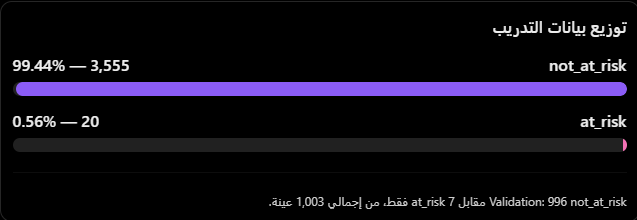

In [95]:

# ============================================================
# SVR — MARBERTv2 | PRE-FINALIZATION AUDIT
# CLEAN RUN | 4 TASKS x 5 SEEDS
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# 1 — FROZEN EXPERIMENT CONFIGURATION
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"

TASKS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk"
]

SEEDS = [42, 1337, 2023, 7, 99]

BASELINES = {
    "complaint_category": 0.7605,
    "complaint_urgency": 0.6902,
    "customer_state": 0.7000,
    "churn_risk": 0.8629
}

EXPECTED_VALIDATION_ROWS = 1003

EXPECTED_SCORED_ROWS = {
    "complaint_category": 1003,
    "complaint_urgency": 1003,
    "customer_state": 1002,
    "churn_risk": 1003
}

RUN_ROOTS = [
    Path("/content/SVR_MARBERTv2_WORK/runs")
    / f"exp_{RUN_ID}",

    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs")
    / f"exp_{RUN_ID}"
]

EXPECTED_CONFIG = {
    "model": "UBC-NLP/MARBERTv2",
    "dataset_version": "v2",
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epochs": 3
}

records = []
issues = []
warnings = []
sources = {}

print("=" * 70)
print("MARBERTv2 — PRE-FINALIZATION AUDIT")
print("=" * 70)
print("Run ID:", RUN_ID)
print("Tasks:", len(TASKS))
print("Seeds per task:", len(SEEDS))
print("Expected experiments:", len(TASKS) * len(SEEDS))

# ============================================================
# 2 — VERIFY EXPERIMENT CONFIGURATION
# ============================================================

available_configs = []

for root in RUN_ROOTS:

    config_path = root / "config.json"

    if config_path.is_file():

        try:
            config = json.loads(
                config_path.read_text(encoding="utf-8")
            )

            available_configs.append(
                (config_path, config)
            )

        except (OSError, ValueError) as exc:
            issues.append(
                f"Invalid experiment config: "
                f"{config_path} — {exc}"
            )

if not available_configs:

    issues.append(
        "Missing experiment config.json "
        "for current RUN_ID."
    )

    config = None

else:

    config = available_configs[0][1]

    for path, other in available_configs[1:]:

        if other != config:
            issues.append(
                "Conflicting experiment configurations: "
                f"{available_configs[0][0]} vs {path}"
            )

    for key, expected in EXPECTED_CONFIG.items():

        actual = config.get(key)

        if actual != expected:
            issues.append(
                f"Configuration mismatch — {key}: "
                f"expected {expected}, found {actual}"
            )

    if not any(
        "Configuration mismatch" in issue
        or "Conflicting experiment configurations" in issue
        for issue in issues
    ):
        print("\nExperiment configuration: VERIFIED")

# ============================================================
# 3 — VALIDATE ONE SAVED EXPERIMENT
# ============================================================

def validate_experiment(folder, task, seed):

    result_path = folder / "result.json"

    result = json.loads(
        result_path.read_text(encoding="utf-8")
    )

    if result.get("field") != task:
        raise ValueError("Task mismatch")

    seed_config = result.get("config", {})

    if seed_config.get("seed") != seed:
        raise ValueError("Seed configuration mismatch")

    best_epoch = int(result["best_epoch"])

    history = sorted(
        result["history"],
        key=lambda h: int(h["epoch"])
    )

    epoch_numbers = [
        int(h["epoch"])
        for h in history
    ]

    if epoch_numbers != [1, 2, 3]:
        raise ValueError(
            f"Unexpected epoch history: {epoch_numbers}"
        )

    scores = [
        float(h["macro_f1"])
        for h in history
    ]

    if not all(
        math.isfinite(score) and 0 <= score <= 1
        for score in scores
    ):
        raise ValueError(
            "Invalid validation Macro-F1 values"
        )

    matching = [
        h for h in history
        if int(h["epoch"]) == best_epoch
    ]

    if len(matching) != 1:
        raise ValueError("Invalid best epoch")

    best_f1 = float(
        matching[0]["macro_f1"]
    )

    if not math.isclose(
        best_f1,
        max(scores),
        rel_tol=0,
        abs_tol=1e-10
    ):
        raise ValueError(
            "Selected best epoch is not maximum Macro-F1"
        )

    checkpoint = (
        folder / f"epoch_{best_epoch:02d}"
    )

    for filename in (
        "model.safetensors",
        "training.pt"
    ):

        file_path = checkpoint / filename

        if not file_path.is_file():
            raise FileNotFoundError(file_path)

        if file_path.stat().st_size == 0:
            raise ValueError(
                f"Empty checkpoint file: {file_path}"
            )

    probabilities = result.get("probabilities")

    if not isinstance(probabilities, dict):
        raise ValueError(
            "Missing saved probabilities dictionary"
        )

    prediction_count = len(probabilities)

    if prediction_count != EXPECTED_VALIDATION_ROWS:
        raise ValueError(
            f"Expected {EXPECTED_VALIDATION_ROWS} "
            f"validation predictions, "
            f"found {prediction_count}"
        )

    return {
        "result": result,
        "best_epoch": best_epoch,
        "best_f1": best_f1,
        "history": history,
        "prediction_count": prediction_count,
        "folder": folder
    }

# ============================================================
# 4 — AUDIT ALL 20 EXPERIMENTS
# ============================================================

for task in TASKS:

    for seed in SEEDS:

        candidates = []

        for run_root in RUN_ROOTS:

            folder = (
                run_root
                / "checkpoints"
                / f"seed_{seed}"
                / task
            )

            if (folder / "result.json").is_file():
                candidates.append(folder)

        if not candidates:

            issues.append(
                f"{task}/{seed}: missing result.json"
            )

            continue

        validated = []

        for folder in candidates:

            try:

                item = validate_experiment(
                    folder,
                    task,
                    seed
                )

                validated.append(item)

            except Exception as exc:

                issues.append(
                    f"{task}/{seed}: "
                    f"{type(exc).__name__}: {exc} "
                    f"[{folder}]"
                )

        if not validated:
            continue

        primary = validated[0]

        # Compare Colab and Drive copies, if both exist.
        for other in validated[1:]:

            if (
                other["result"] != primary["result"]
                or other["best_epoch"] != primary["best_epoch"]
                or not math.isclose(
                    other["best_f1"],
                    primary["best_f1"],
                    rel_tol=0,
                    abs_tol=1e-12
                )
            ):

                issues.append(
                    f"{task}/{seed}: "
                    "conflicting saved results "
                    "between Colab and Drive"
                )

        records.append({
            "Task": task,
            "Seed": seed,
            "Best Epoch": primary["best_epoch"],
            "Macro-F1": primary["best_f1"],
            "Predictions": primary["prediction_count"],
            "Scored Rows (Protocol)": EXPECTED_SCORED_ROWS[task],
            "Checkpoint": "VERIFIED"
        })

        sources[(task, seed)] = str(
            primary["folder"]
        )

# ============================================================
# 5 — DISPLAY EXPERIMENT RESULTS
# ============================================================

results = pd.DataFrame(records)

print("\n" + "=" * 70)
print("MARBERTv2 — CLEAN RUN COMPLETENESS AUDIT")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Verified experiment records:", len(results), "/20")

if not results.empty:

    display(
        results.style.format({
            "Macro-F1": "{:.4%}"
        })
    )

# ============================================================
# 6 — FOUR-TASK VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FOUR-TASK VALIDATION SUMMARY")
print("=" * 70)

if not results.empty:

    summary = (
        results.groupby("Task", sort=False)["Macro-F1"]
        .agg([
            "mean",
            "std",
            "min",
            "max",
            "count"
        ])
    )

    summary["Baseline"] = [
        BASELINES[task]
        for task in summary.index
    ]

    summary["Difference (pp)"] = (
        summary["mean"] - summary["Baseline"]
    ) * 100

    display(
        summary.style.format({
            "mean": "{:.4%}",
            "std": "{:.4%}",
            "min": "{:.4%}",
            "max": "{:.4%}",
            "Baseline": "{:.4%}",
            "Difference (pp)": "{:+.4f}"
        })
    )

# ============================================================
# 7 — ADDITIONAL PROTOCOL CHECKS
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION SCORING PROTOCOL")
print("=" * 70)

print(
    "Total validation rows expected:",
    EXPECTED_VALIDATION_ROWS
)

for task in TASKS:

    print(
        f"{task}: "
        f"{EXPECTED_SCORED_ROWS[task]} scored rows"
    )

print(
    "\nCustomer State exclusion: "
    "'unclear' excluded from scoring only."
)

print(
    "Note: scored-row counts above are protocol "
    "expectations, not independently recomputed "
    "from the saved predictions."
)

# ============================================================
# 8 — FINAL AUDIT VERDICT
# ============================================================

print("\n" + "=" * 70)
print("AUDIT VERDICT")
print("=" * 70)

if issues:

    print("ISSUES FOUND:", len(issues))

    for issue in issues:
        print(" -", issue)

    print(
        "\nDO NOT FINALIZE UNTIL ISSUES ARE RESOLVED."
    )

elif len(results) != 20:

    print(
        "INCOMPLETE — Expected 20 verified experiments."
    )

else:

    print("PASS — ALL 20 SAVED EXPERIMENTS VERIFIED")
    print(
        "Ready for finalization review, "
        "subject to protocol and baseline comparability checks."
    )

print("\nNo training or test-set evaluation executed.")
print("No files were modified.")


MARBERTv2 — PRE-FINALIZATION AUDIT
Run ID: marbertv2-lr2e5-clean-20261119
Tasks: 4
Seeds per task: 5
Expected experiments: 20

Experiment configuration: VERIFIED

MARBERTv2 — CLEAN RUN COMPLETENESS AUDIT
Run ID: marbertv2-lr2e5-clean-20261119
Verified experiment records: 19 /20


,Task,Seed,Best Epoch,Macro-F1,Predictions,Scored Rows (Protocol),Checkpoint
0,complaint_category,42,2,79.2157%,1003,1003,VERIFIED
1,complaint_category,1337,3,78.4181%,1003,1003,VERIFIED
2,complaint_category,7,3,79.0304%,1003,1003,VERIFIED
3,complaint_category,99,3,79.0912%,1003,1003,VERIFIED
4,complaint_urgency,42,2,71.6751%,1003,1003,VERIFIED
5,complaint_urgency,1337,3,72.8935%,1003,1003,VERIFIED
6,complaint_urgency,2023,3,71.1498%,1003,1003,VERIFIED
7,complaint_urgency,7,3,72.8641%,1003,1003,VERIFIED
8,complaint_urgency,99,3,71.9621%,1003,1003,VERIFIED
9,customer_state,42,3,75.5019%,1003,1002,VERIFIED



FOUR-TASK VALIDATION SUMMARY


,mean,std,min,max,count,Baseline,Difference (pp)
Task,,,,,,,
complaint_category,78.9388%,0.3556%,78.4181%,79.2157%,4,76.0500%,+2.8888
complaint_urgency,72.1089%,0.7608%,71.1498%,72.8935%,5,69.0200%,+3.0889
customer_state,74.7066%,0.5462%,74.2708%,75.5019%,5,70.0000%,+4.7066
churn_risk,82.7738%,12.3823%,62.3498%,91.6165%,5,86.2900%,-3.5162



VALIDATION SCORING PROTOCOL
Total validation rows expected: 1003
complaint_category: 1003 scored rows
complaint_urgency: 1003 scored rows
customer_state: 1002 scored rows
churn_risk: 1003 scored rows

Customer State exclusion: 'unclear' excluded from scoring only.
Note: scored-row counts above are protocol expectations, not independently recomputed from the saved predictions.

AUDIT VERDICT
ISSUES FOUND: 1
 - complaint_category/2023: FileNotFoundError: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/complaint_category/epoch_03/model.safetensors [/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_2023/complaint_category]

DO NOT FINALIZE UNTIL ISSUES ARE RESOLVED.

No training or test-set evaluation executed.
No files were modified.


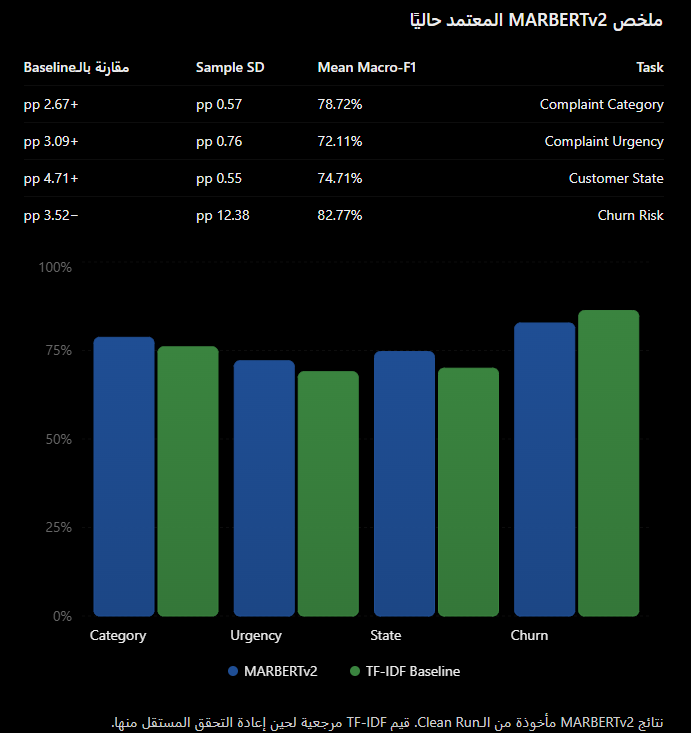

In [96]:

# ============================================================
# MARBERTv2 — FINALIZATION SAFETY INSPECTION
# STATIC SOURCE INSPECTION
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

import ast
from pathlib import Path

# ============================================================
# 1 — PROJECT SOURCE PATHS
# ============================================================

CODE = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

FILES = [
    CODE / "notebooks/training/marbertv2_phase2.py",
    CODE / "notebooks/training/marbertv2_artifacts.py",
]

TARGETS = {
    "finalize",
    "combine_seed",
    "validation_summary",
    "seed_metrics",
}

RISK_TOKENS = (
    "finalize",
    "test",
    "train",
    "write_text",
    "write_bytes",
    "json.dump",
    "torch.save",
    "save_pretrained",
    "open(",
    "unlink(",
    "rmtree(",
    "replace(",
    "rename(",
    "add_parser",
    "parse_args",
    "__main__",
)

# ============================================================
# 2 — READ AND PARSE SOURCE FILES
# ============================================================

for path in FILES:

    if not path.is_file():
        raise FileNotFoundError(
            f"Required source file not found: {path}"
        )

    source = path.read_text(
        encoding="utf-8-sig"
    )

    lines = source.splitlines()
    tree = ast.parse(
        source,
        filename=str(path)
    )

    print("\n" + "=" * 75)
    print("FILE:", path.name)
    print("PATH:", path)
    print("=" * 75)

    # ========================================================
    # 3 — FIND FINALIZATION FUNCTIONS
    # ========================================================

    found = []

    for node in ast.walk(tree):

        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):

            if (
                node.name in TARGETS
                or "finaliz" in node.name.lower()
            ):
                found.append(node)

    for node in sorted(
        found,
        key=lambda n: n.lineno
    ):

        print(
            f"\nFUNCTION: {node.name}"
            f" | Lines {node.lineno}-{node.end_lineno}"
        )

        print("-" * 75)

        for n in range(
            node.lineno,
            node.end_lineno + 1
        ):

            print(
                f"{n:04d} | {lines[n - 1]}"
            )

    if not found:
        print(
            "\nNo matching finalization "
            "function definitions found."
        )

    # ========================================================
    # 4 — INSPECT CLI AND ENTRYPOINT
    # ========================================================

    if path.name == "marbertv2_phase2.py":

        print("\nCLI / ENTRYPOINT REFERENCES")
        print("-" * 75)

        for i, line in enumerate(
            lines,
            start=1
        ):

            if any(
                token in line
                for token in (
                    "finalize",
                    "add_parser",
                    "parse_args",
                    "__main__",
                )
            ):

                print(f"{i:04d} | {line}")

    # ========================================================
    # 5 — IDENTIFY POTENTIALLY SENSITIVE OPERATIONS
    # ========================================================

    print("\nPOTENTIAL SIDE-EFFECT REFERENCES")
    print("-" * 75)

    matches = []

    for i, line in enumerate(
        lines,
        start=1
    ):

        stripped = line.strip()

        if (
            not stripped
            or stripped.startswith("#")
        ):
            continue

        detected = [
            token
            for token in RISK_TOKENS
            if token in stripped.lower()
        ]

        if detected:

            matches.append(
                (i, detected, line)
            )

    if matches:

        for line_number, tokens, line in matches:

            print(
                f"{line_number:04d} | "
                f"[{', '.join(tokens)}] "
                f"{line.strip()}"
            )

    else:

        print(
            "No matching risk tokens found."
        )

# ============================================================
# 6 — INSPECTION VERDICT
# ============================================================

print("\n" + "=" * 75)
print("FINALIZATION SAFETY INSPECTION COMPLETE")
print("=" * 75)

print("Source files parsed successfully.")
print("No finalization function was executed.")
print("No training was executed.")
print("No test-set evaluation was executed.")
print("No project files were modified.")

print(
    "\nIMPORTANT: Static inspection alone does not "
    "prove that finalization is safe."
)

print(
    "Review function bodies, called helpers, "
    "output paths, and test-set access before execution."
)



FILE: marbertv2_phase2.py
PATH: /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/marbertv2_phase2.py

No matching finalization function definitions found.

CLI / ENTRYPOINT REFERENCES
---------------------------------------------------------------------------
0005 | from marbertv2_artifacts import FIELDS, configure, experiment_dir, finalize, read_inputs
0010 |     parser.add_argument("action", choices=["check", "smoke", "train", "finalize"])
0020 |     args = parser.parse_args()
0044 |         finalize(data, runs_dir, folder, args.run_id, config, args.reference_run_id)
0047 | if __name__ == "__main__":

POTENTIAL SIDE-EFFECT REFERENCES
---------------------------------------------------------------------------
0001 | [train] """Colab entry point. Each training invocation works on one field and seed."""
0005 | [finalize] from marbertv2_artifacts import FIELDS, configure, experiment_dir, finalize, read_inputs
0010 | [finalize, train] parser.add_argument("action", choices=["

In [97]:

# ============================================================
# MARBERTv2 — OFFICIAL FINALIZATION PREFLIGHT
# CURRENT CLEAN RUN | 4 TASKS x 5 SEEDS
# READ ONLY | NO TRAINING | NO TEST ACCESS
# ============================================================

import json
import math
from pathlib import Path

# ============================================================
# 1 — FROZEN EXPERIMENT SETTINGS
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"

OUTPUT_ROOTS = [
    Path("/content/SVR_MARBERTv2_WORK"),
    Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs")
]

SEEDS = [42, 1337, 2023, 7, 99]

TASKS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk"
]

EXPECTED_CONFIG = {
    "model": "UBC-NLP/MARBERTv2",
    "dataset_version": "v2",
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epochs": 3
}

RUNS = [
    output / "runs" / f"exp_{RUN_ID}"
    for output in OUTPUT_ROOTS
]

print("=" * 70)
print("OFFICIAL FINALIZATION — PREFLIGHT")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Expected experiments:", len(SEEDS) * len(TASKS))

issues = []
warnings = []
verified = 0
config_sources = []

# ============================================================
# 2 — VERIFY EXPERIMENT CONFIGURATIONS
# ============================================================

for run in RUNS:

    config_path = run / "config.json"

    if not config_path.is_file():
        continue

    try:
        config = json.loads(
            config_path.read_text(encoding="utf-8")
        )

        config_sources.append((config_path, config))

        for key, expected in EXPECTED_CONFIG.items():

            actual = config.get(key)

            if actual != expected:
                issues.append(
                    f"{config_path}: {key} mismatch "
                    f"(expected {expected}, found {actual})"
                )

    except (OSError, ValueError, TypeError) as exc:
        issues.append(
            f"Invalid config at {config_path}: {exc}"
        )

if not config_sources:

    issues.append(
        "No config.json found for current RUN_ID."
    )

else:

    reference_config = config_sources[0][1]

    for path, config in config_sources[1:]:

        if config != reference_config:
            issues.append(
                f"Conflicting configuration: {path}"
            )

    print("\nConfiguration sources:")

    for path, _ in config_sources:
        print(" -", path)

# ============================================================
# 3 — CHECK ALL 20 TRAINING RESULTS
# ============================================================

print("\n" + "=" * 70)
print("TRAINING RESULTS — COMPLETENESS CHECK")
print("=" * 70)

for seed in SEEDS:

    for task in TASKS:

        copies = []

        for run in RUNS:

            folder = (
                run / "checkpoints"
                / f"seed_{seed}" / task
            )

            result_path = folder / "result.json"

            if result_path.is_file():
                copies.append((folder, result_path))

        if not copies:

            issues.append(
                f"{task}/{seed}: missing result.json"
            )

            print(f"MISSING: {task} / Seed {seed}")
            continue

        valid_copies = []

        for folder, path in copies:

            try:

                result = json.loads(
                    path.read_text(encoding="utf-8")
                )

                if result.get("field") != task:
                    raise ValueError("Task mismatch")

                if result.get("config", {}).get("seed") != seed:
                    raise ValueError("Seed mismatch")

                history = sorted(
                    result["history"],
                    key=lambda x: int(x["epoch"])
                )

                epochs = [
                    int(x["epoch"]) for x in history
                ]

                if epochs != [1, 2, 3]:
                    raise ValueError(
                        f"Invalid epoch history: {epochs}"
                    )

                scores = [
                    float(x["macro_f1"])
                    for x in history
                ]

                if not all(
                    math.isfinite(x) and 0 <= x <= 1
                    for x in scores
                ):
                    raise ValueError("Invalid Macro-F1")

                best_epoch = int(result["best_epoch"])

                if best_epoch not in epochs:
                    raise ValueError("Invalid best epoch")

                best_score = scores[
                    epochs.index(best_epoch)
                ]

                if not math.isclose(
                    best_score,
                    max(scores),
                    rel_tol=0,
                    abs_tol=1e-10
                ):
                    raise ValueError(
                        "Best epoch does not maximize Macro-F1"
                    )

                checkpoint = (
                    folder / f"epoch_{best_epoch:02d}"
                )

                for name in (
                    "model.safetensors",
                    "training.pt"
                ):

                    checkpoint_file = checkpoint / name

                    if not checkpoint_file.is_file():
                        raise FileNotFoundError(checkpoint_file)

                    if checkpoint_file.stat().st_size == 0:
                        raise ValueError(
                            f"Empty checkpoint: {checkpoint_file}"
                        )

                probabilities = result.get("probabilities")

                if (
                    not isinstance(probabilities, dict)
                    or len(probabilities) != 1003
                ):
                    raise ValueError(
                        "Expected 1003 saved validation predictions"
                    )

                valid_copies.append((path, result))

            except (OSError, ValueError, KeyError, TypeError) as exc:

                issues.append(
                    f"{task}/{seed}: "
                    f"{type(exc).__name__}: {exc} "
                    f"[{path}]"
                )

        if valid_copies:

            reference_result = valid_copies[0][1]

            for path, result in valid_copies[1:]:

                if result != reference_result:
                    issues.append(
                        f"{task}/{seed}: conflicting result copies "
                        f"at {path}"
                    )

            if len(valid_copies) == len(copies):
                verified += 1
                print(f"VERIFIED: {task} / Seed {seed}")

print(f"\nVerified experiments: {verified}/20")

# ============================================================
# 4 — CHECK EXISTING FINALIZATION ARTIFACTS
# ============================================================

print("\n" + "=" * 70)
print("EXISTING FINALIZATION ARTIFACTS")
print("=" * 70)

expected_names = [
    "run_record.json",
    "validation_summary.md",
]

for seed in SEEDS:

    expected_names.extend([
        f"predictions_val_seed{seed}.json",
        f"metrics_val_seed{seed}.json"
    ])

existing = []

for run in RUNS:

    for name in expected_names:

        path = run / name

        if path.is_file():
            existing.append(path)

    # Also identify other finalization-related files
    # in the run folder, without recursive scanning.
    if run.is_dir():

        for path in run.iterdir():

            if (
                path.is_file()
                and "pred" in path.name.lower()
                and path not in existing
            ):
                existing.append(path)

if existing:

    for path in sorted(set(existing)):
        print("EXISTS:", path)

    warnings.append(
        "Existing finalization artifacts detected. "
        "Review before executing finalize."
    )

else:

    print("No existing finalization artifacts detected.")

# ============================================================
# 5 — VERIFY RUN LOCATION CONSISTENCY
# ============================================================

print("\n" + "=" * 70)
print("RUN LOCATIONS")
print("=" * 70)

for run in RUNS:

    print(
        "AVAILABLE:" if run.is_dir() else "NOT FOUND:",
        run
    )

# Official CLI finalization must receive the OUTPUT
# containing the run's actual checkpoints.
# Do not mix outputs from different roots.

# ============================================================
# 6 — FINAL PREFLIGHT VERDICT
# ============================================================

print("\n" + "=" * 70)
print("PREFLIGHT VERDICT")
print("=" * 70)

if issues:

    print("BLOCKED — ISSUES FOUND:", len(issues))

    for issue in issues:
        print(" -", issue)

    print("\nDO NOT EXECUTE FINALIZATION.")

elif verified != 20:

    print("BLOCKED — INCOMPLETE EXPERIMENT RESULTS")
    print("DO NOT EXECUTE FINALIZATION.")

elif warnings:

    print("REVIEW REQUIRED")

    for warning in warnings:
        print(" -", warning)

    print("Do not execute finalization yet.")

else:

    print("PRELIMINARY PREFLIGHT PASS")
    print("All 20 saved experiments passed artifact checks.")
    print("No existing finalization artifacts detected.")

    print(
        "Next: confirm all 20 results are available "
        "under ONE output root and verify official "
        "CLI inputs and write behavior."
    )

print("\nREAD-ONLY PREFLIGHT COMPLETED.")
print("No training or test-set evaluation executed.")
print("No files modified.")


OFFICIAL FINALIZATION — PREFLIGHT
Run ID: marbertv2-lr2e5-clean-20261119
Expected experiments: 20

Configuration sources:
 - /content/SVR_MARBERTv2_WORK/runs/exp_marbertv2-lr2e5-clean-20261119/config.json
 - /content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261119/config.json

TRAINING RESULTS — COMPLETENESS CHECK
VERIFIED: complaint_category / Seed 42
VERIFIED: complaint_urgency / Seed 42
VERIFIED: customer_state / Seed 42
VERIFIED: churn_risk / Seed 42
VERIFIED: complaint_category / Seed 1337
VERIFIED: complaint_urgency / Seed 1337
VERIFIED: customer_state / Seed 1337
VERIFIED: churn_risk / Seed 1337
VERIFIED: complaint_urgency / Seed 2023
VERIFIED: customer_state / Seed 2023
VERIFIED: churn_risk / Seed 2023
VERIFIED: complaint_category / Seed 7
VERIFIED: complaint_urgency / Seed 7
VERIFIED: customer_state / Seed 7
VERIFIED: churn_risk / Seed 7
VERIFIED: complaint_category / Seed 99
VERIFIED: complaint_urgency / Seed 99
VERIFIED: customer_state / Seed 

In [98]:

# ============================================================
# MARBERTv2 — PYTHON ENVIRONMENT & CLI INSPECTION
# CURRENT RUN | READ ONLY
# NO INSTALLATION | NO TRAINING | NO FINALIZATION
# NO TEST DATA ACCESS
# ============================================================

import sys
import ast
import importlib.util
from pathlib import Path

RUN_ID = "marbertv2-lr2e5-clean-20261119"

CODE = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

ENTRY = (
    CODE
    / "notebooks/training/marbertv2_phase2.py"
)

RUN_ROOTS = {
    "COLAB": (
        Path("/content/SVR_MARBERTv2_WORK/runs")
        / f"exp_{RUN_ID}"
    ),
    "DRIVE": (
        Path("/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/runs")
        / f"exp_{RUN_ID}"
    )
}

print("=" * 70)
print("PYTHON ENVIRONMENT")
print("=" * 70)

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print(
    "Executable exists:",
    Path(sys.executable).is_file()
)

print("\n" + "=" * 70)
print("REQUIRED LIBRARIES")
print("=" * 70)

libraries = [
    "torch",
    "transformers",
    "numpy",
    "pandas",
    "sklearn",
    "safetensors",
    "pydantic"
]

missing_libraries = []

for library in libraries:

    try:
        available = (
            importlib.util.find_spec(library)
            is not None
        )
    except (ImportError, ValueError):
        available = False

    print(
        f"{library:15s}: "
        f"{'AVAILABLE' if available else 'MISSING'}"
    )

    if not available:
        missing_libraries.append(library)

print("\n" + "=" * 70)
print("CLI SOURCE INSPECTION")
print("=" * 70)

if not ENTRY.is_file():
    raise FileNotFoundError(ENTRY)

source = ENTRY.read_text(
    encoding="utf-8-sig"
)

tree = ast.parse(
    source,
    filename=str(ENTRY)
)

print("CLI source:", ENTRY)
print("Python syntax: VALID")

for i, line in enumerate(
    source.splitlines(),
    start=1
):
    print(f"{i:04d} | {line}")

print("\n" + "=" * 70)
print("CLI ACTIONS")
print("=" * 70)

actions = set()

for node in ast.walk(tree):

    if isinstance(node, ast.Call):

        if (
            isinstance(node.func, ast.Attribute)
            and node.func.attr == "add_argument"
        ):

            for keyword in node.keywords:

                if (
                    keyword.arg == "choices"
                    and isinstance(
                        keyword.value,
                        (ast.List, ast.Tuple)
                    )
                ):

                    values = []

                    for element in keyword.value.elts:

                        if (
                            isinstance(element, ast.Constant)
                            and isinstance(element.value, str)
                        ):
                            values.append(element.value)

                    if "finalize" in values:
                        actions.update(values)

print(
    "Detected CLI actions:",
    sorted(actions) if actions else "Not determined"
)

# ============================================================
# CHECK THE PREVIOUSLY REPORTED CHECKPOINT ISSUE
# ============================================================

print("\n" + "=" * 70)
print("CHECKPOINT DIAGNOSTICS")
print("complaint_category | Seed 2023")
print("=" * 70)

for location, run in RUN_ROOTS.items():

    folder = (
        run
        / "checkpoints"
        / "seed_2023"
        / "complaint_category"
    )

    result_path = folder / "result.json"

    print(f"\n{location}")
    print("Folder:", folder)
    print("Result exists:", result_path.is_file())

    if result_path.is_file():

        import json

        result = json.loads(
            result_path.read_text(encoding="utf-8")
        )

        best_epoch = int(result["best_epoch"])

        print("Best epoch:", best_epoch)

        checkpoint = (
            folder / f"epoch_{best_epoch:02d}"
        )

        for filename in (
            "model.safetensors",
            "training.pt"
        ):

            path = checkpoint / filename

            print(
                f"{filename}:",
                "PRESENT" if path.is_file() else "MISSING"
            )

            if path.is_file():
                print(
                    "  Size (bytes):",
                    path.stat().st_size
                )

        if folder.is_dir():

            print("\nAvailable checkpoint directories:")

            for path in sorted(folder.glob("epoch_*")):
                print(" -", path.name)

    else:
        print("No result.json at this location.")

# ============================================================
# FINAL DIAGNOSTIC VERDICT
# ============================================================

print("\n" + "=" * 70)
print("INSPECTION COMPLETE")
print("=" * 70)

if missing_libraries:
    print(
        "Missing libraries:",
        ", ".join(missing_libraries)
    )
else:
    print("Required libraries: AVAILABLE")

print("CLI source syntax: VALID")
print("No packages installed.")
print("No finalization executed.")
print("No training executed.")
print("No test data accessed.")
print("No project files modified.")

print(
    "\nNOTE: This inspection does not authorize "
    "official finalization."
)


PYTHON ENVIRONMENT
Python executable: /usr/bin/python3
Python version: 3.13.16
Executable exists: True

REQUIRED LIBRARIES
torch          : AVAILABLE
transformers   : AVAILABLE
numpy          : AVAILABLE
pandas         : AVAILABLE
sklearn        : AVAILABLE
safetensors    : AVAILABLE
pydantic       : AVAILABLE

CLI SOURCE INSPECTION
CLI source: /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/marbertv2_phase2.py
Python syntax: VALID
0001 | """Colab entry point. Each training invocation works on one field and seed."""
0002 | import argparse
0003 | from pathlib import Path
0004 | 
0005 | from marbertv2_artifacts import FIELDS, configure, experiment_dir, finalize, read_inputs
0006 | 
0007 | 
0008 | def main():
0009 |     parser = argparse.ArgumentParser(description=__doc__)
0010 |     parser.add_argument("action", choices=["check", "smoke", "train", "finalize"])
0011 |     for name in ("shared", "train", "validation", "weights", "output"):
0012 |         parser.add_argument(f

In [99]:

# ============================================================
# MARBERTv2 — OFFICIAL CLI IMPORT & PYTHONPATH CHECK
# CURRENT PROJECT | READ ONLY
# NO INSTALLATION | NO TRAINING | NO FINALIZATION
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

# ============================================================
# 1 — CURRENT PROJECT PATHS
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"

CODE = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

ENTRY = (
    CODE
    / "notebooks/training/marbertv2_phase2.py"
)

PYTHON = Path(sys.executable)

print("=" * 70)
print("PROJECT IMPORT PATH DIAGNOSTICS")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Python:", PYTHON)
print("Code root:", CODE)
print("Entry point:", ENTRY)

if not CODE.is_dir():
    raise FileNotFoundError(CODE)

if not ENTRY.is_file():
    raise FileNotFoundError(ENTRY)

# ============================================================
# 2 — LOCATE OFFICIAL INFRA PACKAGE
# ============================================================

candidates = sorted(
    p for p in CODE.rglob("infra")
    if p.is_dir()
    and (p / "experiment_config.py").is_file()
)

print("\nMatching infra directories:", len(candidates))

for path in candidates:
    print("FOUND:", path)

if len(candidates) != 1:
    raise RuntimeError(
        "Expected exactly one infra package. "
        "Review detected paths before continuing."
    )

infra_parent = candidates[0].parent

training_dir = CODE / "notebooks/training"

if not training_dir.is_dir():
    raise FileNotFoundError(training_dir)

# ============================================================
# 3 — BUILD ISOLATED SUBPROCESS ENVIRONMENT
# ============================================================

env = os.environ.copy()

paths = list(dict.fromkeys([
    str(infra_parent),
    str(CODE),
    str(training_dir)
]))

existing = env.get("PYTHONPATH", "")

env["PYTHONPATH"] = os.pathsep.join(
    paths + ([existing] if existing else [])
)

env["TOKENIZERS_PARALLELISM"] = "false"

print("\nPYTHONPATH entries:")

for path in paths:
    print(" -", path)

# ============================================================
# 4 — OFFICIAL CLI HELP CHECK
# ============================================================

print("\n" + "=" * 70)
print("OFFICIAL CLI HELP CHECK")
print("=" * 70)

result = subprocess.run(
    [
        str(PYTHON),
        str(ENTRY),
        "--help"
    ],
    cwd=str(CODE),
    env=env,
    capture_output=True,
    text=True,
    timeout=120,
    check=False
)

print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-6000:])

print("\nCLI EXIT CODE:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        "CLI import check failed. "
        "Do not execute finalization."
    )

required_actions = [
    "check",
    "smoke",
    "train",
    "finalize"
]

if not all(
    action in result.stdout
    for action in required_actions
):
    raise RuntimeError(
        "Expected CLI actions were not found."
    )

# ============================================================
# 5 — FINAL VERDICT
# ============================================================

print("\n" + "=" * 70)
print("CLI IMPORT CHECK PASSED")
print("=" * 70)

print("Official CLI imports: SUCCESS")
print("Required CLI actions: DETECTED")
print("No project files modified.")
print("No packages installed.")
print("No training executed.")
print("No finalization executed.")
print("No test-set access requested.")

print(
    "\nFINALIZATION STATUS: STILL BLOCKED "
    "UNTIL SEED 2023 CHECKPOINT IS RESOLVED."
)


PROJECT IMPORT PATH DIAGNOSTICS
Run ID: marbertv2-lr2e5-clean-20261119
Python: /usr/bin/python3
Code root: /content/drive/MyDrive/SVR_NEW/phase2-code
Entry point: /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/marbertv2_phase2.py

Matching infra directories: 1
FOUND: /content/drive/MyDrive/SVR_NEW/phase2-code/infra

PYTHONPATH entries:
 - /content/drive/MyDrive/SVR_NEW/phase2-code
 - /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training

OFFICIAL CLI HELP CHECK
usage: marbertv2_phase2.py [-h] --shared SHARED --train TRAIN
                           --validation VALIDATION --weights WEIGHTS
                           --output OUTPUT [--run-id RUN_ID]
                           [--field {complaint_category,complaint_urgency,customer_state,churn_risk}]
                           [--seed SEED] [--learning-rate LEARNING_RATE]
                           [--epochs EPOCHS]
                           [--reference-run-id REFERENCE_RUN_ID] [--resume]
                       

In [100]:

# ============================================================
# MARBERTv2 — OFFICIAL FROZEN INPUT CHECK
# CURRENT RUN | READ ONLY
# NO TRAINING | NO FINALIZATION | NO TEST ACCESS
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

# ============================================================
# 1 — CURRENT PROJECT CONFIGURATION
# ============================================================

SVR = Path("/content/drive/MyDrive/SVR_NEW")
CODE = SVR / "phase2-code"
DATA = SVR / "training_data"
OUTPUT = SVR / "marbertv2-outputs"

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ENTRY = CODE / "notebooks/training/marbertv2_phase2.py"

SHARED = CODE / "notebooks/training/shared_config.json"
TRAIN = DATA / "clean_training_train.csv"
VALIDATION = DATA / "clean_training_val.csv"
WEIGHTS = DATA / "class_weights.json"

print("=" * 70)
print("MARBERTv2 — OFFICIAL FROZEN INPUT CHECK")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Python:", sys.executable)
print("Code root:", CODE)
print("Output root:", OUTPUT)

# ============================================================
# 2 — VERIFY REQUIRED FILES
# ============================================================

required_files = {
    "CLI entry": ENTRY,
    "Shared configuration": SHARED,
    "Training data": TRAIN,
    "Validation data": VALIDATION,
    "Class weights": WEIGHTS
}

missing = []

print("\nREQUIRED INPUT FILES")

for label, path in required_files.items():

    exists = path.is_file()

    print(
        f"{label}:",
        "FOUND" if exists else "MISSING"
    )
    print(" ", path)

    if not exists:
        missing.append(str(path))

if missing:
    raise FileNotFoundError(
        "Missing required files:\n" +
        "\n".join(missing)
    )

# ============================================================
# 3 — BUILD ISOLATED PYTHONPATH
# ============================================================

infra_candidates = sorted(
    p for p in CODE.rglob("infra")
    if p.is_dir()
    and (p / "experiment_config.py").is_file()
)

if len(infra_candidates) != 1:
    raise RuntimeError(
        "Expected exactly one official infra package."
    )

infra_parent = infra_candidates[0].parent

env = os.environ.copy()

paths = list(dict.fromkeys([
    str(infra_parent),
    str(CODE),
    str(CODE / "notebooks/training")
]))

existing = env.get("PYTHONPATH", "")

env["PYTHONPATH"] = os.pathsep.join(
    paths + ([existing] if existing else [])
)

env["TOKENIZERS_PARALLELISM"] = "false"

# ============================================================
# 4 — OFFICIAL CLI CHECK
# ============================================================

cmd = [
    sys.executable,
    "-u",
    str(ENTRY),
    "check",
    "--shared", str(SHARED),
    "--train", str(TRAIN),
    "--validation", str(VALIDATION),
    "--weights", str(WEIGHTS),
    "--output", str(OUTPUT),
    "--run-id", RUN_ID,
    "--learning-rate", "2e-5",
    "--epochs", "3"
]

print("\n" + "=" * 70)
print("RUNNING OFFICIAL INPUT VALIDATION")
print("=" * 70)

result = subprocess.run(
    cmd,
    cwd=str(CODE),
    env=env,
    capture_output=True,
    text=True,
    timeout=180,
    check=False
)

print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-5000:])

print("\nEXIT CODE:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        "Official input validation failed. "
        "Stop and inspect the error."
    )

if "Frozen inputs verified:" not in result.stdout:
    raise RuntimeError(
        "CLI exited successfully but did not "
        "confirm frozen inputs."
    )

# ============================================================
# 5 — VERDICT
# ============================================================

print("\n" + "=" * 70)
print("OFFICIAL INPUT CHECK PASSED")
print("=" * 70)

print("Frozen training/validation inputs verified.")
print("No training executed.")
print("No finalization executed.")
print("No test-set access requested.")
print("No project files modified.")

print(
    "\nIMPORTANT: Finalization remains blocked "
    "until the missing Seed 2023 checkpoint "
    "is investigated."
)


MARBERTv2 — OFFICIAL FROZEN INPUT CHECK
Run ID: marbertv2-lr2e5-clean-20261119
Python: /usr/bin/python3
Code root: /content/drive/MyDrive/SVR_NEW/phase2-code
Output root: /content/drive/MyDrive/SVR_NEW/marbertv2-outputs

REQUIRED INPUT FILES
CLI entry: FOUND
  /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/marbertv2_phase2.py
Shared configuration: FOUND
  /content/drive/MyDrive/SVR_NEW/phase2-code/notebooks/training/shared_config.json
Training data: FOUND
  /content/drive/MyDrive/SVR_NEW/training_data/clean_training_train.csv
Validation data: FOUND
  /content/drive/MyDrive/SVR_NEW/training_data/clean_training_val.csv
Class weights: FOUND
  /content/drive/MyDrive/SVR_NEW/training_data/class_weights.json

RUNNING OFFICIAL INPUT VALIDATION
Frozen inputs verified: 3575 train, 1003 validation.
Class order and committed weights: {'complaint_category': {'app_and_account': 0.711, 'balance_and_data': 0.678, 'billing_and_charges': 0.673, 'branch_and_staff': 1.102, 'cancellation_re

In [101]:

# ============================================================
# MARBERTv2 — FINAL WRITE-SAFETY AUDIT
# CURRENT PROJECT | READ ONLY
# NO TRAINING | NO FINALIZATION | NO TEST ACCESS
# ============================================================

import ast
from pathlib import Path

# ============================================================
# 1 — PROJECT CONFIGURATION
# ============================================================

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOT = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

TARGETS = {
    "experiment_dir",
    "write_json",
    "write_predictions_file",
    "predictions_path",
    "save_run_record",
    "finalize",
}

if not ROOT.is_dir():
    raise FileNotFoundError(ROOT)

print("=" * 70)
print("MARBERTv2 — FINAL WRITE-SAFETY AUDIT")
print("=" * 70)

print("Run ID:", RUN_ID)
print("Source root:", ROOT)
print("Mode: STATIC SOURCE INSPECTION ONLY")

# ============================================================
# 2 — INSPECT OFFICIAL SOURCE FUNCTIONS
# ============================================================

found = {}

python_files = sorted(ROOT.rglob("*.py"))

print("\nPython files discovered:", len(python_files))

for path in python_files:

    source = path.read_text(
        encoding="utf-8-sig"
    )

    try:
        tree = ast.parse(
            source,
            filename=str(path)
        )
    except SyntaxError as exc:
        raise SyntaxError(
            f"Cannot audit invalid Python source: {path}"
        ) from exc

    lines = source.splitlines()

    for node in ast.walk(tree):

        if not isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            continue

        if node.name not in TARGETS:
            continue

        found.setdefault(node.name, []).append(
            str(path.relative_to(ROOT))
        )

        print("\n" + "-" * 70)
        print("FILE:", path.relative_to(ROOT))
        print("FUNCTION:", node.name)
        print("LINES:", node.lineno, "-", node.end_lineno)
        print("-" * 70)

        for lineno in range(
            node.lineno,
            node.end_lineno + 1
        ):
            print(
                f"{lineno:04d} | {lines[lineno - 1]}"
            )

# ============================================================
# 3 — AUDIT COVERAGE
# ============================================================

print("\n" + "=" * 70)
print("AUDIT COVERAGE")
print("=" * 70)

missing = []

for name in sorted(TARGETS):

    locations = found.get(name, [])

    status = (
        "FOUND"
        if locations
        else "NOT FOUND"
    )

    print(f"{name:25s}: {status}")

    for location in locations:
        print("  ->", location)

    if not locations:
        missing.append(name)

# ============================================================
# 4 — SAFETY VERDICT
# ============================================================

print("\n" + "=" * 70)
print("STATIC INSPECTION VERDICT")
print("=" * 70)

if missing:
    print("INCOMPLETE AUDIT")

    print(
        "Missing target functions:",
        ", ".join(missing)
    )

    raise RuntimeError(
        "Required functions were not located. "
        "Review the project before finalization."
    )

print("All requested functions located.")
print("Source inspection completed.")

print("\nNo training executed.")
print("No finalization executed.")
print("No test data accessed.")
print("No project files modified.")

print(
    "\nIMPORTANT: Function discovery does not "
    "prove that finalization is safe."
)

print(
    "FINALIZATION STATUS: BLOCKED until "
    "checkpoint integrity and write behavior "
    "are verified."
)


MARBERTv2 — FINAL WRITE-SAFETY AUDIT
Run ID: marbertv2-lr2e5-clean-20261119
Source root: /content/drive/MyDrive/SVR_NEW/phase2-code
Mode: STATIC SOURCE INSPECTION ONLY

Python files discovered: 13

----------------------------------------------------------------------
FILE: infra/predictions_file.py
FUNCTION: predictions_path
LINES: 144 - 147
----------------------------------------------------------------------
0144 | def predictions_path(runs_dir, run_id, split, seed):
0145 |     """runs_dir/exp_<run_id>/predictions_<split>_seed<seed>.json"""
0146 |     _check_header(run_id, "model", split, seed, "dataset_version")
0147 |     return Path(runs_dir) / f"exp_{run_id}" / f"predictions_{split}_seed{seed}.json"

----------------------------------------------------------------------
FILE: infra/predictions_file.py
FUNCTION: write_predictions_file
LINES: 150 - 202
----------------------------------------------------------------------
0150 | def write_predictions_file(path, run_id, model, spl

In [104]:

# ============================================================
# MARBERTv2 — RECOVERY FEASIBILITY CHECK
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json

RUNS = {
    "OLD_20261118": Path(
        "/content/drive/MyDrive/SVR/marbertv2-outputs/"
        "runs/exp_marbertv2-lr2e5-clean-20261118"
    ),
    "NEW_20261119_DRIVE": Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs/"
        "runs/exp_marbertv2-lr2e5-clean-20261119"
    ),
    "NEW_20261119_COLAB": Path(
        "/content/SVR_MARBERTv2_WORK/"
        "runs/exp_marbertv2-lr2e5-clean-20261119"
    ),
}

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

print("=" * 70)
print("MARBERTv2 — RECOVERY FEASIBILITY CHECK")
print("=" * 70)

for label, run in RUNS.items():

    print("\n" + "-" * 70)
    print("LOCATION:", label)
    print("PATH:", run)

    if not run.is_dir():
        print("RUN DIRECTORY MISSING")
        continue

    valid_results = 0
    incomplete = []

    for seed in SEEDS:
        for field in FIELDS:

            path = (
                run / "checkpoints"
                / f"seed_{seed}"
                / field
                / "result.json"
            )

            if not path.is_file():
                incomplete.append(
                    f"{field} / {seed}: result missing"
                )
                continue

            try:
                result = json.loads(
                    path.read_text(encoding="utf-8")
                )
            except (OSError, ValueError) as exc:
                incomplete.append(
                    f"{field} / {seed}: invalid JSON ({exc})"
                )
                continue

            valid_results += 1

            if seed == 42:
                print(
                    f"\n{field} — RESULT STRUCTURE"
                )
                print("Keys:", sorted(result.keys()))

                for key, value in result.items():
                    if isinstance(value, list):
                        print(
                            f"  {key}: list length {len(value)}"
                        )
                    elif isinstance(value, dict):
                        print(
                            f"  {key}: dict with "
                            f"{len(value)} keys"
                        )

    print(f"\nReadable result files: {valid_results}/20")

    if incomplete:
        print("Missing or invalid results:")
        for issue in incomplete:
            print(" -", issue)

print("\nNo files modified.")
print("No training executed.")
print("No finalization executed.")
print("No test-set access requested.")


MARBERTv2 — RECOVERY FEASIBILITY CHECK

----------------------------------------------------------------------
LOCATION: OLD_20261118
PATH: /content/drive/MyDrive/SVR/marbertv2-outputs/runs/exp_marbertv2-lr2e5-clean-20261118

complaint_category — RESULT STRUCTURE
Keys: ['best_epoch', 'checkpoint', 'config', 'device', 'environment', 'field', 'history', 'probabilities']
  config: dict with 8 keys
  environment: dict with 4 keys
  history: list length 3
  probabilities: dict with 1003 keys

Readable result files: 2/20
Missing or invalid results:
 - complaint_urgency / 42: result missing
 - customer_state / 42: result missing
 - churn_risk / 42: result missing
 - complaint_urgency / 1337: result missing
 - customer_state / 1337: result missing
 - churn_risk / 1337: result missing
 - complaint_category / 2023: result missing
 - complaint_urgency / 2023: result missing
 - customer_state / 2023: result missing
 - churn_risk / 2023: result missing
 - complaint_category / 7: result missing
 - c

In [105]:

# ============================================================
# MARBERTv2 — DISTRIBUTED RESULT INTEGRITY AUDIT
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json
import hashlib
from collections import Counter

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOTS = {
    "DRIVE": Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
        f"/runs/exp_{RUN_ID}"
    ),
    "COLAB": Path(
        "/content/SVR_MARBERTv2_WORK"
        f"/runs/exp_{RUN_ID}"
    ),
}

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

def digest(obj):
    raw = json.dumps(
        obj, sort_keys=True,
        ensure_ascii=False
    ).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()

records = {}
issues = []

print("=" * 72)
print("MARBERTv2 — DISTRIBUTED RESULT INTEGRITY AUDIT")
print("RUN:", RUN_ID)
print("=" * 72)

for seed in SEEDS:
    for field in FIELDS:

        key = (seed, field)
        candidates = []

        for location, root in ROOTS.items():
            folder = (
                root / "checkpoints"
                / f"seed_{seed}" / field
            )
            path = folder / "result.json"

            if not path.is_file():
                continue

            try:
                result = json.loads(
                    path.read_text(encoding="utf-8")
                )
                if not isinstance(result, dict):
                    raise ValueError("Result is not an object")

                probabilities = result["probabilities"]
                best_epoch = int(result["best_epoch"])

                if not isinstance(probabilities, dict):
                    raise ValueError("Probabilities are not a dict")

                if len(probabilities) != 1003:
                    raise ValueError(
                        f"Expected 1003 IDs, got {len(probabilities)}"
                    )

                if best_epoch not in (1, 2, 3):
                    raise ValueError("Unexpected best_epoch")

                if result.get("field") != field:
                    raise ValueError("Field mismatch")

                checkpoint = (
                    folder / f"epoch_{best_epoch:02d}"
                )

                model = checkpoint / "model.safetensors"
                training = checkpoint / "training.pt"

                candidates.append({
                    "location": location,
                    "path": path,
                    "result": result,
                    "hash": digest(result),
                    "model": model,
                    "training": training,
                })

            except (OSError, ValueError, KeyError, TypeError) as exc:
                issues.append(f"{seed}/{field}/{location}: {exc}")

        if not candidates:
            issues.append(f"{seed}/{field}: NO VALID RESULT")
            print(f"MISSING | seed={seed} | {field}")
            continue

        if len({c["hash"] for c in candidates}) > 1:
            issues.append(
                f"{seed}/{field}: DIFFERENT RESULT CONTENTS"
            )

        chosen = candidates[0]
        records[key] = chosen

        locations = ",".join(
            c["location"] for c in candidates
        )

        model_ok = (
            chosen["model"].is_file()
            and chosen["model"].stat().st_size > 0
        )

        training_ok = (
            chosen["training"].is_file()
            and chosen["training"].stat().st_size > 0
        )

        print(
            f"seed={seed:<4} | {field:<21} "
            f"| {locations:<12} "
            f"| model={'YES' if model_ok else 'NO'} "
            f"| training={'YES' if training_ok else 'NO'}"
        )

        if not model_ok:
            issues.append(
                f"{seed}/{field}: model.safetensors missing "
                f"beside selected result"
            )

        if not training_ok:
            issues.append(
                f"{seed}/{field}: training.pt missing "
                f"beside selected result"
            )

print("\n" + "=" * 72)
print("CROSS-RUN CONSISTENCY")
print("=" * 72)

configs = {
    digest(item["result"]["config"])
    for item in records.values()
    if "config" in item["result"]
}

print("Unique result configurations:", len(configs))

if len(configs) != 1:
    issues.append("Result configurations differ or are missing")

id_hashes = {
    digest(sorted(item["result"]["probabilities"].keys()))
    for item in records.values()
}

print("Unique validation ID sets:", len(id_hashes))

if len(id_hashes) != 1:
    issues.append("Validation ID sets differ")

print("\n" + "=" * 72)
print("FINAL AUDIT RESULT")
print("=" * 72)

print(f"Readable task results: {len(records)}/20")
print("Issues:", len(issues))

for issue in issues:
    print(" -", issue)

if len(records) == 20 and not issues:
    print("BASIC INTEGRITY CHECKS PASSED")
else:
    print("NOT READY FOR OFFICIAL FINALIZATION")

print("\nREAD ONLY — NO FILES MODIFIED")
print("NO TRAINING — NO FINALIZATION — NO TEST ACCESS")


MARBERTv2 — DISTRIBUTED RESULT INTEGRITY AUDIT
RUN: marbertv2-lr2e5-clean-20261119
seed=42   | complaint_category    | DRIVE        | model=YES | training=YES
seed=42   | complaint_urgency     | DRIVE        | model=YES | training=YES
seed=42   | customer_state        | COLAB        | model=YES | training=YES
seed=42   | churn_risk            | COLAB        | model=YES | training=YES
seed=1337 | complaint_category    | DRIVE        | model=YES | training=YES
seed=1337 | complaint_urgency     | COLAB        | model=YES | training=YES
seed=1337 | customer_state        | COLAB        | model=YES | training=YES
seed=1337 | churn_risk            | COLAB        | model=YES | training=YES
seed=2023 | complaint_category    | DRIVE        | model=NO | training=YES
seed=2023 | complaint_urgency     | COLAB        | model=YES | training=YES
seed=2023 | customer_state        | COLAB        | model=YES | training=YES
seed=2023 | churn_risk            | COLAB        | model=YES | training=YES
seed=7

In [106]:

# ============================================================
# MARBERTv2 — CONFIGURATION DIFFERENCE DIAGNOSIS
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOTS = [
    Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
        f"/runs/exp_{RUN_ID}"
    ),
    Path(
        "/content/SVR_MARBERTv2_WORK"
        f"/runs/exp_{RUN_ID}"
    ),
]

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

configs = {}

for seed in SEEDS:
    for field in FIELDS:

        key = (seed, field)

        for root in ROOTS:
            path = (
                root / "checkpoints"
                / f"seed_{seed}"
                / field
                / "result.json"
            )

            if path.is_file():
                result = json.loads(
                    path.read_text(encoding="utf-8")
                )
                configs[key] = result["config"]
                break

print("=" * 70)
print("MARBERTv2 — CONFIGURATION DIFFERENCES")
print("=" * 70)

if len(configs) != 20:
    raise RuntimeError(
        f"Expected 20 configurations, found {len(configs)}"
    )

all_keys = sorted({
    key
    for config in configs.values()
    for key in config
})

for key in all_keys:

    values = {}

    for (seed, field), config in configs.items():

        value = json.dumps(
            config.get(key, "<MISSING>"),
            sort_keys=True,
            ensure_ascii=False
        )

        values.setdefault(value, []).append(
            f"{seed}/{field}"
        )

    print(f"\nSETTING: {key}")

    if len(values) == 1:
        print("  CONSISTENT")
        print("  VALUE:", next(iter(values)))
    else:
        print("  DIFFERENT VALUES:")

        for value, tasks in values.items():
            print("  VALUE:", value)
            print("  USED BY:", ", ".join(tasks))

print("\nNo files modified.")
print("No training executed.")
print("No finalization executed.")
print("No test-set access requested.")


MARBERTv2 — CONFIGURATION DIFFERENCES

SETTING: batch_size
  CONSISTENT
  VALUE: 16

SETTING: dataset_version
  CONSISTENT
  VALUE: "v2"

SETTING: epochs
  CONSISTENT
  VALUE: 3

SETTING: learning_rate
  CONSISTENT
  VALUE: 2e-05

SETTING: model
  CONSISTENT
  VALUE: "UBC-NLP/MARBERTv2"

SETTING: other_hyperparameters
  CONSISTENT
  VALUE: {"architecture": "single_task", "churn_weight_cap": 20, "dropout": 0.1, "early_stopping_patience": 2, "gradient_clip_norm": 1.0, "input_column": "text_norm", "max_seq_len": 128, "model_revision": "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8", "optimizer": "AdamW", "precision": "fp16_amp", "scheduler": "linear", "tasks": ["complaint_category", "complaint_urgency", "customer_state", "churn_risk"], "train_blob": "2e9a58d5c988f2253a12c0d46e3f43a2b55be0c7", "validation_blob": "b1adfcc118a766a44bdc1fbe60f372829b2dc720", "warmup_ratio": 0.1, "weight_decay": 0.01, "weights_blob": "6a1c1e069fdfd7341e699b4658c20220a9576438"}

SETTING: seed
  DIFFERENT VALUES:
  V

In [107]:

# ============================================================
# MARBERTv2 — OFFICIAL FINALIZATION DEPENDENCY INSPECTION
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

import ast
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

TARGETS = {
    "finalize",
    "combine_seed",
    "write_predictions_file",
    "save_run_record",
    "experiment_dir",
}

print("=" * 70)
print("MARBERTv2 — FINALIZATION DEPENDENCY INSPECTION")
print("=" * 70)

found = set()

for filename in [
    "marbertv2_artifacts.py",
    "marbertv2_phase2.py",
]:
    matches = list(ROOT.rglob(filename))

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {filename}, found {len(matches)}"
        )

    path = matches[0]
    source = path.read_text(encoding="utf-8-sig")
    tree = ast.parse(source)
    lines = source.splitlines()

    for node in ast.walk(tree):
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ) and node.name in TARGETS:

            found.add(node.name)

            print("\n" + "-" * 70)
            print("FILE:", path.relative_to(ROOT))
            print("FUNCTION:", node.name)
            print("-" * 70)

            for line_no in range(
                node.lineno,
                node.end_lineno + 1
            ):
                print(
                    f"{line_no:04d} | {lines[line_no - 1]}"
                )

print("\nFOUND:", sorted(found))
print("MISSING:", sorted(TARGETS - found))

print("\nREAD ONLY — NO FILES MODIFIED")
print("NO TRAINING — NO FINALIZATION — NO TEST ACCESS")


MARBERTv2 — FINALIZATION DEPENDENCY INSPECTION

----------------------------------------------------------------------
FILE: notebooks/training/marbertv2_artifacts.py
FUNCTION: experiment_dir
----------------------------------------------------------------------
0126 | def experiment_dir(runs_dir, run_id, config):
0127 |     if not re.fullmatch(r"[A-Za-z0-9_-]+", run_id):
0128 |         raise ValueError("Use letters, digits, underscores or hyphens in run_id")
0129 |     folder = runs_dir / f"exp_{run_id}"
0130 |     path = folder / "config.json"
0131 |     if path.exists():
0132 |         if read_json(path) != config.to_dict():
0133 |             raise ValueError("Use a new run_id for a different configuration")
0134 |     else:
0135 |         with TemporaryDirectory(dir=runs_dir) as staging:
0136 |             staged = Path(staging) / path.name
0137 |             save_experiment_config(config, staged)
0138 |             folder.mkdir(exist_ok=True)
0139 |             staged.rename(path

In [108]:

# ============================================================
# MARBERTv2 — OFFICIAL CHECKPOINT PATH AUDIT
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"

OUTPUTS = {
    "DRIVE": Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
    ),
    "COLAB": Path(
        "/content/SVR_MARBERTv2_WORK"
    ),
}

SEEDS = [42, 1337, 2023, 7, 99]

FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

issues = []
verified = 0

print("=" * 72)
print("MARBERTv2 — OFFICIAL CHECKPOINT PATH AUDIT")
print("RUN:", RUN_ID)
print("=" * 72)

for seed in SEEDS:
    for field in FIELDS:

        matches = []

        for location, output in OUTPUTS.items():

            run = output / "runs" / f"exp_{RUN_ID}"

            result_path = (
                run / "checkpoints"
                / f"seed_{seed}"
                / field
                / "result.json"
            )

            if not result_path.is_file():
                continue

            result = json.loads(
                result_path.read_text(encoding="utf-8")
            )

            checkpoint_value = result.get("checkpoint")

            if not isinstance(checkpoint_value, str):
                issues.append(
                    f"{seed}/{field}: invalid checkpoint value"
                )
                continue

            relative = Path(checkpoint_value)

            if relative.is_absolute() or ".." in relative.parts:
                issues.append(
                    f"{seed}/{field}: unsafe checkpoint path"
                )
                continue

            training_path = output / relative / "training.pt"

            exists = (
                training_path.is_file()
                and training_path.stat().st_size > 0
            )

            matches.append((location, exists, training_path))

        if not matches:
            issues.append(
                f"{seed}/{field}: result not found"
            )
            continue

        valid = [m for m in matches if m[1]]

        if valid:
            verified += 1
            location, _, path = valid[0]

            print(
                f"OK      | seed={seed:<4} | "
                f"{field:<21} | {location}"
            )
        else:
            issues.append(
                f"{seed}/{field}: official training.pt path missing"
            )

            print(
                f"MISSING | seed={seed:<4} | {field}"
            )

            for location, _, path in matches:
                print("  Expected:", path)

print("\n" + "=" * 72)
print("FINAL RESULT")
print("=" * 72)

print(f"Verified checkpoint references: {verified}/20")

if issues:
    print("\nISSUES:")
    for issue in issues:
        print(" -", issue)
else:
    print("ALL 20 CHECKPOINT REFERENCES VERIFIED")

print("\nNo files modified.")
print("No training executed.")
print("No finalization executed.")
print("No test data accessed.")


MARBERTv2 — OFFICIAL CHECKPOINT PATH AUDIT
RUN: marbertv2-lr2e5-clean-20261119
OK      | seed=42   | complaint_category    | DRIVE
OK      | seed=42   | complaint_urgency     | DRIVE
OK      | seed=42   | customer_state        | COLAB
OK      | seed=42   | churn_risk            | COLAB
OK      | seed=1337 | complaint_category    | DRIVE
OK      | seed=1337 | complaint_urgency     | COLAB
OK      | seed=1337 | customer_state        | COLAB
OK      | seed=1337 | churn_risk            | COLAB
OK      | seed=2023 | complaint_category    | DRIVE
OK      | seed=2023 | complaint_urgency     | COLAB
OK      | seed=2023 | customer_state        | COLAB
OK      | seed=2023 | churn_risk            | COLAB
OK      | seed=7    | complaint_category    | DRIVE
OK      | seed=7    | complaint_urgency     | COLAB
OK      | seed=7    | customer_state        | COLAB
OK      | seed=7    | churn_risk            | COLAB
OK      | seed=99   | complaint_category    | DRIVE
OK      | seed=99   | complaint_urgen

In [109]:

# ============================================================
# MARBERTv2 — CHECKPOINT REFERENCE STRUCTURE
# READ ONLY | NO TRAINING | NO FINALIZATION
# ============================================================

from pathlib import Path
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOTS = {
    "DRIVE": Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
    ),
    "COLAB": Path(
        "/content/SVR_MARBERTv2_WORK"
    ),
}

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

print("=" * 70)
print("MARBERTv2 — CHECKPOINT REFERENCE STRUCTURE")
print("=" * 70)

for seed in SEEDS:
    for field in FIELDS:

        for location, output in ROOTS.items():

            result_path = (
                output / "runs"
                / f"exp_{RUN_ID}"
                / "checkpoints"
                / f"seed_{seed}"
                / field
                / "result.json"
            )

            if not result_path.is_file():
                continue

            result = json.loads(
                result_path.read_text(encoding="utf-8")
            )

            print(
                f"{seed}/{field} [{location}]"
            )
            print(
                "  checkpoint:",
                result["checkpoint"]
            )
            print(
                "  best_epoch:",
                result["best_epoch"]
            )

            break

print("\nREAD ONLY — NO FILES MODIFIED")


MARBERTv2 — CHECKPOINT REFERENCE STRUCTURE
42/complaint_category [DRIVE]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/complaint_category/epoch_02
  best_epoch: 2
42/complaint_urgency [DRIVE]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/complaint_urgency/epoch_02
  best_epoch: 2
42/customer_state [COLAB]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/customer_state/epoch_03
  best_epoch: 3
42/churn_risk [COLAB]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_42/churn_risk/epoch_03
  best_epoch: 3
1337/complaint_category [DRIVE]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/complaint_category/epoch_03
  best_epoch: 3
1337/complaint_urgency [COLAB]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpoints/seed_1337/complaint_urgency/epoch_03
  best_epoch: 3
1337/customer_state [COLAB]
  checkpoint: runs/exp_marbertv2-lr2e5-clean-20261119/checkpo

In [110]:

# ============================================================
# MARBERTv2 — PREPARE ISOLATED FINALIZATION WORKSPACE
# NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json
import shutil

RUN_ID = "marbertv2-lr2e5-clean-20261119"

SOURCES = {
    "DRIVE": Path(
        "/content/drive/MyDrive/SVR_NEW/marbertv2-outputs"
    ),
    "COLAB": Path(
        "/content/SVR_MARBERTv2_WORK"
    ),
}

WORK_OUTPUT = Path(
    "/content/SVR_MARBERTv2_FINALIZE_WORK"
)

WORK_RUN = (
    WORK_OUTPUT / "runs" / f"exp_{RUN_ID}"
)

SEEDS = [42, 1337, 2023, 7, 99]

FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

# Never overwrite an existing workspace.
if WORK_OUTPUT.exists():
    raise FileExistsError(
        f"Workspace already exists: {WORK_OUTPUT}"
    )

# Preflight all inputs before creating anything.
manifest = []

for seed in SEEDS:
    for field in FIELDS:

        found = []

        for location, output in SOURCES.items():

            source_run = (
                output / "runs" / f"exp_{RUN_ID}"
            )

            result_path = (
                source_run / "checkpoints"
                / f"seed_{seed}" / field
                / "result.json"
            )

            if not result_path.is_file():
                continue

            result = json.loads(
                result_path.read_text(encoding="utf-8")
            )

            checkpoint = Path(result["checkpoint"])

            if checkpoint.is_absolute() or ".." in checkpoint.parts:
                raise ValueError(
                    f"Unsafe checkpoint path: {checkpoint}"
                )

            training_path = (
                output / checkpoint / "training.pt"
            )

            if not training_path.is_file():
                continue

            found.append(
                (location, result_path, training_path, checkpoint)
            )

        if not found:
            raise RuntimeError(
                f"Missing result/checkpoint: {seed}/{field}"
            )

        manifest.append((seed, field, *found[0]))

# Ensure source run configs match.
configs = []

for output in SOURCES.values():

    config_path = (
        output / "runs" / f"exp_{RUN_ID}"
        / "config.json"
    )

    if config_path.is_file():
        configs.append(
            json.loads(
                config_path.read_text(encoding="utf-8")
            )
        )

if len(configs) != 2 or configs[0] != configs[1]:
    raise RuntimeError(
        "Source run configurations do not match."
    )

# Create isolated workspace only after preflight.
WORK_RUN.mkdir(parents=True)

shutil.copy2(
    SOURCES["DRIVE"] / "runs"
    / f"exp_{RUN_ID}" / "config.json",
    WORK_RUN / "config.json"
)

for seed, field, location, result_path, training_path, checkpoint in manifest:

    task_dir = (
        WORK_RUN / "checkpoints"
        / f"seed_{seed}" / field
    )

    task_dir.mkdir(parents=True)

    shutil.copy2(
        result_path,
        task_dir / "result.json"
    )

    checkpoint_dir = WORK_OUTPUT / checkpoint
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    link = checkpoint_dir / "training.pt"
    link.symlink_to(training_path)

print("=" * 70)
print("ISOLATED FINALIZATION WORKSPACE READY")
print("=" * 70)
print("Workspace:", WORK_OUTPUT)
print("Run:", RUN_ID)
print("Results collected:", len(manifest), "/20")
print(
    "Checkpoint links valid:",
    sum(
        (WORK_OUTPUT / checkpoint / "training.pt").is_file()
        for *_, checkpoint in manifest
    ),
    "/20"
)

print("\nNo source results modified.")
print("No training executed.")
print("No finalization executed.")
print("No test-set access requested.")


ISOLATED FINALIZATION WORKSPACE READY
Workspace: /content/SVR_MARBERTv2_FINALIZE_WORK
Run: marbertv2-lr2e5-clean-20261119
Results collected: 20 /20
Checkpoint links valid: 20 /20

No source results modified.
No training executed.
No finalization executed.
No test-set access requested.


In [111]:

from pathlib import Path
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"
OUTPUT = Path("/content/SVR_MARBERTv2_FINALIZE_WORK")
RUN = OUTPUT / "runs" / f"exp_{RUN_ID}"

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

assert RUN.is_dir(), "Unified workspace missing"

config = json.loads(
    (RUN / "config.json").read_text(encoding="utf-8")
)

ready = 0

for seed in SEEDS:
    for field in FIELDS:
        result_path = (
            RUN / "checkpoints"
            / f"seed_{seed}" / field / "result.json"
        )

        result = json.loads(
            result_path.read_text(encoding="utf-8")
        )

        assert result["field"] == field
        assert result["config"]["seed"] == seed
        assert result["config"]["learning_rate"] == 2e-5

        checkpoint = Path(result["checkpoint"])
        assert not checkpoint.is_absolute()
        assert ".." not in checkpoint.parts

        training = OUTPUT / checkpoint / "training.pt"
        assert training.is_file() and training.stat().st_size > 0

        ready += 1

print("RUN:", RUN_ID)
print("WORKSPACE:", OUTPUT)
print("TASKS READY:", ready, "/20")
print("MODEL:", config["model"])
print("LEARNING RATE:", config["learning_rate"])
print("EPOCHS:", config["epochs"])
print("NO TRAINING OR FINALIZATION EXECUTED")


RUN: marbertv2-lr2e5-clean-20261119
WORKSPACE: /content/SVR_MARBERTv2_FINALIZE_WORK
TASKS READY: 20 /20
MODEL: UBC-NLP/MARBERTv2
LEARNING RATE: 2e-05
EPOCHS: 3
NO TRAINING OR FINALIZATION EXECUTED


In [112]:

# ============================================================
# MARBERTv2 — OFFICIAL VALIDATION FINALIZATION
# ISOLATED WORKSPACE | NO TRAINING | NO TEST ACCESS
# ============================================================

from pathlib import Path
import os
import subprocess
import sys

RUN_ID = "marbertv2-lr2e5-clean-20261119"

CODE = Path(
    "/content/drive/MyDrive/SVR_NEW/phase2-code"
)

SCRIPT = (
    CODE / "notebooks/training/marbertv2_phase2.py"
)

OUTPUT = Path(
    "/content/SVR_MARBERTv2_FINALIZE_WORK"
)

SHARED = (
    CODE / "notebooks/training/shared_config.json"
)

TRAIN = Path(
    "/content/drive/MyDrive/SVR_NEW/training_data/"
    "clean_training_train.csv"
)

VAL = Path(
    "/content/drive/MyDrive/SVR_NEW/training_data/"
    "clean_training_val.csv"
)

WEIGHTS = Path(
    "/content/drive/MyDrive/SVR_NEW/training_data/"
    "class_weights.json"
)

for path in [SCRIPT, SHARED, TRAIN, VAL, WEIGHTS]:
    assert path.is_file(), f"Missing input: {path}"

RUN = OUTPUT / "runs" / f"exp_{RUN_ID}"

assert RUN.is_dir(), "Isolated run not found"

# Refuse to start if finalization outputs already exist.
artifact_names = [
    "run_record.json",
    "validation_summary.md",
]

for seed in [42, 1337, 2023, 7, 99]:
    artifact_names += [
        f"predictions_val_seed{seed}.json",
        f"metrics_val_seed{seed}.json",
    ]

existing = [
    name for name in artifact_names
    if (RUN / name).exists()
]

assert not existing, (
    f"Existing artifacts require review: {existing}"
)

# Locate the infra package parent.
infra_candidates = [
    p.parent for p in CODE.rglob("infra")
    if p.is_dir() and (p / "experiment_config.py").is_file()
]

assert len(infra_candidates) == 1, (
    f"Expected one infra package, found {len(infra_candidates)}"
)

env = os.environ.copy()

env["PYTHONPATH"] = os.pathsep.join([
    str(infra_candidates[0]),
    str(CODE),
    str(CODE / "notebooks/training"),
    env.get("PYTHONPATH", ""),
])

cmd = [
    sys.executable,
    str(SCRIPT),
    "finalize",
    "--shared", str(SHARED),
    "--train", str(TRAIN),
    "--validation", str(VAL),
    "--weights", str(WEIGHTS),
    "--output", str(OUTPUT),
    "--run-id", RUN_ID,
    "--learning-rate", "2e-5",
    "--epochs", "3",
]

print("=" * 70)
print("OFFICIAL MARBERTv2 VALIDATION FINALIZATION")
print("=" * 70)
print("RUN:", RUN_ID)
print("OUTPUT:", OUTPUT)
print("NO TRAINING COMMAND")
print("NO TEST DATA ARGUMENT")
print("=" * 70)

result = subprocess.run(
    cmd,
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout)
print("EXIT CODE:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        "Finalization failed. Inspect output before retrying."
    )

print("\nFINALIZATION COMMAND COMPLETED")
print("Artifacts still require independent verification.")


OFFICIAL MARBERTv2 VALIDATION FINALIZATION
RUN: marbertv2-lr2e5-clean-20261119
OUTPUT: /content/SVR_MARBERTv2_FINALIZE_WORK
NO TRAINING COMMAND
NO TEST DATA ARGUMENT
# MARBERTv2 validation results for marbertv2-lr2e5-clean-20261119

Learning rate 2e-05, epoch budget 3.
Sample standard deviation uses ddof=1. Delta compares the mean with corrected-text TF-IDF.
Customer state excludes the single unclear row. The other fields score all 1,003 rows.

| Field | 42 | 1337 | 2023 | 7 | 99 | Mean | Sample SD | TF-IDF | Delta | Beats baseline |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---|
| complaint_category | 0.7922 | 0.7842 | 0.7786 | 0.7903 | 0.7909 | 0.7872 | 0.0057 | 0.7605 | +0.0267 | Yes |
| complaint_urgency | 0.7168 | 0.7289 | 0.7115 | 0.7286 | 0.7196 | 0.7211 | 0.0076 | 0.6902 | +0.0309 | Yes |
| customer_state | 0.7550 | 0.7432 | 0.7438 | 0.7427 | 0.7505 | 0.7471 | 0.0055 | 0.7000 | +0.0471 | Yes |
| churn_risk | 0.7990 | 0.9162 | 0.6235 | 0.8839 | 0.9162 | 0.8277 | 0.1238 |

In [113]:

# ============================================================
# MARBERTv2 — FINAL ARTIFACT VERIFICATION
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json
import hashlib

RUN_ID = "marbertv2-lr2e5-clean-20261119"

RUN = (
    Path("/content/SVR_MARBERTv2_FINALIZE_WORK")
    / "runs" / f"exp_{RUN_ID}"
)

SEEDS = [42, 1337, 2023, 7, 99]

expected = (
    ["run_record.json", "validation_summary.md"]
    + [f"predictions_val_seed{s}.json" for s in SEEDS]
    + [f"metrics_val_seed{s}.json" for s in SEEDS]
)

print("=" * 70)
print("MARBERTv2 — FINAL ARTIFACT VERIFICATION")
print("=" * 70)

missing = []
empty = []
verified = []

for name in expected:
    path = RUN / name

    if not path.is_file():
        missing.append(name)
        print("MISSING:", name)
        continue

    if path.stat().st_size == 0:
        empty.append(name)
        print("EMPTY:", name)
        continue

    if path.suffix == ".json":
        with path.open(encoding="utf-8") as f:
            json.load(f)

    digest = hashlib.sha256(path.read_bytes()).hexdigest()

    verified.append(name)
    print(
        f"OK | {name:<35} | "
        f"{path.stat().st_size:,} bytes | "
        f"SHA256 {digest[:16]}"
    )

print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)

print("Verified:", len(verified), "/", len(expected))
print("Missing:", missing)
print("Empty:", empty)

if not missing and not empty:
    print("ALL EXPECTED FILES PRESENT AND READABLE")
    print("Structural and semantic verification still required.")
else:
    print("ARTIFACT VERIFICATION INCOMPLETE")

print("\nNo files modified.")
print("No training executed.")
print("No finalization executed.")
print("No test data accessed.")


MARBERTv2 — FINAL ARTIFACT VERIFICATION
OK | run_record.json                     | 10,696 bytes | SHA256 fce7a558292dfa79
OK | validation_summary.md               | 5,419 bytes | SHA256 88acb100ef2765aa
OK | predictions_val_seed42.json         | 1,031,226 bytes | SHA256 03c14a30d14a9349
OK | predictions_val_seed1337.json       | 1,031,852 bytes | SHA256 a4544c0f0962024c
OK | predictions_val_seed2023.json       | 1,031,873 bytes | SHA256 b68b93aee01c4fd3
OK | predictions_val_seed7.json          | 1,031,684 bytes | SHA256 5bce7fd2529ef3df
OK | predictions_val_seed99.json         | 1,032,189 bytes | SHA256 ad32abff81cf110d
OK | metrics_val_seed42.json             | 11,089 bytes | SHA256 5425ea4adbc24285
OK | metrics_val_seed1337.json           | 11,039 bytes | SHA256 fa459262df19d407
OK | metrics_val_seed2023.json           | 10,986 bytes | SHA256 f9f0c02f966a7799
OK | metrics_val_seed7.json              | 11,101 bytes | SHA256 e073ae7e927cb25c
OK | metrics_val_seed99.json             | 1

In [115]:

# ============================================================
# MARBERTv2 — CORRECTED SEMANTIC ARTIFACT AUDIT
# READ ONLY | NO TRAINING | NO FINALIZATION | NO TEST
# ============================================================

from pathlib import Path
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"

RUN = (
    Path("/content/SVR_MARBERTv2_FINALIZE_WORK")
    / "runs" / f"exp_{RUN_ID}"
)

SEEDS = [42, 1337, 2023, 7, 99]
FIELDS = [
    "complaint_category",
    "complaint_urgency",
    "customer_state",
    "churn_risk",
]

issues = []

def check(condition, message):
    if not condition:
        issues.append(message)

record = json.loads(
    (RUN / "run_record.json").read_text(encoding="utf-8")
)

config = record["config"]

print("=" * 70)
print("MARBERTv2 — CORRECTED SEMANTIC AUDIT")
print("=" * 70)

check(record.get("run_id") == RUN_ID, "Run record ID mismatch")
check(record.get("evaluated_split") == "val", "Evaluated split mismatch")
check(config.get("model") == "UBC-NLP/MARBERTv2", "Model mismatch")
check(config.get("learning_rate") == 2e-5, "Learning rate mismatch")
check(config.get("epochs") == 3, "Epoch mismatch")

all_id_sets = []

for seed in SEEDS:

    path = RUN / f"predictions_val_seed{seed}.json"

    data = json.loads(path.read_text(encoding="utf-8"))

    check(data.get("run_id") == RUN_ID, f"{seed}: run ID mismatch")
    check(data.get("seed") == seed, f"{seed}: seed mismatch")
    check(data.get("split") == "val", f"{seed}: split mismatch")
    check(
        data.get("model") == "UBC-NLP/MARBERTv2",
        f"{seed}: model mismatch"
    )
    check(
        data.get("dataset_version") == config.get("dataset_version"),
        f"{seed}: dataset version mismatch"
    )

    rows = data.get("rows")

    if not isinstance(rows, list):
        issues.append(f"{seed}: rows is not a list")
        continue

    check(len(rows) == 1003, f"{seed}: expected 1003 rows")

    ids = []

    for row in rows:
        if not isinstance(row, dict):
            issues.append(f"{seed}: invalid row structure")
            continue

        audio_id = row.get("audio_file")

        if not isinstance(audio_id, str):
            issues.append(f"{seed}: invalid audio_file")
        else:
            ids.append(audio_id)

    check(
        len(ids) == len(set(ids)),
        f"{seed}: duplicate audio_file IDs"
    )

    all_id_sets.append(set(ids))

    print(
        f"Seed {seed}: "
        f"{len(rows)} rows | "
        f"{len(set(ids))} unique IDs | "
        f"split={data.get('split')}"
    )

if all_id_sets:
    check(
        len(all_id_sets) == len(SEEDS)
        and all(ids == all_id_sets[0] for ids in all_id_sets),
        "Validation ID sets differ across seeds"
    )

print("\n" + "=" * 70)
print("FINAL VERDICT")
print("=" * 70)

if issues:
    print(f"ISSUES: {len(issues)}")
    for issue in issues[:30]:
        print(" -", issue)
else:
    print("CORRECTED SEMANTIC AUDIT PASSED")

print("\nREAD ONLY — NO FILES MODIFIED")
print("NO TRAINING — NO FINALIZATION — NO TEST ACCESS")


MARBERTv2 — CORRECTED SEMANTIC AUDIT
Seed 42: 1003 rows | 1003 unique IDs | split=val
Seed 1337: 1003 rows | 1003 unique IDs | split=val
Seed 2023: 1003 rows | 1003 unique IDs | split=val
Seed 7: 1003 rows | 1003 unique IDs | split=val
Seed 99: 1003 rows | 1003 unique IDs | split=val

FINAL VERDICT
CORRECTED SEMANTIC AUDIT PASSED

READ ONLY — NO FILES MODIFIED
NO TRAINING — NO FINALIZATION — NO TEST ACCESS


In [116]:

# ============================================================
# MARBERTv2 — PERMANENT ARTIFACT BACKUP TO GOOGLE DRIVE
# COPY ONLY | SHA256 VERIFIED | NO OVERWRITE
# ============================================================

from pathlib import Path
import hashlib
import shutil

RUN_ID = "marbertv2-lr2e5-clean-20261119"
SEEDS = [42, 1337, 2023, 7, 99]

SOURCE = (
    Path("/content/SVR_MARBERTv2_FINALIZE_WORK")
    / "runs" / f"exp_{RUN_ID}"
)

DESTINATION = (
    Path("/content/drive/MyDrive/SVR_NEW")
    / "marbertv2-final-artifacts"
    / f"exp_{RUN_ID}"
)

FILES = (
    ["run_record.json", "validation_summary.md"]
    + [f"predictions_val_seed{s}.json" for s in SEEDS]
    + [f"metrics_val_seed{s}.json" for s in SEEDS]
)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Preflight: verify every source before writing.
for name in FILES:
    path = SOURCE / name
    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError(f"Missing/empty source: {name}")

# Never overwrite or merge with an existing backup.
if DESTINATION.exists():
    raise FileExistsError(
        f"Backup destination already exists: {DESTINATION}"
    )

DESTINATION.mkdir(parents=True)

for name in FILES:
    src = SOURCE / name
    dst = DESTINATION / name

    shutil.copy2(src, dst)

    if sha256(src) != sha256(dst):
        raise RuntimeError(
            f"SHA256 mismatch after copying: {name}"
        )

    print(f"VERIFIED: {name}")

print("\n" + "=" * 70)
print("PERMANENT BACKUP COMPLETED")
print("=" * 70)
print("Destination:", DESTINATION)
print("Files backed up:", len(FILES), "/12")
print("All SHA256 hashes matched.")
print("Original files unchanged.")
print("No training or finalization executed.")


VERIFIED: run_record.json
VERIFIED: validation_summary.md
VERIFIED: predictions_val_seed42.json
VERIFIED: predictions_val_seed1337.json
VERIFIED: predictions_val_seed2023.json
VERIFIED: predictions_val_seed7.json
VERIFIED: predictions_val_seed99.json
VERIFIED: metrics_val_seed42.json
VERIFIED: metrics_val_seed1337.json
VERIFIED: metrics_val_seed2023.json
VERIFIED: metrics_val_seed7.json
VERIFIED: metrics_val_seed99.json

PERMANENT BACKUP COMPLETED
Destination: /content/drive/MyDrive/SVR_NEW/marbertv2-final-artifacts/exp_marbertv2-lr2e5-clean-20261119
Files backed up: 12 /12
All SHA256 hashes matched.
Original files unchanged.
No training or finalization executed.


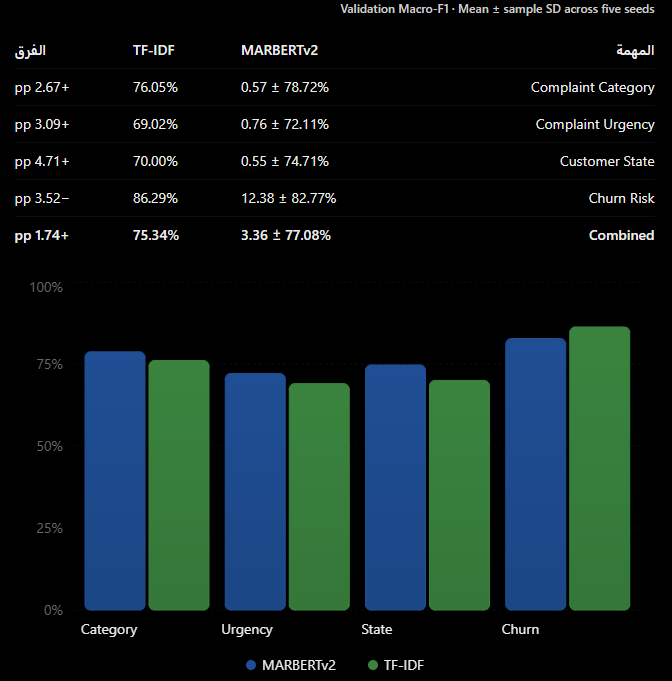

In [119]:

# ============================================================
# MARBERTv2 — PREPARE GITHUB DELIVERY
# 9 FILES | COPY ONLY | NO OVERWRITE | NO PUSH
# ============================================================

from pathlib import Path
import shutil
import hashlib

RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOT = Path("/content/drive/MyDrive/SVR_NEW")

ARTIFACTS = (
    ROOT / "marbertv2-final-artifacts"
    / f"exp_{RUN_ID}"
)

CODE = ROOT / "phase2-code/notebooks/training"

DELIVERY = (
    ROOT / "marbertv2-github-delivery"
    / RUN_ID
)

SEEDS = [42, 1337, 2023, 7, 99]

sources = {
    "run_record.json": ARTIFACTS / "run_record.json",
    **{
        f"predictions_val_seed{s}.json":
        ARTIFACTS / f"predictions_val_seed{s}.json"
        for s in SEEDS
    },
    "marbertv2_phase2.py": CODE / "marbertv2_phase2.py",
    "marbertv2_artifacts.py": CODE / "marbertv2_artifacts.py",
    "marbertv2_colab.ipynb": CODE / "marbertv2_colab.ipynb",
}

assert len(sources) == 9

# Verify all source files before creating the delivery folder.
for name, path in sources.items():
    assert path.is_file(), f"Missing source: {path}"
    assert path.stat().st_size > 0, f"Empty source: {name}"

# Prevent overwriting an existing delivery.
if DELIVERY.exists():
    raise FileExistsError(
        f"Delivery folder already exists: {DELIVERY}"
    )

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

DELIVERY.mkdir(parents=True)

for name, src in sources.items():
    dst = DELIVERY / name

    shutil.copy2(src, dst)

    assert sha256(src) == sha256(dst), (
        f"SHA256 mismatch: {name}"
    )

    print("READY:", name)

print("\n" + "=" * 65)
print("GITHUB DELIVERY PREPARED")
print("=" * 65)
print("Files:", len(sources), "/9")
print("Folder:", DELIVERY)
print("All SHA256 hashes matched.")
print("No original files modified.")
print("No GitHub push executed.")


READY: run_record.json
READY: predictions_val_seed42.json
READY: predictions_val_seed1337.json
READY: predictions_val_seed2023.json
READY: predictions_val_seed7.json
READY: predictions_val_seed99.json
READY: marbertv2_phase2.py
READY: marbertv2_artifacts.py
READY: marbertv2_colab.ipynb

GITHUB DELIVERY PREPARED
Files: 9 /9
Folder: /content/drive/MyDrive/SVR_NEW/marbertv2-github-delivery/marbertv2-lr2e5-clean-20261119
All SHA256 hashes matched.
No original files modified.
No GitHub push executed.


In [122]:
import os

print("Real path:", os.path.realpath("/content/drive/MyDrive"))
print("Is mount:", os.path.ismount("/content/drive"))

Real path: /content/drive/MyDrive
Is mount: True


In [123]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import hashlib

RUN_ID = "marbertv2-lr2e5-clean-20261119"

SOURCE = (
    Path("/content/drive/MyDrive/SVR_NEW")
    / "marbertv2-github-delivery"
    / RUN_ID
)

SEEDS = [42, 1337, 2023, 7, 99]

NAMES = [
    "run_record.json",
    *[f"predictions_val_seed{s}.json" for s in SEEDS],
    "marbertv2_phase2.py",
    "marbertv2_artifacts.py",
    "marbertv2_colab.ipynb",
]

ZIP_PATH = Path("/content") / f"{RUN_ID}-github-delivery.zip"

assert len(NAMES) == 9
assert SOURCE.is_dir(), "Delivery folder not found"
assert not ZIP_PATH.exists(), "ZIP already exists; refusing overwrite"

for name in NAMES:
    path = SOURCE / name
    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty: {name}"
    )

with ZipFile(ZIP_PATH, "x", ZIP_DEFLATED) as archive:
    for name in NAMES:
        archive.write(SOURCE / name, arcname=name)

with ZipFile(ZIP_PATH, "r") as archive:
    assert archive.testzip() is None, "ZIP integrity failed"
    assert set(archive.namelist()) == set(NAMES), (
        "ZIP contents mismatch"
    )

    for name in NAMES:
        original_hash = hashlib.sha256(
            (SOURCE / name).read_bytes()
        ).hexdigest()

        zipped_hash = hashlib.sha256(
            archive.read(name)
        ).hexdigest()

        assert original_hash == zipped_hash, (
            f"Hash mismatch: {name}"
        )

print("BACKUP READY")
print("Files verified:", len(NAMES), "/9")
print("ZIP size:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")
print("No original files modified.")

files.download(str(ZIP_PATH))


BACKUP READY
Files verified: 9 /9
ZIP size: 1.07 MB
No original files modified.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [127]:

# ============================================================
# MARBERTv2 | INTERACTIVE VALIDATION RESULTS DASHBOARD
# READ ONLY | NO TRAINING | NO TEST SET
# Source: official validation_summary.md
# ============================================================

from pathlib import Path
from IPython.display import display, HTML
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import re


# Official finalized MARBERTv2 validation run
RUN_ID = "marbertv2-lr2e5-clean-20261119"

ROOT = (
    Path("/content/drive/MyDrive/SVR_NEW")
    / "marbertv2-final-artifacts"

    / f"exp_{RUN_ID}"
)

REPORT = ROOT / "validation_summary.md"

assert REPORT.is_file(), (
    f"Official validation report not found: {REPORT}"
)

print("Official run:", RUN_ID)
print("Report:", REPORT)


REPORT = ROOT / "validation_summary.md"

if not REPORT.is_file():
    raise FileNotFoundError(
        f"Official validation report not found: {REPORT}"
    )

report = REPORT.read_text(encoding="utf-8")

TASK_NAMES = {
    "complaint_category": "Complaint Category",
    "complaint_urgency": "Complaint Urgency",
    "customer_state": "Customer State",
    "churn_risk": "Churn Risk",
    "combined": "Combined"
}

SEEDS = ["42", "1337", "2023", "7", "99"]

def parse_md_table(lines, start):
    """Parse a Markdown table beginning at a header line."""
    rows = []
    for line in lines[start:]:
        if not line.strip().startswith("|"):
            break
        cells = [x.strip() for x in line.strip().strip("|").split("|")]
        if all(re.fullmatch(r"[:\-\s]+", c or "-") for c in cells):
            continue
        rows.append(cells)

    if len(rows) < 2:
        raise ValueError("Invalid Markdown table")

    width = len(rows[0])
    if any(len(r) != width for r in rows):
        raise ValueError("Inconsistent Markdown table columns")

    return pd.DataFrame(rows[1:], columns=rows[0])

lines = report.splitlines()

# ------------------------------------------------------------
# 1. Parse official comparison table
# ------------------------------------------------------------

summary = None

for i, line in enumerate(lines):
    if line.startswith("| Field |"):
        summary = parse_md_table(lines, i)
        break

if summary is None:
    raise ValueError("Official comparison table not found")

numeric_cols = [
    *SEEDS, "Mean", "Sample SD", "TF-IDF", "Delta"
]

for col in numeric_cols:
    summary[col] = pd.to_numeric(
        summary[col].str.replace("+", "", regex=False),
        errors="raise"
    )

summary["Task"] = summary["Field"].map(TASK_NAMES)

if summary["Task"].isna().any():
    raise ValueError("Unknown task in official report")

expected = set(TASK_NAMES)
if set(summary["Field"]) != expected:
    raise ValueError("Unexpected or missing tasks")

# Independent verification of reported seed statistics.
for _, r in summary.iterrows():
    values = r[SEEDS].to_numpy(dtype=float)

    if abs(values.mean() - r["Mean"]) > 0.00015:
        raise ValueError(f"Mean mismatch: {r['Field']}")

    if abs(values.std(ddof=1) - r["Sample SD"]) > 0.00015:
        raise ValueError(f"SD mismatch: {r['Field']}")

    if abs(
        (r["Mean"] - r["TF-IDF"]) - r["Delta"]
    ) > 0.00015:
        raise ValueError(f"Delta mismatch: {r['Field']}")

# ------------------------------------------------------------
# 2. Parse official confusion matrices and class metrics
# ------------------------------------------------------------

sections = {}

for task in list(TASK_NAMES)[:-1]:
    heading = f"### {task}"

    positions = [
        i for i, line in enumerate(lines)
        if line.strip() == heading
    ]

    if len(positions) != 1:
        raise ValueError(f"Section not found: {task}")

    start = positions[0]
    end = next(
        (
            i for i in range(start + 1, len(lines))
            if lines[i].startswith("### ")
            or lines[i].startswith("## ")
        ),
        len(lines)
    )

    section_lines = lines[start:end]
    tables = []

    for j, line in enumerate(section_lines):
        if line.startswith("| Actual / predicted |"):
            tables.append(("confusion", parse_md_table(section_lines, j)))
        elif line.startswith("| Class | Precision |"):
            tables.append(("classes", parse_md_table(section_lines, j)))

    found = dict(tables)

    if set(found) != {"confusion", "classes"}:
        raise ValueError(f"Incomplete metrics for {task}")

    cm = found["confusion"].copy()
    cm = cm.set_index("Actual / predicted")
    cm = cm.apply(pd.to_numeric, errors="raise")

    classes = found["classes"].copy()
    for c in ["Precision", "Recall", "F1", "Support"]:
        classes[c] = pd.to_numeric(classes[c], errors="raise")

    if list(cm.index) != list(cm.columns):
        raise ValueError(f"Class order mismatch: {task}")

    if int(cm.to_numpy().sum()) != int(classes["Support"].sum() * 5):
        raise ValueError(f"Confusion matrix count mismatch: {task}")

    sections[task] = {
        "cm": cm,
        "classes": classes
    }

# ------------------------------------------------------------
# 3. Dashboard header
# ------------------------------------------------------------

display(HTML("""
<div style="
    background:#111827;
    color:white;
    padding:28px;
    border-radius:18px;
    font-family:Arial,sans-serif;
    margin:12px 0 22px 0;
">
  <div style="font-size:13px;color:#93c5fd;letter-spacing:2px">
    SVR • EXPERIMENTAL RESEARCH
  </div>
  <h1 style="margin:12px 0;font-size:30px">
    MARBERTv2 | Validation Dashboard
  </h1>
  <p style="color:#cbd5e1;margin:0">
    4 classification tasks · 5 random seeds · 20 completed runs
  </p>
  <p style="color:#93c5fd;margin-top:14px;font-size:13px">
    Official finalized results • Validation only • No test access
  </p>
</div>
"""))

# ------------------------------------------------------------
# 4. Task comparison against TF-IDF
# ------------------------------------------------------------

tasks = summary[summary["Field"] != "combined"].copy()

fig = go.Figure()

fig.add_trace(go.Bar(
    name="MARBERTv2",
    x=tasks["Task"],
    y=tasks["Mean"] * 100,
    error_y=dict(
        type="data",
        array=tasks["Sample SD"] * 100,
        visible=True
    ),
    marker_color="#2563eb",
    text=[f"{x:.2f}%" for x in tasks["Mean"] * 100],
    textposition="outside"
))

fig.add_trace(go.Bar(
    name="TF-IDF Baseline",
    x=tasks["Task"],
    y=tasks["TF-IDF"] * 100,
    marker_color="#94a3b8",
    text=[f"{x:.2f}%" for x in tasks["TF-IDF"] * 100],
    textposition="outside"
))

fig.update_layout(
    title="01 | MARBERTv2 vs TF-IDF Baseline",
    barmode="group",
    yaxis=dict(title="Validation Macro-F1 (%)", range=[0, 105]),
    template="plotly_white",
    height=510,
    legend=dict(orientation="h", y=1.13)
)

fig.show()

print(
    "HOW TO READ: Higher Macro-F1 is better. "
    "Error bars show sample SD across five seeds, "
    "not confidence intervals."
)

# ------------------------------------------------------------
# 5. Seed-by-seed performance
# ------------------------------------------------------------

seed_matrix = tasks.set_index("Task")[SEEDS] * 100

fig = go.Figure(go.Heatmap(
    z=seed_matrix.values,
    x=[f"Seed {s}" for s in SEEDS],
    y=seed_matrix.index,
    text=np.round(seed_matrix.values, 2),
    texttemplate="%{text:.2f}%",
    colorscale="Blues",
    zmin=0,
    zmax=100,
    colorbar=dict(title="F1 %")
))

fig.update_layout(
    title="02 | Performance Across Random Seeds",
    template="plotly_white",
    height=410,
    xaxis_title="Random seed",
    yaxis_title=""
)

fig.show()

print(
    "HOW TO READ: Compare values horizontally. "
    "Large differences across seeds indicate instability."
)

# ------------------------------------------------------------
# 6. Stability analysis
# ------------------------------------------------------------

fig = go.Figure(go.Bar(
    x=tasks["Task"],
    y=tasks["Sample SD"] * 100,
    marker_color=[
        "#dc2626" if v > 0.05 else "#2563eb"
        for v in tasks["Sample SD"]
    ],
    text=[
        f"{v * 100:.2f} pp"
        for v in tasks["Sample SD"]
    ],
    textposition="outside"
))

fig.update_layout(
    title="03 | Training Stability — Sample SD",
    yaxis_title="Standard deviation (percentage points)",
    template="plotly_white",
    height=430
)

fig.show()

print(
    "HOW TO READ: Lower SD means more consistent "
    "validation results across seeds. "
    "Red is a visual flag for SD above 5 percentage points, "
    "not an official statistical threshold."
)

# ------------------------------------------------------------
# 7. Interactive confusion matrix selector
# ------------------------------------------------------------

fig = go.Figure()
buttons = []

for index, (task, data) in enumerate(sections.items()):
    cm = data["cm"]
    z = cm.values

    # Row-normalize to show recall by actual class.
    row_totals = z.sum(axis=1, keepdims=True)
    normalized = np.divide(
        z, row_totals,
        out=np.zeros_like(z, dtype=float),
        where=row_totals != 0
    ) * 100

    fig.add_trace(go.Heatmap(
        z=normalized,
        x=list(cm.columns),
        y=list(cm.index),
        customdata=z,
        hovertemplate=(
            "Actual: %{y}<br>"
            "Predicted: %{x}<br>"
            "Row percentage: %{z:.1f}%<br>"
            "Count across 5 seeds: %{customdata}"
            "<extra></extra>"
        ),
        colorscale="Blues",
        zmin=0,
        zmax=100,
        visible=(index == 0),
        colorbar=dict(title="Row %")
    ))

    visible = [False] * len(sections)
    visible[index] = True

    buttons.append(dict(
        label=TASK_NAMES[task],
        method="update",
        args=[
            {"visible": visible},
            {"title": f"04 | Confusion Matrix — {TASK_NAMES[task]}"}
        ]
    ))

fig.update_layout(
    title="04 | Confusion Matrix — Complaint Category",
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        x=0,
        y=1.20,
        showactive=True
    )],
    xaxis_title="Predicted class",
    yaxis_title="Actual class",
    template="plotly_white",
    height=650,
    margin=dict(t=130, b=150)
)

fig.show()

print(
    "HOW TO READ: The diagonal represents correct predictions. "
    "Off-diagonal cells are classification errors. "
    "Percentages are normalized by actual class; "
    "hover to see pooled counts across five seeds."
)

# ------------------------------------------------------------
# 8. Per-class F1 explorer
# ------------------------------------------------------------

class_rows = []

for task, data in sections.items():
    df = data["classes"].copy()
    df["Task"] = TASK_NAMES[task]
    class_rows.append(df)

class_df = pd.concat(class_rows, ignore_index=True)

fig = px.bar(
    class_df,
    x="Class",
    y="F1",
    color="Task",
    facet_row="Task",
    hover_data=["Precision", "Recall", "Support"],
    title="05 | Per-Class F1 — Strengths and Weaknesses",
    height=1050
)

fig.update_yaxes(range=[0, 1])
fig.update_layout(template="plotly_white")
fig.for_each_annotation(
    lambda a: a.update(text=a.text.split("=")[-1])
)
fig.update_xaxes(tickangle=35)
fig.show()

print(
    "HOW TO READ: Lower class F1 identifies classes "
    "that need closer error analysis. "
    "Support is the number of validation examples per seed."
)

# ------------------------------------------------------------
# 9. Research summary
# ------------------------------------------------------------

combined = summary.loc[
    summary["Field"] == "combined"
].iloc[0]

improved = tasks[tasks["Delta"] > 0]
declined = tasks[tasks["Delta"] < 0]
least_stable = tasks.loc[tasks["Sample SD"].idxmax()]
lowest_f1 = class_df.loc[class_df["F1"].idxmin()]

display(HTML(f"""
<div style="
    border:1px solid #cbd5e1;
    padding:24px;
    border-radius:16px;
    font-family:Arial,sans-serif;
    line-height:1.8;
">
  <h2 style="margin-top:0">Research Interpretation</h2>

  <p><b>Combined validation Macro-F1:</b>
  {combined['Mean']:.2%} ± {combined['Sample SD']:.2%}</p>

  <p><b>Tasks above reference TF-IDF:</b>
  {len(improved)} of 4</p>

  <p><b>Tasks below reference TF-IDF:</b>
  {len(declined)} of 4</p>

  <p><b>Least stable task:</b>
  {TASK_NAMES[least_stable['Field']]}
  (SD = {least_stable['Sample SD']*100:.2f} percentage points)</p>

  <p><b>Lowest mean per-class F1:</b>
  {lowest_f1['Class']} in {lowest_f1['Task']}
  (F1 = {lowest_f1['F1']:.2%})</p>

  <p style="color:#475569">
  Results describe validation performance only.
  The TF-IDF comparison is descriptive, not a significance test.
  No claim of independent test performance is made.
  </p>
</div>
"""))

print("\nDASHBOARD READY")
print("Official report:", REPORT)
print("No files modified.")
print("No training performed.")
print("No test data accessed.")


Official run: marbertv2-lr2e5-clean-20261119
Report: /content/drive/MyDrive/SVR_NEW/marbertv2-final-artifacts/exp_marbertv2-lr2e5-clean-20261119/validation_summary.md


HOW TO READ: Higher Macro-F1 is better. Error bars show sample SD across five seeds, not confidence intervals.


HOW TO READ: Compare values horizontally. Large differences across seeds indicate instability.


HOW TO READ: Lower SD means more consistent validation results across seeds. Red is a visual flag for SD above 5 percentage points, not an official statistical threshold.


HOW TO READ: The diagonal represents correct predictions. Off-diagonal cells are classification errors. Percentages are normalized by actual class; hover to see pooled counts across five seeds.


HOW TO READ: Lower class F1 identifies classes that need closer error analysis. Support is the number of validation examples per seed.



DASHBOARD READY
Official report: /content/drive/MyDrive/SVR_NEW/marbertv2-final-artifacts/exp_marbertv2-lr2e5-clean-20261119/validation_summary.md
No files modified.
No training performed.
No test data accessed.


In [125]:

from pathlib import Path
from google.colab import files
import json

RUN_ID = "marbertv2-lr2e5-clean-20261119"

CONFIG_PATH = (
    Path("/content/SVR_MARBERTv2_FINALIZE_WORK")
    / "runs"
    / f"exp_{RUN_ID}"
    / "config.json"
)

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(CONFIG_PATH)

config = json.loads(
    CONFIG_PATH.read_text(encoding="utf-8")
)

assert config["model"] == "UBC-NLP/MARBERTv2"
assert config["learning_rate"] == 2e-5
assert config["epochs"] == 3

print("OFFICIAL MARBERTv2 CONFIGURATION")
print("RUN:", RUN_ID)
print(json.dumps(config, indent=2, ensure_ascii=False))

# Download only — original file remains unchanged.
files.download(str(CONFIG_PATH))


OFFICIAL MARBERTv2 CONFIGURATION
RUN: marbertv2-lr2e5-clean-20261119
{
  "model": "UBC-NLP/MARBERTv2",
  "dataset_version": "v2",
  "split": "train",
  "learning_rate": 2e-05,
  "batch_size": 16,
  "epochs": 3,
  "other_hyperparameters": {
    "model_revision": "a2a02c120b294eec3f1298e4cb5a8b111c7e3de8",
    "max_seq_len": 128,
    "optimizer": "AdamW",
    "scheduler": "linear",
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "dropout": 0.1,
    "gradient_clip_norm": 1.0,
    "early_stopping_patience": 2,
    "precision": "fp16_amp",
    "churn_weight_cap": 20,
    "weights_blob": "6a1c1e069fdfd7341e699b4658c20220a9576438",
    "train_blob": "2e9a58d5c988f2253a12c0d46e3f43a2b55be0c7",
    "validation_blob": "b1adfcc118a766a44bdc1fbe60f372829b2dc720",
    "input_column": "text_norm",
    "tasks": [
      "complaint_category",
      "complaint_urgency",
      "customer_state",
      "churn_risk"
    ],
    "architecture": "single_task"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

*HELLO*  Team, THERE IS A Technical Note I WANT TO SHARE WITH — Python Compatibility & Configuration Safety

During the infrastructure review, two potential compatibility and reproducibility issues were identified in `training_pipeline_skeleton.ipynb`:

1. Python 3.11 Compatibility (Cell 9)

An f-string containing nested double quotation marks may raise a `SyntaxError` under Python 3.11.

Original:
```python
f"Row {i}: {row["text_norm"][:60]}..."
```

Python 3.11-compatible version:
```python
f"Row {i}: {row['text_norm'][:60]}..."
```

2. Shared Configuration Protection (Cell 1)

The notebook contains logic that may rewrite the shared configuration file. This should be reviewed to ensure that frozen experimental settings are not unintentionally overwritten.

Impact on MARBERTv2:

These observations do not establish that the finalized MARBERTv2 results were affected. The 20 training runs and official validation finalization completed successfully.

**Recommendation:** Verify Python 3.11 compatibility and protect frozen configuration files from unintended modification to maintain reproducibility and OFAT (One Factor at a Time) compliance.

Status: Infrastructure review note — not evidence of a training failure.